# Formula 1 Podium Prediction — Milestone 1

**Goal:** for every driver in every race, predict whether they finish on the podium (top 3),
using only information available **after qualifying and before the race starts**.

**Notebook map**
1. Setup & loading
2. Data audit & EDA before cleaning
3. Cleaning
4. EDA after cleaning
5. Data-engineering questions Q1–Q3
6. Feature engineering (leakage-safe)
7. Train / validation / test split
8. Preprocessing & preprocessing-order experiments
9. Models
10. Feature-group ablation
11. Explainability (XAI)
12. Inference function
13. Summary and limitations

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    """Save the current figure into figures/ so it can go into the report."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")

Matplotlib is building the font cache; this may take a moment.


In [3]:
def find_data_dir():
    """Kaggle input folder first, then local folders, so the same notebook runs in both places."""
    # 1) Kaggle paths
    hits = glob.glob("/kaggle/input/**/races.csv", recursive=True)

    # 2) Common local folder names
    local_roots = ["data", "dataset f1", "F1 dataset", "."]
    hits += [os.path.join(d, "races.csv") for d in local_roots
             if os.path.exists(os.path.join(d, "races.csv"))]

    # 3) Local recursive fallback
    if not hits:
        hits += glob.glob("**/races.csv", recursive=True)

    if not hits:
        raise FileNotFoundError(
            "races.csv not found. Put CSV files in one folder (for example: data/, dataset f1/, or F1 dataset/)."
        )

    # Prefer a directory that contains the core files we need.
    for candidate in hits:
        folder = os.path.dirname(candidate)
        needed = ["races.csv", "results.csv", "qualifying.csv"]
        if all(os.path.exists(os.path.join(folder, name)) for name in needed):
            return folder

    return os.path.dirname(hits[0])

DATA_DIR = find_data_dir()
print("Data folder:", DATA_DIR)

Data folder: F1 dataset


In [3]:
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings",
          "drivers", "driver_standings", "races", "results", "qualifying",
          "lap_times", "pit_stops", "sprint_results", "seasons", "status"]

raw = {t: pd.read_csv(os.path.join(DATA_DIR, f"{t}.csv"), keep_default_na=False, dtype=str)
       for t in TABLES}

pd.DataFrame({"rows": {t: len(df) for t, df in raw.items()},
              "columns": {t: df.shape[1] for t, df in raw.items()}})

,rows,columns
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


In [4]:
MAX_YEAR = 2024
race_years = raw["races"]["year"].astype(int)
keep_race_ids = set(raw["races"].loc[race_years <= MAX_YEAR, "raceId"])

before = {t: len(df) for t, df in raw.items()}
raw["races"]   = raw["races"][race_years <= MAX_YEAR].copy()
raw["seasons"] = raw["seasons"][raw["seasons"]["year"].astype(int) <= MAX_YEAR].copy()
for t, df in raw.items():
    if "raceId" in df.columns and t != "races":
        raw[t] = df[df["raceId"].isin(keep_race_ids)].copy()

removed = {t: before[t] - len(raw[t]) for t in TABLES if before[t] != len(raw[t])}
print("Seasons:", raw["races"]["year"].astype(int).min(), "to", raw["races"]["year"].astype(int).max())
print("Rows removed (after 2024):", removed if removed else "none")

Seasons: 1950 to 2024
Rows removed (after 2024): none


## 2. Data audit & EDA before cleaning
We inspect the raw data before changing anything, so every cleaning step has evidence behind it.

### 2.1 How many missing placeholders (`\N`) are there?
The dataset marks missing values with the text `\N` (a *sentinel*). We count them per column.

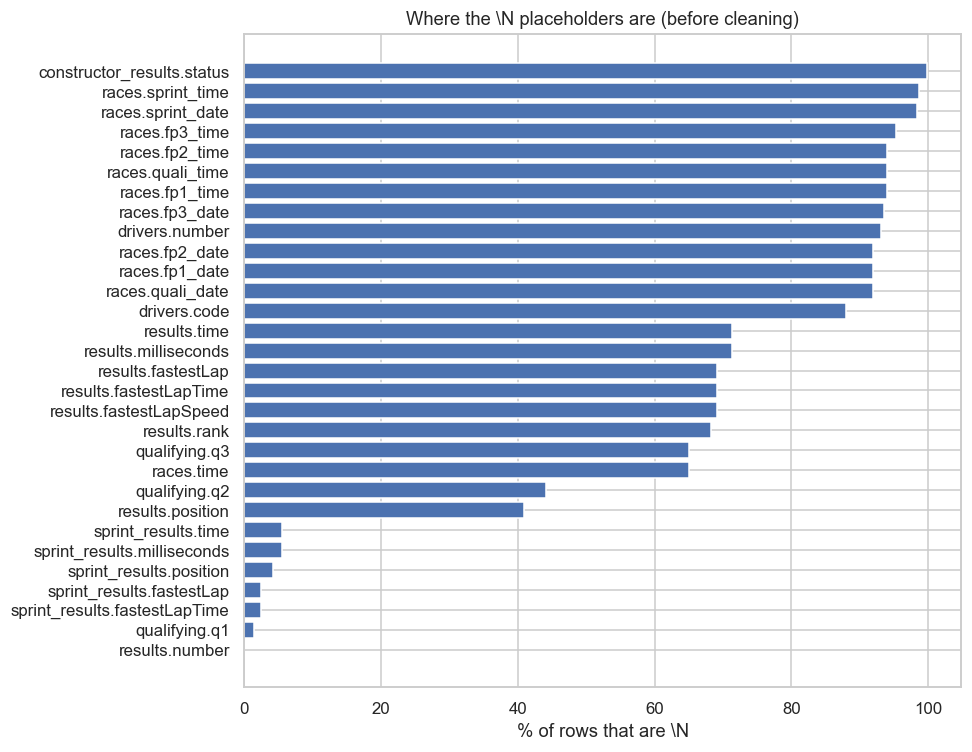

n_sentinel        pct
constructor_results status             12608  99.865347
races               sprint_time         1110  98.666667
                    sprint_date         1107  98.400000
                    fp3_time            1072  95.288889
                    fp2_time            1057  93.955556
                    quali_time          1057  93.955556
                    fp1_time            1057  93.955556
                    fp3_date            1053  93.600000
drivers             number               802  93.147503
races               fp2_date            1035  92.000000
                    fp1_date            1035  92.000000
                    quali_date          1035  92.000000
drivers             code                 757  87.921022
results             time               19079  71.299376
                    milliseconds       19079  71.299376

In [5]:
sentinel = (pd.concat({t: (df == r"\N").sum() for t, df in raw.items()})
              .rename("n_sentinel").to_frame())
sentinel["pct"] = sentinel["n_sentinel"] / sentinel.index.get_level_values(0).map(
    lambda t: len(raw[t])) * 100
sentinel = sentinel[sentinel["n_sentinel"] > 0].sort_values("pct", ascending=False)

fig, ax = plt.subplots(figsize=(9, 7))
labels = [f"{t}.{c}" for t, c in sentinel.index]
ax.barh(labels[::-1], sentinel["pct"][::-1], color="#4C72B0")
ax.set_xlabel("% of rows that are \\N")
ax.set_title("Where the \\N placeholders are (before cleaning)")
save_fig("eda_before_sentinels")
plt.show()
sentinel.head(15)

### 2.2 Quick results view for EDA
To plot things per season we need the year, which lives in `races`. This is our first join:
`results → races` on `raceId`. We only convert the few columns we need, on a copy.

In [6]:
def to_num(s):
    """Convert a raw text column to numbers; the \\N placeholder becomes NaN."""
    return pd.to_numeric(s.replace(r"\N", np.nan), errors="coerce")

eda = raw["results"][["raceId", "driverId", "constructorId", "grid",
                      "positionOrder", "statusId"]].copy()
for c in ["grid", "positionOrder"]:
    eda[c] = to_num(eda[c])
eda = eda.merge(raw["races"][["raceId", "year", "name"]], on="raceId", how="left")
eda["year"] = eda["year"].astype(int)
eda["podium"] = (eda["positionOrder"] <= 3).astype(int)
eda.head()

,raceId,driverId,constructorId,grid,positionOrder,statusId,year,name,podium
0,18,1,1,1,1,1,2008,Australian Grand Prix,1
1,18,2,2,5,2,1,2008,Australian Grand Prix,1
2,18,3,3,7,3,1,2008,Australian Grand Prix,1
3,18,4,4,11,4,1,2008,Australian Grand Prix,0
4,18,5,1,3,5,1,2008,Australian Grand Prix,0


### 2.3 Field size and podium rate per season
How many entrants did a race have, and what share of rows are podiums? This is our class balance.

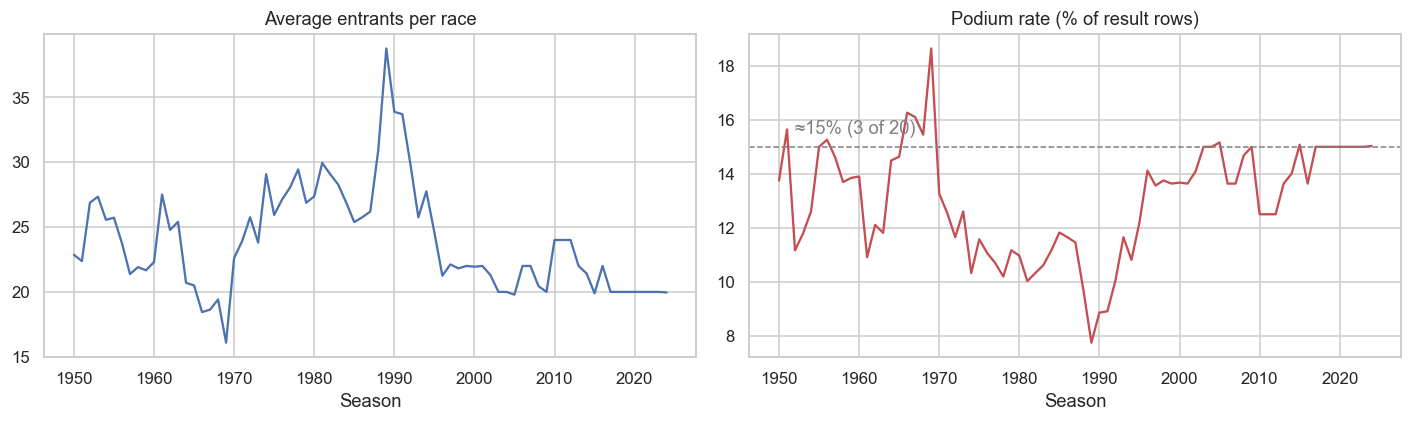

Overall podium rate: 12.7%


,avg_entrants,podium_rate,races
year,,,
1950,22.9,13.8,7
1960,22.3,13.9,10
1970,22.6,13.3,13
1980,27.4,11.0,14
1990,33.9,8.9,16
2000,21.9,13.7,17
2010,24.0,12.5,19
2020,20.0,15.0,17
2024,20.0,15.0,24


In [7]:
per_race = eda.groupby(["year", "raceId"]).size().rename("entrants").reset_index()
season = pd.DataFrame({
    "avg_entrants": per_race.groupby("year")["entrants"].mean(),
    "podium_rate": eda.groupby("year")["podium"].mean() * 100,
    "races": per_race.groupby("year").size(),
})

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(season.index, season["avg_entrants"], color="#4C72B0")
ax[0].set_title("Average entrants per race"); ax[0].set_xlabel("Season")
ax[1].plot(season.index, season["podium_rate"], color="#C44E52")
ax[1].set_title("Podium rate (% of result rows)"); ax[1].set_xlabel("Season")
ax[1].axhline(15, ls="--", c="grey", lw=1); ax[1].text(1952, 15.5, "≈15% (3 of 20)", color="grey")
save_fig("eda_before_field_size_podium_rate")
plt.show()

print(f"Overall podium rate: {eda['podium'].mean():.1%}")
season.loc[[1950, 1960, 1970, 1980, 1990, 2000, 2010, 2020, 2024]].round(1)

### 2.4 Qualifying coverage per season
For what share of result rows does a qualifying record exist? The brief warns about
"historical qualifying-coverage drift".

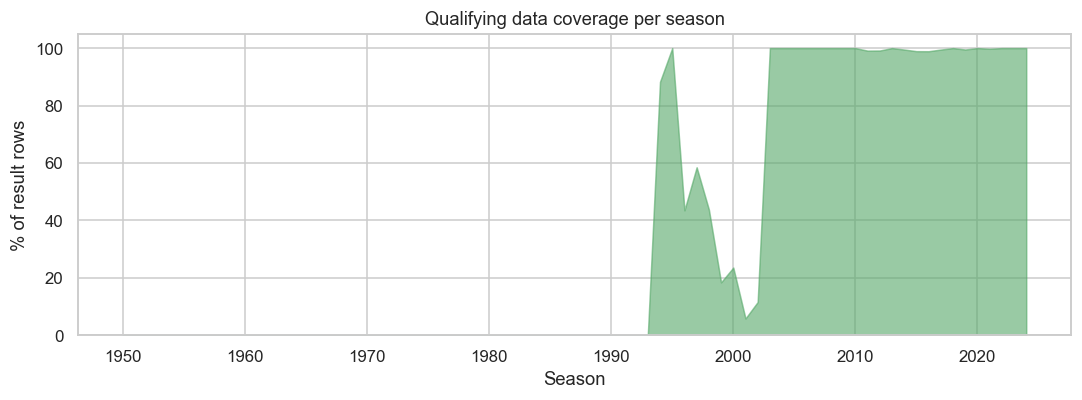

Qualifying coverage is >= 95% in every season from: 2003


year
1992      0.0
1993      0.0
1994     88.0
1995    100.0
1996     44.0
1997     59.0
1998     44.0
1999     18.0
2000     24.0
2001      6.0
2002     12.0
2003    100.0
2004    100.0
Name: has_quali, dtype: float64

In [8]:
quali_keys = raw["qualifying"][["raceId", "driverId"]].drop_duplicates().assign(has_quali=1)
cov = eda.merge(quali_keys, on=["raceId", "driverId"], how="left")
cov["has_quali"] = cov["has_quali"].fillna(0)
coverage = cov.groupby("year")["has_quali"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(coverage.index, coverage.values, color="#55A868", alpha=0.6)
ax.set_ylim(0, 105); ax.set_ylabel("% of result rows")
ax.set_title("Qualifying data coverage per season"); ax.set_xlabel("Season")
save_fig("eda_before_quali_coverage")
plt.show()

full_from = coverage[coverage < 95].index.max() + 1
print("Qualifying coverage is >= 95% in every season from:", full_from)
coverage.loc[1992:2004].round(0)

### 2.5 What does grid = 0 mean?
The F1 guide says grid = 0 should mean a pit-lane start, and asks us to verify it.

In [9]:
status_names = raw["status"].set_index("statusId")["status"]
g0 = eda[eda["grid"] == 0].copy()
g0["status"] = g0["statusId"].map(status_names)

print(f"Rows with grid = 0: {len(g0)} ({len(g0)/len(eda):.1%} of all rows)")
print(f"Podiums from grid = 0: {g0['podium'].sum()}")
g0["status"].value_counts().head(10)

Rows with grid = 0: 1638 (6.1% of all rows)
Podiums from grid = 0: 0


status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Excluded                 6
Name: count, dtype: int64

### 2.6 Duplicate (raceId, driverId) pairs
Our modeling table needs exactly one row per driver per race. Here we only count the problem.

Rows involved in duplicates: 176  |  affected (race, driver) pairs: 85


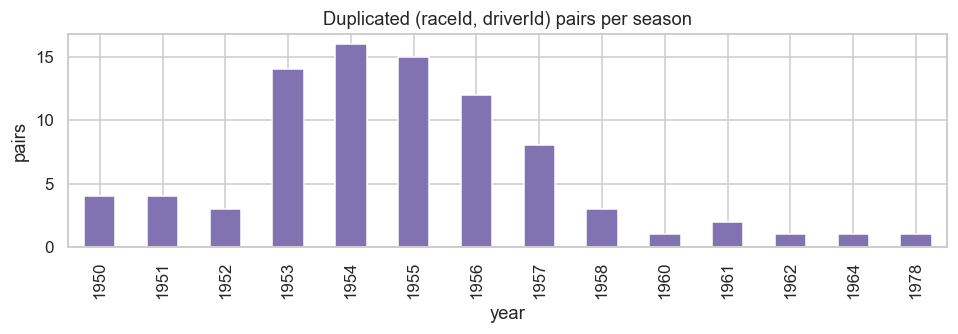

In [10]:
dup_mask = eda.duplicated(["raceId", "driverId"], keep=False)
dups = eda[dup_mask]
print(f"Rows involved in duplicates: {len(dups)}  |  affected (race, driver) pairs: "
      f"{dups.groupby(['raceId','driverId']).ngroups}")

fig, ax = plt.subplots(figsize=(9, 3.2))
dups.groupby("year")[["raceId", "driverId"]].apply(lambda d: d.drop_duplicates().shape[0]) \
    .plot(kind="bar", ax=ax, color="#8172B2")
ax.set_title("Duplicated (raceId, driverId) pairs per season"); ax.set_ylabel("pairs")
save_fig("eda_before_duplicates")
plt.show()

### 2.7 Retirement rate per season
In old eras many cars broke down, so even a front-row starter often failed to finish.

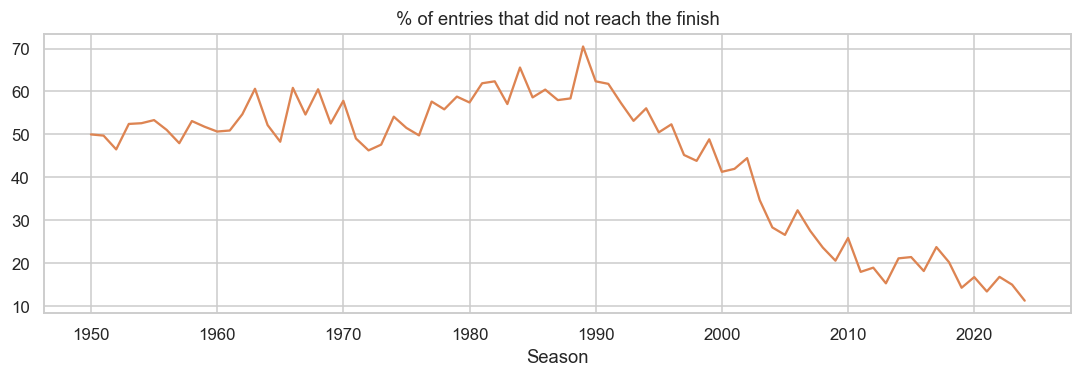

In [11]:
eda["status"] = eda["statusId"].map(status_names)
finished = eda["status"].eq("Finished") | eda["status"].str.match(r"^\+\d+ Laps?$")
eda["finished"] = finished.astype(int)

ret = 100 - eda.groupby("year")["finished"].mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(ret.index, ret.values, color="#DD8452")
ax.set_title("% of entries that did not reach the finish"); ax.set_xlabel("Season")
save_fig("eda_before_retirement_rate")
plt.show()

### 2.8 Summary of the "before" audit

| Finding | Evidence | What we do in cleaning |
|---|---|---|
| `\N` placeholders in many columns | §2.1 | Convert to NaN, keep the rows |
| Imbalanced target (12.7% podiums) | §2.3 | PR-AUC as main metric, class weights later |
| Qualifying missing before 1994, patchy 1996–2002 | §2.4 | Decide training window / imputation |
| `grid = 0` mostly means did not start | §2.5 | Use status to remove non-starters |
| 85 duplicate (race, driver) pairs, mostly 1953–1957 (a few until 1978) | §2.6 | Choose and apply a keep-one rule |
| Very high early retirement rates | §2.7 | Note era sensitivity |

## 3. Cleaning
All cleaning happens on copies (`clean`); the `raw` tables stay untouched.

### 3.1 Sentinels → NaN and numeric typing
Evidence: §2.1 showed `\N` placeholders in many columns. We replace them with real missing values
(NaN) and convert every column that only contains numbers into a numeric type.

In [12]:
clean = {t: df.replace(r"\N", np.nan) for t, df in raw.items()}   # copies; raw is untouched

def auto_numeric(df):
    """Convert every column whose non-missing values are all numbers into a numeric dtype."""
    df = df.copy()
    for c in df.columns:
        converted = pd.to_numeric(df[c], errors="coerce")
        if converted.notna().sum() == df[c].notna().sum():   # nothing was lost -> truly numeric
            df[c] = converted
    return df

clean = {t: auto_numeric(df) for t, df in clean.items()}

check = pd.DataFrame({
    "\\N before": {t: int((raw[t] == r"\N").sum().sum()) for t in TABLES},
    "NaN after":  {t: int(clean[t].isna().sum().sum()) for t in TABLES},
    "\\N left":   {t: int((clean[t].astype(str) == r"\N").sum().sum()) for t in TABLES},
})
check
print("positionOrder dtype:", clean["results"]["positionOrder"].dtype)

positionOrder dtype: int64


### 3.2 Semantic typing: dates and durations
Dates become real date objects; lap-time strings like `1:26.572` become numeric seconds (86.572),
so they can be compared, averaged and used as features.

In [13]:
def time_to_seconds(s):
    """'1:26.572' -> 86.572 ; '49.111' -> 49.111 ; NaN or unreadable -> NaN (and reported)."""
    def one(x):
        if pd.isna(x):
            return np.nan
        try:
            total = 0.0
            for part in str(x).strip().split(":"):
                total = total * 60 + float(part)
            return total
        except ValueError:
            return np.nan
    out = s.map(one)
    bad = int(out.isna().sum() - s.isna().sum())
    if bad:
        print(f"  {s.name}: {bad} value(s) could not be parsed -> NaN")
    return out

DATE_COLS = {"races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
             "drivers": ["dob"]}
DURATION_COLS = {"qualifying": ["q1", "q2", "q3"],
                 "lap_times": ["time"],
                 "results": ["fastestLapTime"],
                 "sprint_results": ["fastestLapTime"],
                 "pit_stops": ["duration"]}

for t, cols in DATE_COLS.items():
    for c in cols:
        clean[t][c] = pd.to_datetime(clean[t][c], errors="coerce")

for t, cols in DURATION_COLS.items():
    for c in cols:
        if c in clean[t].columns:
            clean[t][c + "_s"] = time_to_seconds(clean[t][c])

print(clean["qualifying"][["q1", "q1_s", "q2", "q2_s", "q3", "q3_s"]].dropna().head(3), "\n")
print(clean["races"][["date", "quali_date"]].dtypes, "\n")
print("results dtypes:\n", clean["results"].dtypes.value_counts())

  q2: 22 value(s) could not be parsed -> NaN
  q3: 46 value(s) could not be parsed -> NaN


         q1    q1_s        q2    q2_s        q3    q3_s
0  1:26.572  86.572  1:25.187  85.187  1:26.714  86.714
1  1:26.103  86.103  1:25.315  85.315  1:26.869  86.869
2  1:25.664  85.664  1:25.452  85.452  1:27.079  87.079 

date          datetime64[ns]
quali_date    datetime64[ns]
dtype: object 

results dtypes:
 int64      8
float64    8
object     3
Name: count, dtype: int64


### 3.3 Primary keys are unique and non-null
A primary key is the column (or columns) that identify each row. We check every table.

In [14]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "status": ["statusId"], "seasons": ["year"],
    "results": ["resultId"], "sprint_results": ["resultId"], "qualifying": ["qualifyId"],
    "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
    "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
pk_report = pd.DataFrame([{
    "table": t, "key": " + ".join(k),
    "rows": len(clean[t]),
    "null_keys": int(clean[t][k].isna().any(axis=1).sum()),
    "duplicate_keys": int(clean[t].duplicated(k).sum()),
} for t, k in PRIMARY_KEYS.items()])
pk_report["ok"] = (pk_report["null_keys"] == 0) & (pk_report["duplicate_keys"] == 0)
pk_report

,table,key,rows,null_keys,duplicate_keys,ok
0,circuits,circuitId,77,0,0,True
1,constructors,constructorId,212,0,0,True
2,drivers,driverId,861,0,0,True
3,races,raceId,1125,0,0,True
4,status,statusId,139,0,0,True
5,seasons,year,75,0,0,True
6,results,resultId,26759,0,0,True
7,sprint_results,resultId,360,0,0,True
8,qualifying,qualifyId,10494,0,0,True
9,driver_standings,driverStandingsId,34863,0,0,True


### 3.4 Foreign keys reconcile
A foreign key points to another table (e.g. `results.driverId` → `drivers.driverId`).
Every value must exist in the table it points to; an "orphan" would break our joins.

In [15]:
FOREIGN_KEYS = [  # (child table, column, parent table, parent column)
    ("races", "circuitId", "circuits", "circuitId"),
    ("results", "raceId", "races", "raceId"), ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"), ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"), ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"), ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("driver_standings", "raceId", "races", "raceId"), ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"), ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"), ("pit_stops", "driverId", "drivers", "driverId"),
    ("races", "year", "seasons", "year"),
]
fk_report = pd.DataFrame([{
    "child": f"{ct}.{cc}", "parent": f"{pt}.{pc}",
    "orphans": int((~clean[ct][cc].dropna().isin(clean[pt][pc])).sum()),
} for ct, cc, pt, pc in FOREIGN_KEYS])
print("All foreign keys reconcile:", (fk_report["orphans"] == 0).all())
fk_report

All foreign keys reconcile: True


,child,parent,orphans
0,races.circuitId,circuits.circuitId,0
1,results.raceId,races.raceId,0
2,results.driverId,drivers.driverId,0
3,results.constructorId,constructors.constructorId,0
4,results.statusId,status.statusId,0
5,qualifying.raceId,races.raceId,0
6,qualifying.driverId,drivers.driverId,0
7,qualifying.constructorId,constructors.constructorId,0
8,sprint_results.raceId,races.raceId,0
9,sprint_results.driverId,drivers.driverId,0


### 3.5 Build the base table
One row per result, with the race information (year, round, circuit, date) joined in,
the status as text, and the target `podium = positionOrder <= 3`.

In [16]:
status_map = clean["status"].set_index("statusId")["status"]
base = (clean["results"]
        .merge(clean["races"][["raceId", "year", "round", "circuitId", "name", "date"]],
               on="raceId", how="left", validate="many_to_one"))
base["status"] = base["statusId"].map(status_map)
base["podium"] = (base["positionOrder"] <= 3).astype(int)
print("Base table:", base.shape)

Base table: (26759, 26)


### 3.6 Scope decisions
**(a) Indianapolis 500 (1950–1960) — removed.** It counted for the championship, but almost no F1
regulars entered it and its drivers rarely raced elsewhere. It would inflate American drivers'
race counts and distort the home-race analysis (Q2).

**(b) Non-starters — removed.** Evidence §2.5: most `grid = 0` rows are drivers who never started.
Rule: a row is kept if the driver was on the grid (`grid > 0`) or completed at least one lap
(`laps > 0`), and the status is not "Did not qualify", "Did not prequalify" or "Withdrew".
We predict the outcome of a race the driver actually takes part in, and the starting list is
known before lights out.

**(c) Pit-lane starters — kept and flagged.** `grid = 0` with laps driven = genuine pit-lane start.
We add `pit_lane_start = 1` so the model never reads `grid = 0` as "better than pole".

In [17]:
log = [("start (all result rows)", len(base), int(base["podium"].sum()))]

# (a) Indianapolis 500, 1950-1960
is_indy = base["name"].str.contains("Indianapolis", na=False)
print("Indy 500 races removed:", base.loc[is_indy, "raceId"].nunique(),
      "| seasons:", sorted(base.loc[is_indy, "year"].unique().tolist()))
base = base[~is_indy].copy()
log.append(("drop Indianapolis 500", len(base), int(base["podium"].sum())))

# (b) Non-starters
NON_START = ["Did not qualify", "Did not prequalify", "Withdrew"]
started = ((base["grid"] > 0) | (base["laps"] > 0)) & ~base["status"].isin(NON_START)
print("Non-starters removed:", int((~started).sum()), "| podiums among them:",
      int(base.loc[~started, "podium"].sum()))
print(base.loc[~started, "status"].value_counts().head(8))
base = base[started].copy()
log.append(("drop non-starters", len(base), int(base["podium"].sum())))

# (c) Pit-lane starters: keep, but flag them
base["pit_lane_start"] = (base["grid"] == 0).astype(int)
print("\nPit-lane starters kept:", int(base["pit_lane_start"].sum()))

Indy 500 races removed: 11 | seasons: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960]
Non-starters removed: 1662 | podiums among them: 0
status
Did not qualify       1025
Did not prequalify     331
Withdrew               248
Accident                18
Injury                   8
Engine                   6
Excluded                 6
Disqualified             6
Name: count, dtype: int64

Pit-lane starters kept: 72


### 3.7 Duplicate (raceId, driverId) pairs — shared drives
Evidence §2.6. In a shared drive a driver appears twice in one race: once in the car he started,
once in a teammate's car he took over mid-race. In most pairs **both** rows have `grid > 0`,
because the second car also started (with the teammate), so "keep the non-zero grid row" is not enough.

**Our rule:** keep the row with the **best (lowest) grid slot**; a pit-lane start counts as last;
ties go to the lowest `resultId` (the original entry).

**Why not keep the row with the best finish?** That rule chooses rows by the *outcome*.
It would systematically keep podium rows and inflate the target. Our rule uses only `grid`,
which is known before the race, so the target is never used to choose the data.
The cell below shows the difference.

In [18]:
dup = base[base.duplicated(["raceId", "driverId"], keep=False)]
print(f"Duplicated rows: {len(dup)} | (race, driver) pairs: {dup.groupby(['raceId','driverId']).ngroups}")

rule_grid  = dup.sort_values(["grid", "resultId"]).drop_duplicates(["raceId", "driverId"])
rule_order = dup.sort_values(["positionOrder", "resultId"]).drop_duplicates(["raceId", "driverId"])
print("Podiums kept with BEST GRID rule (pre-race):     ", int(rule_grid["podium"].sum()))
print("Podiums kept with BEST FINISH rule (outcome):    ", int(rule_order["podium"].sum()))

base["grid_sort"] = base["grid"].replace(0, np.inf)    # pit-lane start counts as last
base = (base.sort_values(["raceId", "driverId", "grid_sort", "resultId"])
            .drop_duplicates(["raceId", "driverId"], keep="first")
            .drop(columns="grid_sort"))
log.append(("deduplicate shared drives", len(base), int(base["podium"].sum())))

assert not base.duplicated(["raceId", "driverId"]).any()
print("One row per (raceId, driverId):", not base.duplicated(["raceId", "driverId"]).any())

Duplicated rows: 125 | (race, driver) pairs: 61
Podiums kept with BEST GRID rule (pre-race):      4
Podiums kept with BEST FINISH rule (outcome):     21
One row per (raceId, driverId): True


### 3.8 Cleaning log
Rows and podiums after each step, so the impact of every decision is visible.

In [19]:
cleaning_log = pd.DataFrame(log, columns=["step", "rows", "podiums"])
cleaning_log["rows_removed"] = (-cleaning_log["rows"].diff()).fillna(0).astype(int)
cleaning_log["podium_rate_%"] = (cleaning_log["podiums"] / cleaning_log["rows"] * 100).round(2)
print("Podium rows per race:", base.groupby("raceId")["podium"].sum().value_counts().sort_index().to_dict())
cleaning_log

Podium rows per race: {2: 3, 3: 1109, 4: 1, 5: 1}


,step,rows,podiums,rows_removed,podium_rate_%
0,start (all result rows),26759,3397,0,12.69
1,drop Indianapolis 500,26354,3361,405,12.75
2,drop non-starters,24692,3361,1662,13.61
3,deduplicate shared drives,24628,3342,64,13.57


## 4. EDA after cleaning
We repeat the key checks on the cleaned table and compare them with Section 2,
so the effect of every cleaning step is visible.

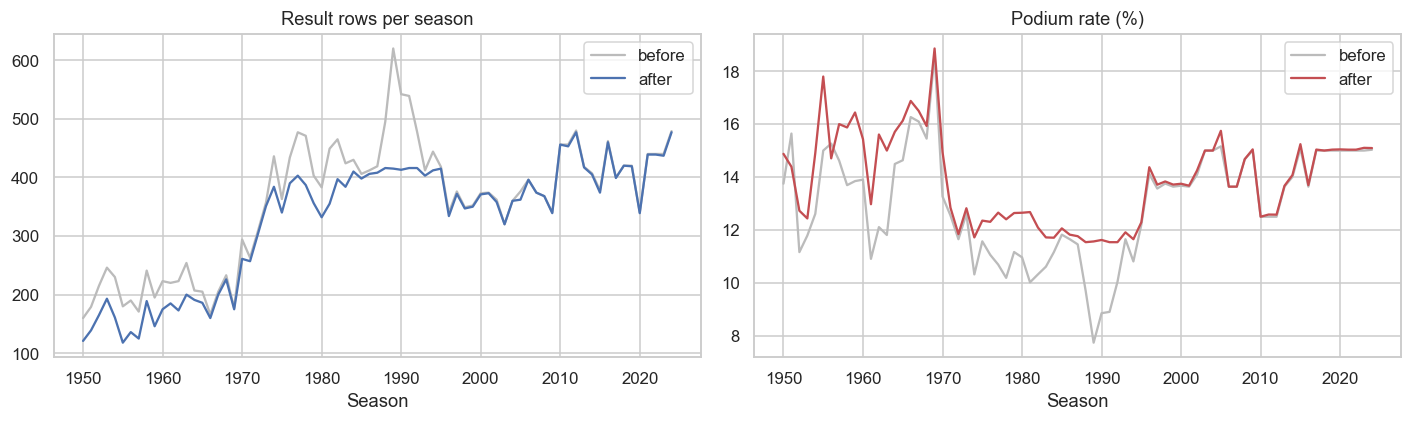

,rows before,rows after,podium % before,podium % after
year,,,,
1950,160,121,13.8,14.9
1955,180,118,15.0,17.8
1960,223,175,13.9,15.4
1980,383,332,11.0,12.7
1989,620,415,7.7,11.6
1990,542,413,8.9,11.6
2000,373,371,13.7,13.7
2024,479,477,15.0,15.1


In [20]:
before_season = eda.groupby("year").agg(rows=("podium", "size"), podium_rate=("podium", "mean"))
after_season  = base.groupby("year").agg(rows=("podium", "size"), podium_rate=("podium", "mean"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(before_season.index, before_season["rows"], label="before", color="#BBBBBB")
ax[0].plot(after_season.index, after_season["rows"], label="after", color="#4C72B0")
ax[0].set_title("Result rows per season"); ax[0].set_xlabel("Season"); ax[0].legend()
ax[1].plot(before_season.index, before_season["podium_rate"] * 100, label="before", color="#BBBBBB")
ax[1].plot(after_season.index, after_season["podium_rate"] * 100, label="after", color="#C44E52")
ax[1].set_title("Podium rate (%)"); ax[1].set_xlabel("Season"); ax[1].legend()
save_fig("eda_after_rows_podium_rate")
plt.show()

cmp = pd.DataFrame({"rows before": before_season["rows"], "rows after": after_season["rows"],
                    "podium % before": (before_season["podium_rate"] * 100).round(1),
                    "podium % after": (after_season["podium_rate"] * 100).round(1)})
cmp.loc[[1950, 1955, 1960, 1980, 1989, 1990, 2000, 2024]]

### 4.2 Grid distribution before vs after

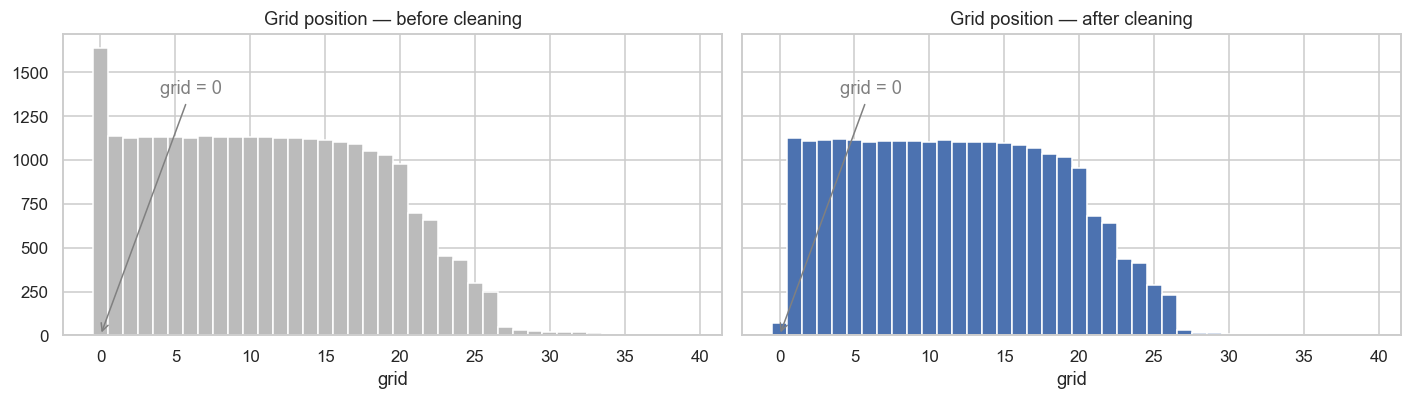

grid = 0 rows: before 1638  ->  after 72 (all are flagged pit-lane starters: 72)


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
bins = np.arange(-0.5, 40.5, 1)
ax[0].hist(eda["grid"], bins=bins, color="#BBBBBB")
ax[0].set_title("Grid position — before cleaning"); ax[0].set_xlabel("grid")
ax[1].hist(base["grid"], bins=bins, color="#4C72B0")
ax[1].set_title("Grid position — after cleaning"); ax[1].set_xlabel("grid")
for a in ax:
    a.annotate("grid = 0", xy=(0, 0), xytext=(4, a.get_ylim()[1] * 0.8),
               arrowprops=dict(arrowstyle="->", color="grey"), color="grey")
save_fig("eda_after_grid_distribution")
plt.show()
print(f"grid = 0 rows: before {int((eda['grid'] == 0).sum())}  ->  after {int((base['grid'] == 0).sum())} "
      f"(all are flagged pit-lane starters: {int(base['pit_lane_start'].sum())})")

### 4.3 Podium rate by starting position
The most important relationship in the project: how often does each grid slot end on the podium?

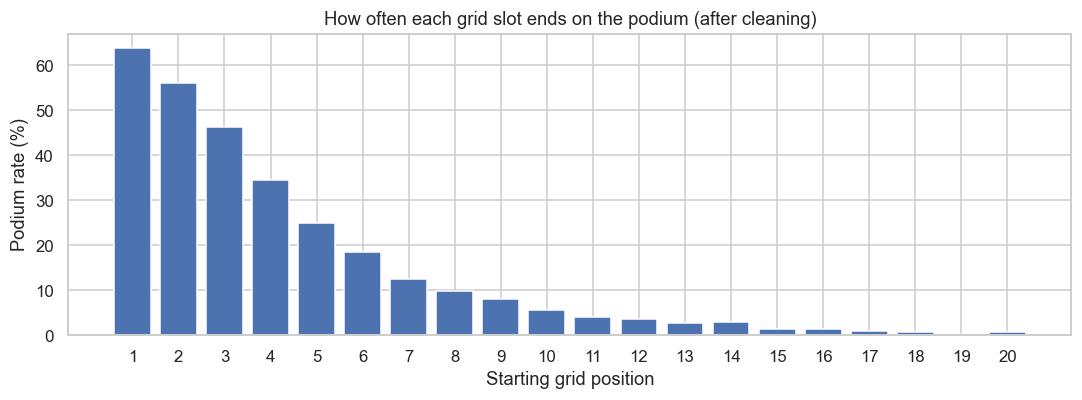

Pit-lane starters: 72 rows, podium rate 0.0%


grid,1,2,3,4,5,6,7,8,9,10
podium_pct,63.8,56.1,46.2,34.6,25.0,18.6,12.6,9.9,8.1,5.7
rows,1123.0,1109.0,1112.0,1117.0,1113.0,1105.0,1109.0,1107.0,1110.0,1103.0


In [22]:
g = base[base["grid"].between(1, 20)].groupby("grid")["podium"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(g.index, g["mean"] * 100, color="#4C72B0")
ax.set_xticks(g.index); ax.set_xlabel("Starting grid position"); ax.set_ylabel("Podium rate (%)")
ax.set_title("How often each grid slot ends on the podium (after cleaning)")
save_fig("eda_after_podium_by_grid")
plt.show()
print(f"Pit-lane starters: {int(base['pit_lane_start'].sum())} rows, "
      f"podium rate {base.loc[base['pit_lane_start'] == 1, 'podium'].mean():.1%}")
(g.assign(podium_pct=(g["mean"] * 100).round(1))[["podium_pct", "size"]]
   .rename(columns={"size": "rows"}).head(10).T)

### 4.4 Typed durations and an outlier rule
Qualifying times are now numeric seconds. Plotting them reveals impossible values, so we add a
rule: a time more than 1.5x the fastest time of that session is a recording error → NaN.

q1_s: 1 impossible time(s) set to NaN ->
      raceId  driverId         q1     q1_s
2567     255        87  16:42.640  1002.64 

q2_s: 1 impossible time(s) set to NaN ->
      raceId  driverId        q2     q2_s
9749    1107       815  2:06.688  126.688 



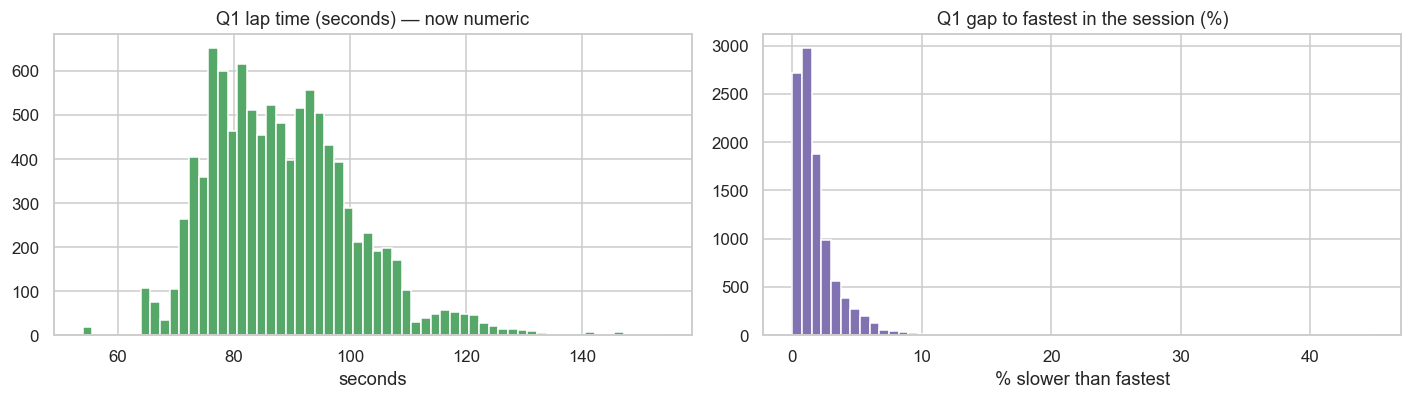

           q1_s     q2_s     q3_s
count  10337.00  5846.00  3629.00
mean      88.44    87.76    87.41
std       12.49    12.10    12.26
min       53.90    53.65    53.38
25%       78.77    77.94    77.24
50%       87.14    87.11    87.04
75%       95.91    95.95    95.63
max      153.88   132.47   129.78


In [23]:
# Outlier rule: a qualifying time more than 1.5x the fastest time of that session is impossible
for c in ["q1_s", "q2_s", "q3_s"]:
    fastest = clean["qualifying"].groupby("raceId")[c].transform("min")
    bad = clean["qualifying"][c] > 1.5 * fastest
    if bad.any():
        print(f"{c}: {int(bad.sum())} impossible time(s) set to NaN ->")
        print(clean["qualifying"].loc[bad, ["raceId", "driverId", c.replace('_s', ''), c]].to_string(), "\n")
    clean["qualifying"].loc[bad, c] = np.nan

q = clean["qualifying"].merge(clean["races"][["raceId", "year"]], on="raceId")
pole = q.groupby("raceId")["q1_s"].transform("min")
q["q1_gap_pct"] = (q["q1_s"] / pole - 1) * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(q["q1_s"].dropna(), bins=60, color="#55A868")
ax[0].set_title("Q1 lap time (seconds) — now numeric"); ax[0].set_xlabel("seconds")
ax[1].hist(q["q1_gap_pct"].dropna(), bins=60, color="#8172B2")
ax[1].set_title("Q1 gap to fastest in the session (%)"); ax[1].set_xlabel("% slower than fastest")
save_fig("eda_after_quali_times")
plt.show()
print(q[["q1_s", "q2_s", "q3_s"]].describe().round(2))

### 4.5 Before vs after summary

In [24]:
summary = pd.DataFrame(dtype=object, data={
    "before": {
        "rows": len(eda),
        "races": eda["raceId"].nunique(),
        "duplicate (race, driver) pairs": eda[eda.duplicated(["raceId", "driverId"], keep=False)]
                                          .groupby(["raceId", "driverId"]).ngroups,
        "grid = 0 rows": int((eda["grid"] == 0).sum()),
        "\\N placeholders in results": int((raw["results"] == r"\N").sum().sum()),
        "podium rate %": round(eda["podium"].mean() * 100, 2),
    },
    "after": {
        "rows": len(base),
        "races": base["raceId"].nunique(),
        "duplicate (race, driver) pairs": int(base.duplicated(["raceId", "driverId"]).sum()),
        "grid = 0 rows": int((base["grid"] == 0).sum()),
        "\\N placeholders in results": int((base.astype(str) == r"\N").sum().sum()),
        "podium rate %": round(base["podium"].mean() * 100, 2),
    },
})
summary

,before,after
rows,26759.0,24628.0
races,1125.0,1114.0
"duplicate (race, driver) pairs",85.0,0.0
grid = 0 rows,1638.0,72.0
\N placeholders in results,122887.0,0.0
podium rate %,12.69,13.57


## 5. Data-engineering questions
Each answer uses multi-hop joins, a plot, and a note on grain, missingness and the pre-race cutoff.

### Q1 — Which circuits convert a front-row start into a podium most often, and does this change after 2014?
**Joins:** `results` (cleaned `base`) → `qualifying` on (raceId, driverId) → `races` → `circuits`.
**Window:** 2003–2024, where qualifying coverage is complete (§2.4); split 2003–2013 vs 2014–2024.
**Front row** is defined twice: by **grid** (where the car started, after penalties) and by
**qualifying position** (before penalties). Circuits need ≥ 10 front-row starts in each period.

In [25]:
quali_pos = clean["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"})
q1 = base.merge(quali_pos, on=["raceId", "driverId"], how="left", validate="one_to_one")
q1 = q1.merge(clean["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}),
              on="circuitId", how="left")

q1 = q1[q1["year"].between(2003, 2024)].copy()          # window where qualifying data is complete (§2.4)
q1["period"] = np.where(q1["year"] < 2014, "2003-2013", "2014-2024")
q1["front_row_grid"]  = q1["grid"].isin([1, 2])
q1["front_row_quali"] = q1["quali_pos"].isin([1, 2])

print("Rows in window:", len(q1), "| missing qualifying position:", int(q1["quali_pos"].isna().sum()))
print("\nQualified on the front row vs actually started on the front row:")
pd.crosstab(q1["front_row_quali"], q1["front_row_grid"],
            rownames=["front row in qualifying"], colnames=["front row on grid"])

Rows in window: 8930 | missing qualifying position: 22

Qualified on the front row vs actually started on the front row:


front row on grid,False,True
front row in qualifying,,
False,8042,36
True,36,816


In [26]:
overall = pd.DataFrame({
    "by grid":       q1[q1["front_row_grid"]].groupby("period")["podium"].mean(),
    "by qualifying": q1[q1["front_row_quali"]].groupby("period")["podium"].mean(),
}) * 100
moved = q1[q1["front_row_quali"] & ~q1["front_row_grid"]]
print(f"Front-row qualifiers who did NOT start on the front row: {len(moved)} "
      f"(podium rate {moved['podium'].mean():.0%}); typical grid: {moved['grid'].median():.0f}")
overall.round(1)

Front-row qualifiers who did NOT start on the front row: 36 (podium rate 31%); typical grid: 7


,by grid,by qualifying
period,,
2003-2013,68.3,67.6
2014-2024,76.0,74.0


In [27]:
MIN_STARTS = 10   # at least 5 races' worth of front-row starts per period

def circuit_conversion(df, flag):
    s = (df[df[flag]].groupby(["circuit", "period"])["podium"]
           .agg(rate="mean", starts="size").reset_index())
    rate = s.pivot(index="circuit", columns="period", values="rate") * 100
    n = s.pivot(index="circuit", columns="period", values="starts")
    both = n.ge(MIN_STARTS).all(axis=1)          # circuits used in BOTH periods
    return rate[both], n[both]

rate_grid, n_grid = circuit_conversion(q1, "front_row_grid")
rate_quali, n_quali = circuit_conversion(q1, "front_row_quali")

from scipy.stats import spearmanr
for label, r in [("grid", rate_grid), ("qualifying", rate_quali)]:
    rho, p = spearmanr(r["2003-2013"], r["2014-2024"])
    print(f"By {label}: {len(r)} circuits in both periods | rank correlation between periods "
          f"rho = {rho:.2f} (p = {p:.2f})")

ranking = rate_grid.round(1).copy()
ranking["rank 2003-2013"] = ranking["2003-2013"].rank(ascending=False, method="min").astype(int)
ranking["rank 2014-2024"] = ranking["2014-2024"].rank(ascending=False, method="min").astype(int)
ranking["rank change"] = ranking["rank 2003-2013"] - ranking["rank 2014-2024"]
ranking["starts (pre/post)"] = n_grid["2003-2013"].astype(int).astype(str) + " / " + n_grid["2014-2024"].astype(int).astype(str)
ranking.sort_values("2014-2024", ascending=False)

By grid: 14 circuits in both periods | rank correlation between periods rho = 0.30 (p = 0.29)
By qualifying: 14 circuits in both periods | rank correlation between periods rho = 0.55 (p = 0.04)


period,2003-2013,2014-2024,rank 2003-2013,rank 2014-2024,rank change,starts (pre/post)
circuit,,,,,,
Suzuka Circuit,72.2,88.9,4,1,3,18 / 18
Yas Marina Circuit,60.0,86.4,10,2,8,10 / 22
Circuit de Monaco,77.3,85.0,1,3,-2,22 / 20
Circuit de Barcelona-Catalunya,68.2,81.8,6,4,2,22 / 22
Circuit de Spa-Francorchamps,72.2,81.8,4,4,0,18 / 22
Autódromo José Carlos Pace,59.1,78.9,12,6,6,22 / 19
Shanghai International Circuit,65.0,78.6,8,7,1,20 / 14
Circuit Gilles Villeneuve,60.0,77.8,10,8,2,20 / 18
Silverstone Circuit,72.7,75.0,3,9,-6,22 / 24


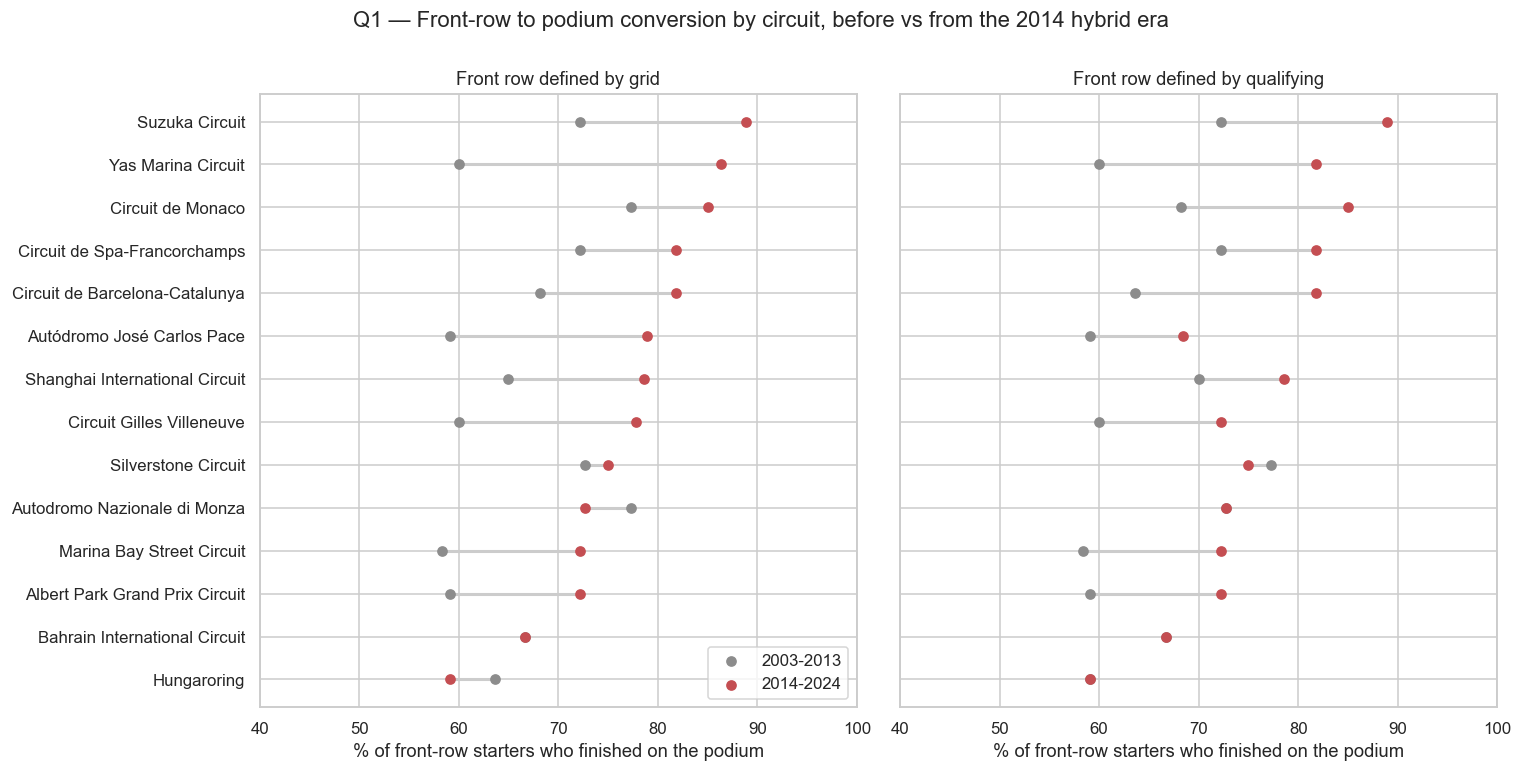

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
order = rate_grid["2014-2024"].sort_values().index
for ax, (label, r) in zip(axes, [("grid", rate_grid), ("qualifying", rate_quali)]):
    r = r.reindex(order)
    y = np.arange(len(r))
    ax.hlines(y, r["2003-2013"], r["2014-2024"], color="#CCCCCC", lw=2)
    ax.scatter(r["2003-2013"], y, color="#8C8C8C", label="2003-2013", zorder=3)
    ax.scatter(r["2014-2024"], y, color="#C44E52", label="2014-2024", zorder=3)
    ax.set_yticks(y); ax.set_yticklabels(r.index)
    ax.set_xlabel("% of front-row starters who finished on the podium")
    ax.set_title(f"Front row defined by {label}")
    ax.set_xlim(40, 100)
axes[0].legend(loc="lower right")
fig.suptitle("Q1 — Front-row to podium conversion by circuit, before vs from the 2014 hybrid era", y=1.0)
save_fig("q1_front_row_conversion")
plt.show()

**Answer Q1.**
- **Most reliable front rows (2014–2024, by grid):** Suzuka (89%), Yas Marina (86%), Monaco (85%),
  Spa and Barcelona (82%). Before 2014 the top were Monaco and Monza (77%), then Silverstone (73%).
- **Does the ranking change? Yes, substantially.** Rank correlation between the periods is only
  ρ = 0.30 by grid (not significant, p = 0.29). Yas Marina rose 8 places and Interlagos 6, while Monza fell 9
  and Silverstone and Bahrain 6. Overall conversion also **rose from 68% to 76%**, consistent with the
  hybrid era being dominated by one or two teams whose front-row cars rarely failed.
- **Grid vs qualifying:** grid converts slightly better (76.0% vs 74.0% after 2014) because it already
  includes penalties. The 36 front-row qualifiers who were moved back started around P7 and only 31% of
  them reached the podium.

**Grain:** one row per driver per race (cleaned `base`); a circuit's rate = podiums ÷ front-row starts.
**Missingness:** 22 of 8,930 rows lack a qualifying position (excluded only from the qualifying definition).
**Cutoff:** grid and qualifying are both known before the race; podium is the outcome being measured.
**Caution:** each circuit has only 10–24 front-row starts per period, so one result moves its rate by
about 4–10 percentage points. Circuit-level differences are descriptive, not proof of a circuit effect.

### Q2 — Do drivers podium more often at home, after controlling for starting position?
**Joins:** `base` → `drivers` (nationality) → `circuits` (country), via `races.circuitId`.
**Home** = the circuit's country matches the driver's nationality (explicit mapping table below).
**Control:** compare home vs away within the same starting-position band, then fit a logistic
regression `podium ~ home + grid band`. Window: all seasons 1950–2024 (Indy 500 already removed).

In [29]:
NAT_TO_COUNTRY = {
    "American": ["USA", "United States"], "American-Italian": ["USA", "United States"],
    "Argentine": ["Argentina"], "Argentinian": ["Argentina"], "Argentine-Italian": ["Argentina"],
    "Australian": ["Australia"], "Austrian": ["Austria"], "Belgian": ["Belgium"],
    "Brazilian": ["Brazil"], "British": ["UK"], "Canadian": ["Canada"], "Chinese": ["China"],
    "Dutch": ["Netherlands"], "East German": ["Germany"], "French": ["France"],
    "German": ["Germany"], "Hungarian": ["Hungary"], "Indian": ["India"], "Italian": ["Italy"],
    "Japanese": ["Japan"], "Malaysian": ["Malaysia"], "Mexican": ["Mexico"],
    "Monegasque": ["Monaco"], "Portuguese": ["Portugal"], "Russian": ["Russia"],
    "South African": ["South Africa"], "Spanish": ["Spain"], "Swedish": ["Sweden"],
    "Swiss": ["Switzerland"],
}   # nationalities with no home race in the data (e.g. Finnish, Danish) simply never get home = 1

drivers = clean["drivers"][["driverId", "nationality"]].copy()
drivers["nationality"] = drivers["nationality"].str.strip()        # fixes "Argentinian " (trailing space)

h = (base.merge(drivers, on="driverId", how="left", validate="many_to_one")
         .merge(clean["circuits"][["circuitId", "country"]], on="circuitId", how="left", validate="many_to_one"))
h["home"] = [c in NAT_TO_COUNTRY.get(n, []) for n, c in zip(h["nationality"], h["country"])]
h["home"] = h["home"].astype(int)

no_home_race = sorted(set(h["nationality"].dropna()) - set(NAT_TO_COUNTRY))
print("Nationalities without a home race in the data:", no_home_race)
print(f"Home rows: {h['home'].sum()} of {len(h)} ({h['home'].mean():.1%})")
h.groupby("home")["podium"].agg(podium_rate="mean", rows="size").round(3)

Nationalities without a home race in the data: ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
Home rows: 1934 of 24628 (7.9%)


,podium_rate,rows
home,,
0,0.137,22694
1,0.116,1934


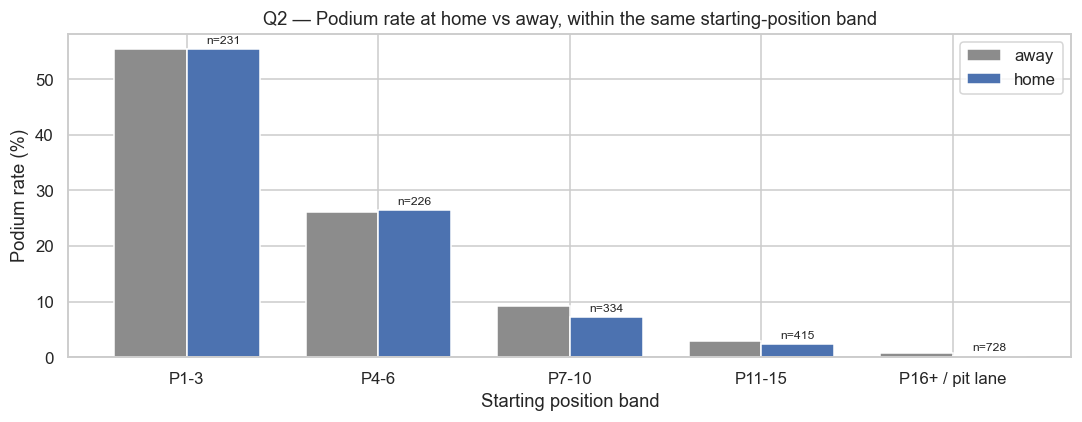

,rate (away),rate (home),rows (away),rows (home),difference (pp)
grid_band,,,,,
P1-3,0.554,0.554,3113,231,-0.002
P4-6,0.261,0.265,3109,226,0.495
P7-10,0.093,0.072,4095,334,-2.070
P11-15,0.030,0.024,5105,415,-0.548
P16+ / pit lane,0.007,0.003,7272,728,-0.454


In [30]:
h["grid_band"] = pd.cut(h["grid"].replace(0, 99), bins=[0, 3, 6, 10, 15, 99],
                        labels=["P1-3", "P4-6", "P7-10", "P11-15", "P16+ / pit lane"])
strat = (h.groupby(["grid_band", "home"], observed=True)["podium"]
           .agg(rate="mean", rows="size").unstack("home"))
strat.columns = [f"{a} ({'home' if b else 'away'})" for a, b in strat.columns]
strat["difference (pp)"] = (strat["rate (home)"] - strat["rate (away)"]) * 100

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(strat)); w = 0.38
ax.bar(x - w/2, strat["rate (away)"] * 100, w, label="away", color="#8C8C8C")
ax.bar(x + w/2, strat["rate (home)"] * 100, w, label="home", color="#4C72B0")
for i, (na, nh) in enumerate(zip(strat["rows (away)"], strat["rows (home)"])):
    ax.text(i + w/2, strat["rate (home)"].iloc[i] * 100 + 1, f"n={nh}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(strat.index)
ax.set_ylabel("Podium rate (%)"); ax.set_xlabel("Starting position band")
ax.set_title("Q2 — Podium rate at home vs away, within the same starting-position band")
ax.legend()
save_fig("q2_home_vs_away_by_grid")
plt.show()
strat.round(3)

In [31]:
import statsmodels.formula.api as smf

career_starts = h.groupby("driverId")["raceId"].transform("size")
models = {
    "all drivers": h,
    "regular drivers (>= 20 starts)": h[career_starts >= 20],
}
rows = []
for name, d in models.items():
    m = smf.logit("podium ~ home + C(grid_band)", data=d).fit(disp=False)
    ci = np.exp(m.conf_int().loc["home"])
    rows.append({"sample": name, "rows": int(m.nobs),
                 "odds ratio (home)": np.exp(m.params["home"]),
                 "95% CI low": ci[0], "95% CI high": ci[1], "p-value": m.pvalues["home"]})
q2_result = pd.DataFrame(rows).set_index("sample").round(3)


**Answer Q2. No — there is no measurable home advantage once starting position is controlled for.**
- Raw rates even suggest the opposite (home 11.6% vs away 13.7%), but that gap comes from *where* home
  drivers start, not from racing at home: many home entries are one-off local drivers starting far back.
- Within each starting band, home and away podium rates are nearly identical (P1–3: 55.4% vs 55.4%;
  differences never exceed ~2 percentage points).
- Logistic regression `podium ~ home + grid band`: odds ratio for home = **0.92** (95% CI 0.78–1.10,
  p = 0.37). The interval contains 1, so no effect can be claimed. Restricting to regular drivers
  (≥ 20 starts) gives the same conclusion (OR 0.95, CI 0.79–1.14).

**Grain:** one row per driver per race. **Joins:** results → drivers (nationality) → races → circuits (country).
**Missingness:** none in the joined columns; 14 nationalities have no home race and are always "away".
**Cutoff:** nationality, circuit and grid are all known before the race.
**Limitations:** nationality ≠ residence (e.g. a Monegasque resident of another nationality counts as away);
"East German" mapped to Germany; one home race per country assumed even when a country hosted two races.
**For modelling:** a `home` feature is unlikely to add predictive value beyond grid.

### Q3 — Which constructors have the highest mechanical-retirement rate, 2014–2021 vs 2022–2024?
**Joins:** `base` (results ← races) → `status` (already mapped) → `constructors`.
**Mechanical** = the car failed (engine, gearbox, hydraulics, brakes, power unit, ...). Excluded:
crashes and driver errors, regulation decisions (DSQ, exclusion), and unknown causes ("Retired").
Ambiguous causes (puncture, wing, wheel, out of fuel) are reported separately as a sensitivity check.
**Rate** = mechanical retirements ÷ race starts, per constructor and period (≥ 40 starts).

In [32]:
import re

MECHANICAL = ["Engine", "Power Unit", "Gearbox", "Brakes", "Suspension", "Hydraulics", "Electrical",
              "Power loss", "Oil leak", "Overheating", "Mechanical", "Water pressure", "Turbo", "ERS",
              "Exhaust", "Battery", "Fuel pressure", "Water leak", "Electronics", "Undertray",
              "Transmission", "Radiator", "Oil pressure", "Technical", "Clutch", "Throttle",
              "Vibrations", "Driveshaft", "Steering", "Fuel leak", "Drivetrain", "Fuel system",
              "Brake duct", "Seat", "Spark plugs", "Fuel pump", "Water pump", "Differential",
              "Cooling system"]
AMBIGUOUS = ["Puncture", "Tyre", "Wheel", "Wheel nut", "Front wing", "Rear wing", "Out of fuel"]
#             a part failed, but often after contact, debris, a pit-stop error or a fuel-strategy call
ACCIDENT_DRIVER = ["Collision", "Accident", "Collision damage", "Spun off", "Damage", "Debris"]
OTHER = ["Disqualified", "Excluded", "Retired", "Illness"]   # regulation decisions / unknown cause

def classify(status):
    if status == "Finished" or re.match(r"^\+\d+ Laps?$", status):
        return "finished"
    if status in AMBIGUOUS:
        return "ambiguous"
    if status in MECHANICAL:
        return "mechanical"
    if status in ACCIDENT_DRIVER:
        return "accident / driver"
    if status in OTHER:
        return "other / regulation"
    return "UNMAPPED"

q3 = base[base["year"].between(2014, 2024)].copy()
q3["period"] = np.where(q3["year"] <= 2021, "2014-2021", "2022-2024")
q3["outcome"] = q3["status"].map(classify)

unmapped = sorted(q3.loc[q3["outcome"] == "UNMAPPED", "status"].unique())
assert not unmapped, f"Statuses still to classify: {unmapped}"
print("Every status in 2014-2024 is classified.\n")
mapping_table = (q3.groupby(["outcome", "status"]).size().rename("count").reset_index()
                   .sort_values(["outcome", "count"], ascending=[True, False]))
print(q3["outcome"].value_counts())
mapping_table[mapping_table["outcome"].isin(["mechanical", "ambiguous", "other / regulation"])]

Every status in 2014-2024 is classified.

outcome
finished              3825
mechanical             378
accident / driver      308
other / regulation      65
ambiguous               32
Name: count, dtype: int64


,outcome,status,count
11,ambiguous,Wheel,11
8,ambiguous,Puncture,7
10,ambiguous,Tyre,4
6,ambiguous,Front wing,3
9,ambiguous,Rear wing,3
12,ambiguous,Wheel nut,3
7,ambiguous,Out of fuel,1
33,mechanical,Engine,80
24,mechanical,Brakes,48
38,mechanical,Gearbox,42


In [33]:
q3 = q3.merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}),
              on="constructorId", how="left")
q3["mech_strict"] = (q3["outcome"] == "mechanical").astype(int)
q3["mech_broad"]  = q3["outcome"].isin(["mechanical", "ambiguous"]).astype(int)

MIN_CONSTRUCTOR_STARTS = 40
rates = (q3.groupby(["period", "constructor"])
           .agg(starts=("raceId", "size"), mech=("mech_strict", "sum"),
                rate_strict=("mech_strict", "mean"), rate_broad=("mech_broad", "mean"))
           .reset_index())
rates = rates[rates["starts"] >= MIN_CONSTRUCTOR_STARTS]
rates[["rate_strict", "rate_broad"]] = (rates[["rate_strict", "rate_broad"]] * 100).round(1)

for p in ["2014-2021", "2022-2024"]:
    r = rates[rates["period"] == p].sort_values("rate_strict", ascending=False)
    print(f"\n{p}  (overall mechanical rate: {q3.loc[q3['period'] == p, 'mech_strict'].mean():.1%})")
    print(r[["constructor", "starts", "mech", "rate_strict", "rate_broad"]].head(6).to_string(index=False))


2014-2021  (overall mechanical rate: 9.2%)
constructor  starts  mech  rate_strict  rate_broad
   Lotus F1      75    13         17.3        20.0
 Toro Rosso     242    39         16.1        16.5
    McLaren     318    44         13.8        14.5
    Renault     200    27         13.5        15.0
     Sauber     200    22         11.0        11.5
   Red Bull     319    34         10.7        11.3

2022-2024  (overall mechanical rate: 5.9%)
   constructor  starts  mech  rate_strict  rate_broad
    Alfa Romeo      88    11         12.5        12.5
Alpine F1 Team     136    15         11.0        11.0
    AlphaTauri      88     7          8.0         8.0
      Williams     134     8          6.0         6.0
       Ferrari     135     8          5.9         5.9
  Aston Martin     133     6          4.5         5.3


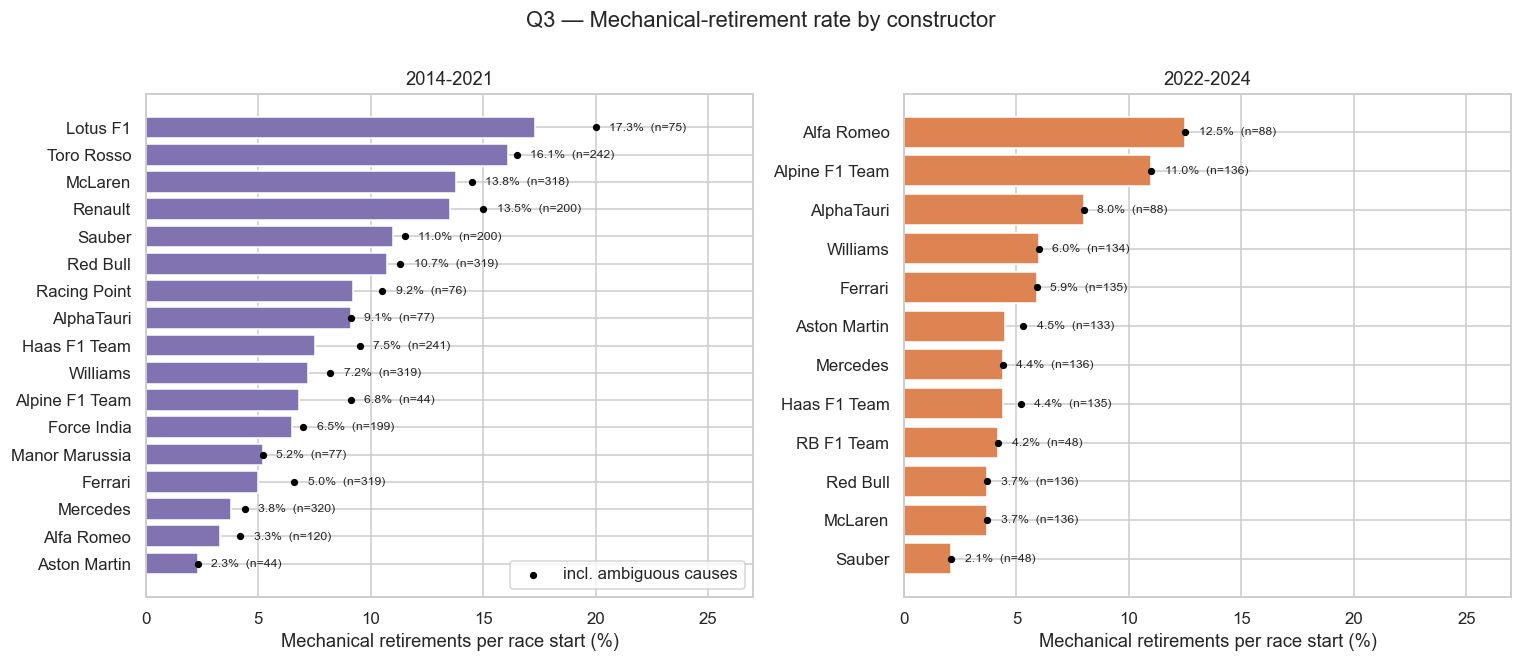

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, p, color in zip(axes, ["2014-2021", "2022-2024"], ["#8172B2", "#DD8452"]):
    r = rates[rates["period"] == p].sort_values("rate_strict")
    ax.barh(r["constructor"], r["rate_strict"], color=color)
    ax.scatter(r["rate_broad"], r["constructor"], color="black", s=14, zorder=3,
               label="incl. ambiguous causes")
    for y, (v, b, n) in enumerate(zip(r["rate_strict"], r["rate_broad"], r["starts"])):
        ax.text(max(v, b) + 0.6, y, f"{v:.1f}%  (n={n})", va="center", fontsize=8)
    ax.set_title(f"{p}"); ax.set_xlabel("Mechanical retirements per race start (%)")
    ax.set_xlim(0, rates["rate_broad"].max() * 1.35)
axes[0].legend(loc="lower right")
fig.suptitle("Q3 — Mechanical-retirement rate by constructor", y=1.0)
save_fig("q3_mechanical_retirements")
plt.show()

**Answer Q3.**
- **2014–2021 (turbo-hybrid era):** highest mechanical-retirement rates were **Lotus F1 (17.3%)**,
  **Toro Rosso (16.1%)**, **McLaren (13.8%)** and **Renault (13.5%)**; McLaren's figure reflects its
  2015–2017 Honda power-unit years. Lowest: Mercedes (3.8%), Ferrari (5.0%).
- **2022–2024 (ground-effect era):** highest were **Alfa Romeo (12.5%)**, **Alpine (11.0%)** and
  **AlphaTauri (8.0%)**. Lowest: Red Bull and McLaren (3.7%).
- **Reliability improved overall:** the mechanical rate fell from **9.2% to 5.9%** of race starts.
  McLaren went from among the worst (13.8%) to among the best (3.7%).
- **Sensitivity check:** counting ambiguous causes (puncture, wings, wheel, out of fuel) as mechanical
  changes rates by at most ~3 points and leaves the top of both rankings unchanged.

**Grain:** one row per driver per race start (non-starters already removed).
**Missingness:** every 2014–2024 status is classified (enforced by an assert).
**Cutoff:** status is post-race information — used here only for analysis, **never as a model feature**.
**Limitations:** team identity follows `constructorId`, so renamed teams are split (Toro Rosso → AlphaTauri →
RB; Force India → Racing Point → Aston Martin; Renault → Alpine; Sauber → Alfa Romeo → Sauber). Alpine
and Aston Martin have only 44 starts in 2014–2021 (the 2021 season), so their earlier rates are less
reliable. "Retired" with no stated cause (50 cases) is not counted as mechanical.

## 6. Feature engineering (leakage-safe)
**Rule:** every feature must be known after qualifying and before the race starts.
Pre-race information of this race (grid, qualifying) is allowed; results of this race are not.
History features use only *earlier* races (`shift(1)` before every rolling/expanding mean).
Feature groups: **grid, qualifying, driver form, constructor form, standings before the race.**

In [35]:
df = base.copy()
df = df.sort_values(["date", "raceId", "grid"]).reset_index(drop=True)

# Race-level info known before the start
n_starters = df.groupby("raceId")["driverId"].transform("size")
df["field_size"] = np.maximum(n_starters, df.groupby("raceId")["grid"].transform("max"))  # known pre-race
finish_rank = df.groupby("raceId")["positionOrder"].rank(method="first")          # rank among starters
df["finish_pct"] = finish_rank / n_starters                     # ~0 = won, 1 = last   (POST-race!)
df["dnf"] = (~(df["status"].eq("Finished") | df["status"].str.match(r"^\+\d+ Laps?$"))).astype(int)  # POST-race!

def past_mean(frame, by, col, window):
    """Mean of `col` over the previous `window` rows of each group — the current row is never included."""
    return frame.groupby(by)[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())

print(df[["year", "name", "date"]].drop_duplicates().head(3))
print("Rows:", len(df), "| sorted by date:", df["date"].is_monotonic_increasing)

    year                name       date
0   1950  British Grand Prix 1950-05-13
23  1950   Monaco Grand Prix 1950-05-21
44  1950    Swiss Grand Prix 1950-06-04
Rows: 24628 | sorted by date: True


### 6.2 Grid features
Evidence: §4.3 — podium rate falls steeply from P1 (64%) to P10 (6%); pit-lane starters 0%.

In [36]:
df["grid_pos"] = np.where(df["grid"] == 0, df["field_size"] + 1, df["grid"])   # pit lane = behind last
df["grid_pct"] = df["grid_pos"] / df["field_size"]                              # comparable across eras
df["front_row"] = (df["grid_pos"] <= 2).astype(int)
# pit_lane_start already exists from cleaning (§3.6)
df[["grid", "grid_pos", "grid_pct", "front_row", "pit_lane_start", "field_size"]].describe().round(2)

,grid,grid_pos,grid_pct,front_row,pit_lane_start,field_size
count,24628.00,24628.00,24628.00,24628.00,24628.00,24628.00
mean,11.74,11.80,0.52,0.09,0.00,22.66
std,6.76,6.75,0.29,0.29,0.05,2.98
min,0.00,1.00,0.03,0.00,0.00,10.00
25%,6.00,6.00,0.27,0.00,0.00,20.00
50%,12.00,12.00,0.52,0.00,0.00,22.00
75%,17.00,17.00,0.77,0.00,0.00,26.00
max,34.00,34.00,1.05,1.00,1.00,34.00


### 6.3 Qualifying features
Evidence: Q1 showed grid ≠ qualifying for ~4% of front-row cases, and penalised front-row qualifiers
podiumed only 31% of the time. Coverage: §2.4 — complete only from 2003.

In [37]:
qf = clean["qualifying"][["raceId", "driverId", "position", "q1_s"]].rename(columns={"position": "quali_pos"})
qf["q1_gap_pct"] = (qf["q1_s"] / qf.groupby("raceId")["q1_s"].transform("min") - 1) * 100
df = df.merge(qf[["raceId", "driverId", "quali_pos", "q1_gap_pct"]], on=["raceId", "driverId"],
              how="left", validate="one_to_one")
df["has_quali"] = df["quali_pos"].notna().astype(int)
df["grid_penalty"] = df["grid_pos"] - df["quali_pos"]          # > 0: started behind where he qualified

print("Qualifying coverage:", f"{df['has_quali'].mean():.1%} of rows overall,",
      f"{df.loc[df['year'] >= 2003, 'has_quali'].mean():.1%} from 2003")
df.loc[df["has_quali"] == 1, ["quali_pos", "q1_gap_pct", "grid_penalty"]].describe().round(2)

Qualifying coverage: 42.4% of rows overall, 99.8% from 2003


,quali_pos,q1_gap_pct,grid_penalty
count,10448.00,10292.00,10448.00
mean,11.19,1.85,0.01
std,6.25,1.93,1.54
min,1.00,0.00,-9.00
25%,6.00,0.71,0.00
50%,11.00,1.34,0.00
75%,16.00,2.36,0.00
max,26.00,44.78,23.00


### 6.4 Driver form — past races only
Recent podium rate (last 5), average finishing position (last 5), retirement rate (last 10),
experience (earlier starts), and past podium rate at this circuit.

In [38]:
g = df.groupby("driverId")
df["drv_starts_before"]   = g.cumcount()                                    # experience: earlier starts
df["drv_podium_rate_l5"]  = past_mean(df, "driverId", "podium", 5)
df["drv_finish_pct_l5"]   = past_mean(df, "driverId", "finish_pct", 5)
df["drv_dnf_rate_l10"]    = past_mean(df, "driverId", "dnf", 10)
df["drv_circuit_podium_rate"] = df.groupby(["driverId", "circuitId"])["podium"].transform(
    lambda s: s.shift(1).expanding().mean())                                # past visits to this circuit

# --- leakage self-test: recompute one driver's form by hand ---
sample = df[df["driverId"] == 1].head(8)            # driverId 1 = Lewis Hamilton, 2007 debut season
manual = sample["podium"].shift(1).rolling(5, min_periods=1).mean()
assert np.allclose(manual.fillna(-1), sample["drv_podium_rate_l5"].fillna(-1))
sample[["year", "name", "podium", "drv_podium_rate_l5", "drv_starts_before"]]

,year,name,podium,drv_podium_rate_l5,drv_starts_before
17139,2007,Australian Grand Prix,1,NaN,0
17161,2007,Malaysian Grand Prix,1,1.0,1
17181,2007,Bahrain Grand Prix,1,1.0,2
17205,2007,Spanish Grand Prix,1,1.0,3
17225,2007,Monaco Grand Prix,1,1.0,4
17246,2007,Canadian Grand Prix,1,1.0,5
17268,2007,United States Grand Prix,1,1.0,6
17291,2007,French Grand Prix,1,1.0,7


### 6.5 Constructor form — past races only
Car performance is the dominant factor in most eras (F1 guide), so team form is computed at race
level (both cars together), then shifted, so a team's current race never enters its own form.

In [39]:
team_race = (df.groupby(["constructorId", "raceId", "date"], as_index=False)
               .agg(team_podium_rate=("podium", "mean"), team_finish_pct=("finish_pct", "mean"),
                    team_dnf_rate=("dnf", "mean"))
               .sort_values(["date", "raceId"]))
team_race["con_podium_rate_l5"] = past_mean(team_race, "constructorId", "team_podium_rate", 5)
team_race["con_finish_pct_l5"]  = past_mean(team_race, "constructorId", "team_finish_pct", 5)
team_race["con_dnf_rate_l10"]   = past_mean(team_race, "constructorId", "team_dnf_rate", 10)

df = df.merge(team_race[["constructorId", "raceId", "con_podium_rate_l5", "con_finish_pct_l5",
                         "con_dnf_rate_l10"]], on=["constructorId", "raceId"],
              how="left", validate="many_to_one")
df[["con_podium_rate_l5", "con_finish_pct_l5", "con_dnf_rate_l10"]].describe().round(3)

,con_podium_rate_l5,con_finish_pct_l5,con_dnf_rate_l10
count,24365.000,24365.000,24365.000
mean,0.138,0.521,0.394
std,0.204,0.164,0.216
min,0.000,0.069,0.000
25%,0.000,0.411,0.200
50%,0.000,0.534,0.400
75%,0.200,0.637,0.550
max,1.000,1.000,1.000


### 6.6 Championship standings BEFORE the race
`driver_standings` / `constructor_standings` store totals **after** each race. Using them directly
would leak this race's result, so each race is joined to the standings of the **previous race of the
same season**. Season openers get 0 points. Points are expressed as a share of the leader's points,
because the points system changed many times between 1950 and 2024.

In [40]:
races_sorted = clean["races"].sort_values(["year", "round"])[["raceId", "year", "round"]].copy()
races_sorted["prev_raceId"] = races_sorted.groupby("year")["raceId"].shift(1)   # previous race, same season

def standings_before(table, key, prefix):
    s = clean[table][["raceId", key, "points", "position"]].rename(
        columns={"raceId": "prev_raceId", "points": f"{prefix}_points_before",
                 "position": f"{prefix}_rank_before"})
    out = races_sorted[["raceId", "prev_raceId"]].merge(s, on="prev_raceId", how="left")
    leader = out.groupby("raceId")[f"{prefix}_points_before"].transform("max")
    out[f"{prefix}_points_share_before"] = (out[f"{prefix}_points_before"] / leader).fillna(0)
    return out.drop(columns="prev_raceId")

drv_st = standings_before("driver_standings", "driverId", "drv")
con_st = standings_before("constructor_standings", "constructorId", "con")
df = df.merge(drv_st, on=["raceId", "driverId"], how="left", validate="one_to_one")
df = df.merge(con_st, on=["raceId", "constructorId"], how="left", validate="many_to_one")

df["is_season_opener"] = (df["round"] == 1).astype(int)
for p in ["drv", "con"]:
    df[f"{p}_points_before"] = df[f"{p}_points_before"].fillna(0)        # no points scored yet
    df[f"{p}_points_share_before"] = df[f"{p}_points_share_before"].fillna(0)

# --- leakage self-test: a season opener can never have points before it ---
assert (df.loc[df["round"] == 1, "drv_points_before"] == 0).all()
example = df[(df["year"] == 2021) & (df["driverId"] == 830)][["round", "name", "positionOrder",
                                                                "drv_points_before", "drv_rank_before"]]
example.head(5)

,round,name,positionOrder,drv_points_before,drv_rank_before
22837,1,Bahrain Grand Prix,2,0.0,NaN
22859,2,Emilia Romagna Grand Prix,1,18.0,2.0
22878,3,Portuguese Grand Prix,2,43.0,2.0
22897,4,Spanish Grand Prix,2,61.0,2.0
22917,5,Monaco Grand Prix,1,80.0,2.0


### 6.7 The modeling table
One row per (raceId, driverId), 22 features in 5 groups, target = podium.
An automatic check guarantees that no post-race column is used as a feature.

In [41]:
FEATURE_GROUPS = {
    "grid":        ["grid_pos", "grid_pct", "front_row", "pit_lane_start", "field_size"],
    "qualifying":  ["quali_pos", "q1_gap_pct", "grid_penalty", "has_quali"],
    "driver_form": ["drv_starts_before", "drv_podium_rate_l5", "drv_finish_pct_l5",
                    "drv_dnf_rate_l10", "drv_circuit_podium_rate"],
    "constructor_form": ["con_podium_rate_l5", "con_finish_pct_l5", "con_dnf_rate_l10"],
    "standings":   ["drv_points_share_before", "drv_rank_before", "con_points_share_before",
                    "con_rank_before", "is_season_opener"],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
ID_COLS = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date", "name"]
TARGET = "podium"

# Columns that are only known AFTER the race — none of them may be a feature
POST_RACE = ["position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
             "fastestLap", "rank", "fastestLapTime", "fastestLapTime_s", "fastestLapSpeed",
             "statusId", "status", "finish_pct", "dnf"]
leaks = set(FEATURES) & set(POST_RACE)
assert not leaks, f"Leakage! {leaks}"

model_df = df[ID_COLS + FEATURES + [TARGET]].copy()
assert not model_df.duplicated(["raceId", "driverId"]).any()
print(f"Modeling table: {model_df.shape[0]} rows x {len(FEATURES)} features | "
      f"podium rate {model_df[TARGET].mean():.1%} | one row per (raceId, driverId): True")
model_df.head()

Modeling table: 24628 rows x 22 features | podium rate 13.6% | one row per (raceId, driverId): True


,raceId,driverId,constructorId,circuitId,year,round,date,name,grid_pos,grid_pct,front_row,pit_lane_start,field_size,quali_pos,q1_gap_pct,grid_penalty,has_quali,drv_starts_before,drv_podium_rate_l5,drv_finish_pct_l5,drv_dnf_rate_l10,drv_circuit_podium_rate,con_podium_rate_l5,con_finish_pct_l5,con_dnf_rate_l10,drv_points_share_before,drv_rank_before,con_points_share_before,con_rank_before,is_season_opener,podium
0,833,642,51,9,1950,1,1950-05-13,British Grand Prix,1,0.043478,1,0,23,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,1,1
1,833,786,51,9,1950,1,1950-05-13,British Grand Prix,2,0.086957,1,0,23,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,1,1
2,833,579,51,9,1950,1,1950-05-13,British Grand Prix,3,0.130435,0,0,23,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,1,0
3,833,686,51,9,1950,1,1950-05-13,British Grand Prix,4,0.173913,0,0,23,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,1,1
4,833,669,105,9,1950,1,1950-05-13,British Grand Prix,5,0.217391,0,0,23,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,1,0


### 6.8 Missingness per feature and era
Missing values are left as NaN here and filled in Section 8, after the split, so fill values are learned
from training data only.

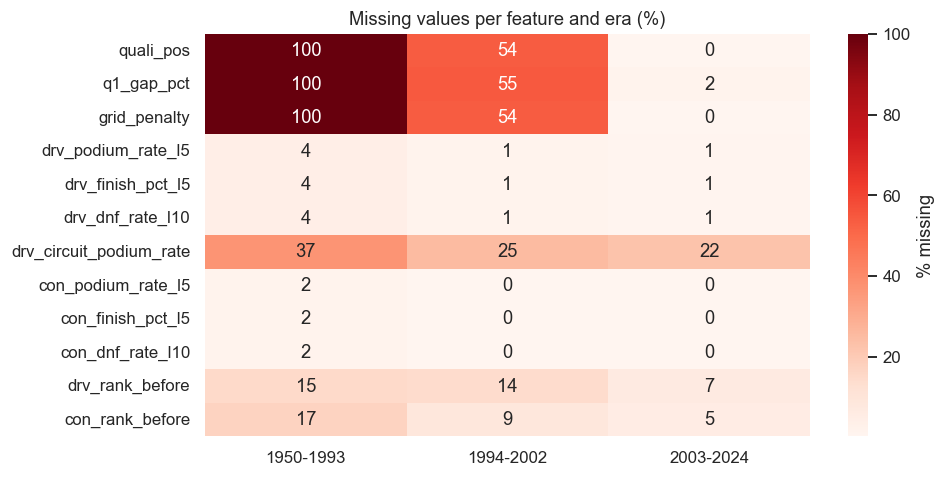

In [42]:
era = pd.cut(model_df["year"], bins=[1949, 1993, 2002, 2024], labels=["1950-1993", "1994-2002", "2003-2024"])
miss = model_df[FEATURES].isna().groupby(era, observed=True).mean().T * 100
miss = miss[miss.max(axis=1) > 0]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(miss, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Missing values per feature and era (%)"); ax.set_xlabel("")
save_fig("features_missingness")
plt.show()

### 6.9 How much signal does each feature carry on its own?
For each feature alone, ROC-AUC measures how well it separates podium from non-podium rows
(0.5 = random, 1.0 = perfect). Computed on training seasons (≤ 2019) only.
We also show what a *leaky* feature looks like, to make the danger concrete.

LEAKAGE DEMO — points gained in THIS race (after minus before): AUC = 0.968
Our best honest feature (quali_pos):            AUC = 0.906


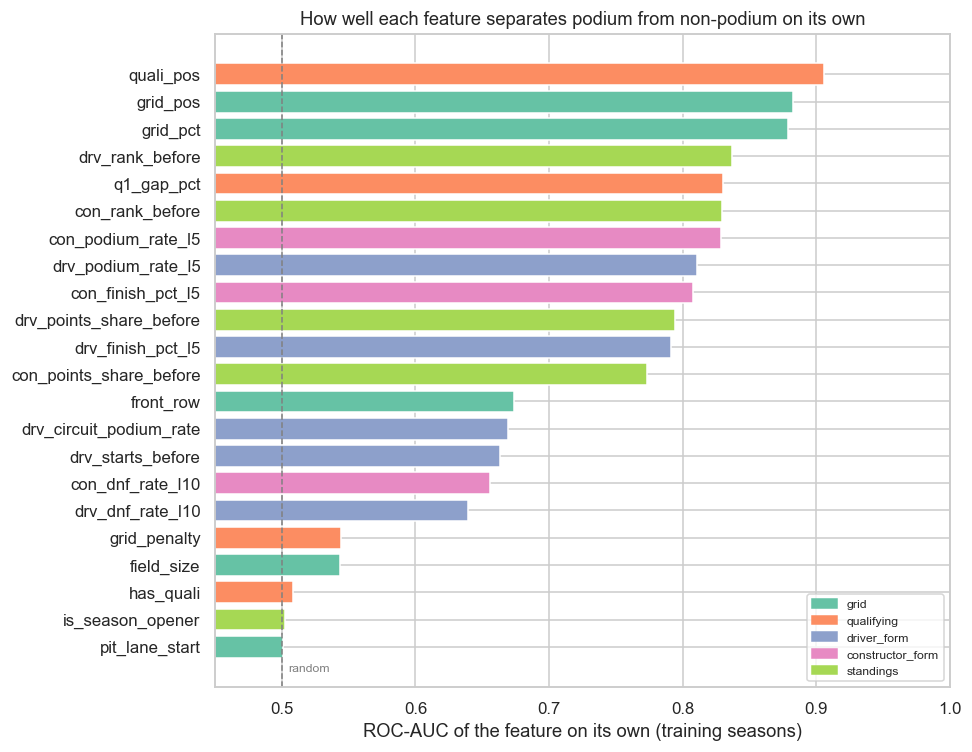

,feature,group,AUC alone,direction,coverage
5,quali_pos,qualifying,0.906,lower = better,0.370
0,grid_pos,grid,0.883,lower = better,1.000
1,grid_pct,grid,0.879,lower = better,1.000
18,drv_rank_before,standings,0.837,lower = better,0.876
6,q1_gap_pct,qualifying,0.830,lower = better,0.364
20,con_rank_before,standings,0.830,lower = better,0.875
14,con_podium_rate_l5,constructor_form,0.829,higher = better,0.989
10,drv_podium_rate_l5,driver_form,0.811,higher = better,0.970
15,con_finish_pct_l5,constructor_form,0.808,lower = better,0.989
17,drv_points_share_before,standings,0.794,higher = better,1.000


In [43]:
from sklearn.metrics import roc_auc_score

train_like = model_df[model_df["year"] <= 2019]          # evidence from training seasons only

def single_auc(x, y):
    ok = x.notna()
    auc = roc_auc_score(y[ok], x[ok])
    return max(auc, 1 - auc), ("higher = better" if auc >= 0.5 else "lower = better"), ok.mean()

evidence = pd.DataFrame(
    [(f, grp, *single_auc(train_like[f], train_like[TARGET]))
     for grp, cols in FEATURE_GROUPS.items() for f in cols],
    columns=["feature", "group", "AUC alone", "direction", "coverage"]
).sort_values("AUC alone", ascending=False)

# Leakage demo: the same kind of feature, but taken from AFTER the race
after = clean["driver_standings"][["raceId", "driverId", "points"]].rename(columns={"points": "drv_points_AFTER"})
demo = df[df["year"] <= 2019].merge(after, on=["raceId", "driverId"], how="left")
demo["drv_points_AFTER"] = demo["drv_points_AFTER"].fillna(0)
leak_auc = single_auc(demo["drv_points_AFTER"] - demo["drv_points_before"], demo[TARGET])[0]
print(f"LEAKAGE DEMO — points gained in THIS race (after minus before): AUC = {leak_auc:.3f}")
print(f"Our best honest feature ({evidence.iloc[0]['feature']}):            AUC = {evidence.iloc[0]['AUC alone']:.3f}")

fig, ax = plt.subplots(figsize=(9, 7))
colors = evidence["group"].map(dict(zip(FEATURE_GROUPS, sns.color_palette("Set2", len(FEATURE_GROUPS)))))
ax.barh(evidence["feature"][::-1], evidence["AUC alone"][::-1], color=colors[::-1])
ax.axvline(0.5, color="grey", ls="--", lw=1); ax.text(0.505, -0.9, "random", color="grey", fontsize=8)
ax.set_xlim(0.45, 1.0); ax.set_xlabel("ROC-AUC of the feature on its own (training seasons)")
ax.set_title("How well each feature separates podium from non-podium on its own")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in sns.color_palette("Set2", len(FEATURE_GROUPS))]
ax.legend(handles, FEATURE_GROUPS.keys(), loc="lower right", fontsize=8)
save_fig("features_univariate_auc")
plt.show()
evidence.round(3)

### 6.10 Shape of the relationship
Rows are split into 10 equal-size groups (deciles) by feature value; the podium rate of each group
shows whether the relationship is straight, curved, or saturating.

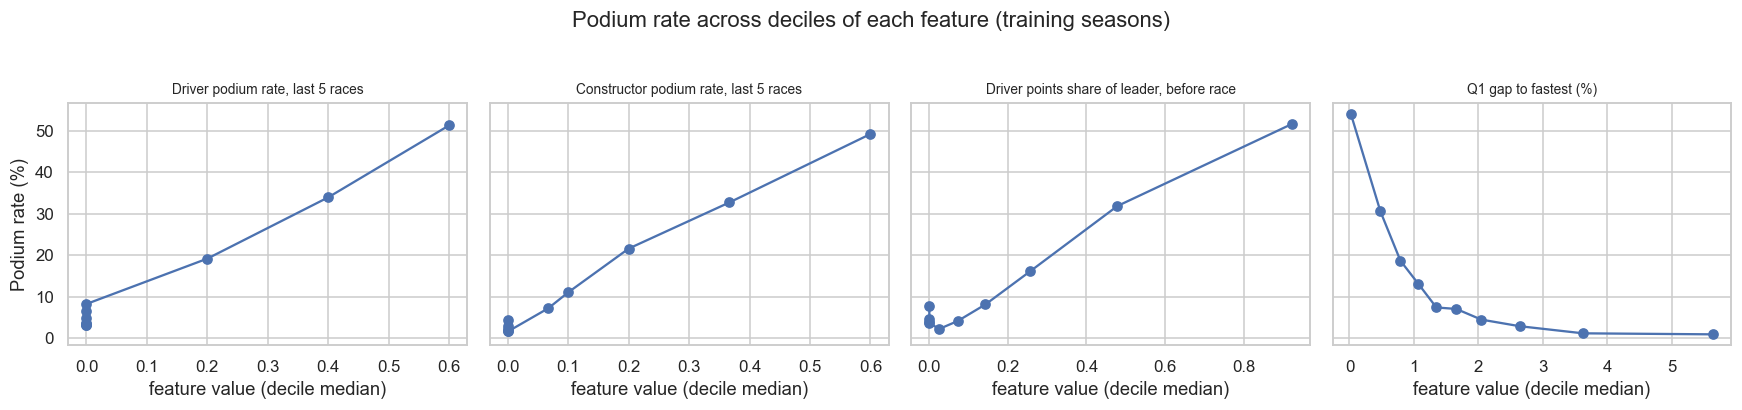

In [44]:
show = [("drv_podium_rate_l5", "Driver podium rate, last 5 races"),
        ("con_podium_rate_l5", "Constructor podium rate, last 5 races"),
        ("drv_points_share_before", "Driver points share of leader, before race"),
        ("q1_gap_pct", "Q1 gap to fastest (%)")]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (f, title) in zip(axes, show):
    d = train_like[[f, TARGET]].dropna()
    bins = pd.qcut(d[f].rank(method="first"), q=10, labels=False)     # 10 equal-size groups
    rate = d.groupby(bins)[TARGET].mean() * 100
    mid = d.groupby(bins)[f].median()
    ax.plot(mid, rate, marker="o", color="#4C72B0")
    ax.set_title(title, fontsize=9); ax.set_xlabel("feature value (decile median)")
axes[0].set_ylabel("Podium rate (%)")
fig.suptitle("Podium rate across deciles of each feature (training seasons)", y=1.03)
save_fig("features_deciles")
plt.show()

### 6.11 Redundancy between features
Highly correlated features carry overlapping information. This matters for logistic regression
(unstable coefficients) and for explanations (importance gets split between twins).

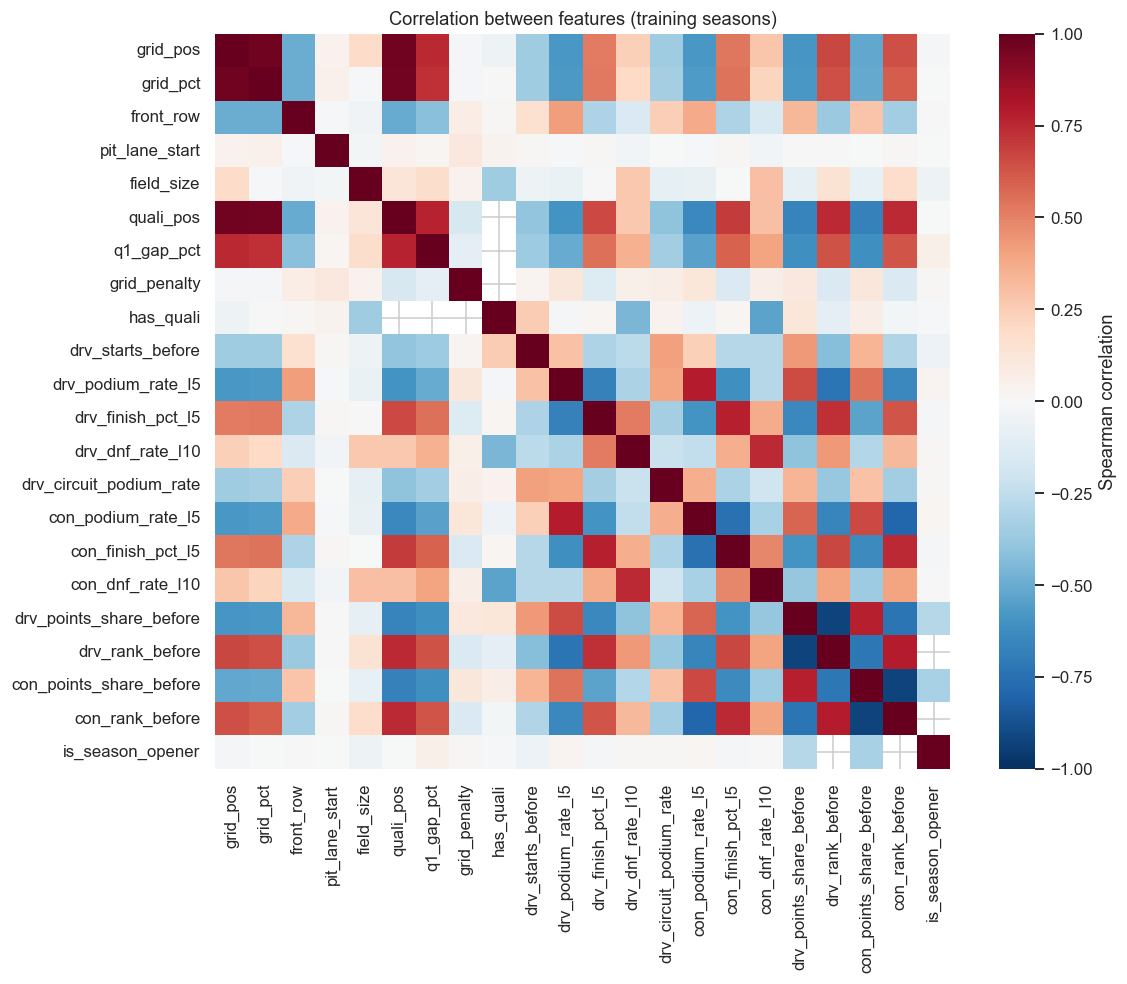

,level_0,level_1,rho
4,grid_pos,quali_pos,0.98
0,grid_pos,grid_pct,0.97
24,grid_pct,quali_pos,0.96
224,con_points_share_before,con_rank_before,-0.92
218,drv_points_share_before,drv_rank_before,-0.92
205,con_podium_rate_l5,con_rank_before,-0.79
223,drv_rank_before,con_rank_before,0.78
165,drv_podium_rate_l5,con_podium_rate_l5,0.78


In [45]:
corr = train_like[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Correlation between features (training seasons)")
save_fig("features_correlation")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("rho").reset_index())
pairs["abs"] = pairs["rho"].abs()
pairs.sort_values("abs", ascending=False).head(8).drop(columns="abs").round(2)

### 6.12 Feature summary

| Group | Features | Why it is valid before the race | Evidence |
|---|---|---|---|
| Grid | grid_pos, grid_pct, front_row, pit_lane_start, field_size | Starting order is fixed before lights out | §4.3; AUC 0.88 |
| Qualifying | quali_pos, q1_gap_pct, grid_penalty, has_quali | Qualifying ends before the race | Q1 (penalties); AUC 0.91 / 0.83 |
| Driver form | starts before, podium rate L5, finish % L5, DNF rate L10, circuit podium rate | Only earlier races (`shift(1)`), self-tested | AUC 0.81; decile plot |
| Constructor form | podium rate L5, finish % L5, DNF rate L10 | Team result per race, then shifted | AUC 0.83; decile plot |
| Standings | points share & rank (driver, team), season opener | Standings of the **previous** race, self-tested | AUC 0.84 |

**Not used:** post-race columns (position, points, laps, status, fastest lap — blocked by an assert),
`home` (no effect in Q2), sprint results (≈ 30 races only), `year` (trees cannot extrapolate to new seasons).
**Leakage demo:** one post-race feature (points gained this race) reaches AUC 0.968 alone —
higher than any honest feature, which is exactly why it is forbidden.

## 7. Train / validation / test split (by season)
Train ≤ 2019 · Validation 2020–2021 · Test 2022–2024. A random split would let the model learn from
future seasons and from the same races it is evaluated on, inflating scores. All choices are made on
validation; the test set is used once, at the end.

In [46]:
TRAIN_END, VAL_END = 2019, 2021

def split_of(year):
    return np.where(year <= TRAIN_END, "train", np.where(year <= VAL_END, "validation", "test"))

model_df["split"] = split_of(model_df["year"])

split_table = (model_df.groupby("split")
               .agg(seasons=("year", lambda s: f"{s.min()}-{s.max()}"), races=("raceId", "nunique"),
                    rows=("raceId", "size"), podium_rate=(TARGET, "mean"))
               .reindex(["train", "validation", "test"]))
split_table["podium_rate"] = (split_table["podium_rate"] * 100).round(1)

# --- checks: no race in two splits, and every train race is earlier than every validation race, etc. ---
assert model_df.groupby("raceId")["split"].nunique().max() == 1
assert model_df.loc[model_df["split"] == "train", "date"].max() < model_df.loc[model_df["split"] == "validation", "date"].min()
assert model_df.loc[model_df["split"] == "validation", "date"].max() < model_df.loc[model_df["split"] == "test", "date"].min()
print("No race appears in two splits; train < validation < test in time.")
split_table

No race appears in two splits; train < validation < test in time.


,seasons,races,rows,podium_rate
split,,,,
train,1950-2019,1007,22497,13.4
validation,2020-2021,39,778,15.0
test,2022-2024,68,1353,15.1


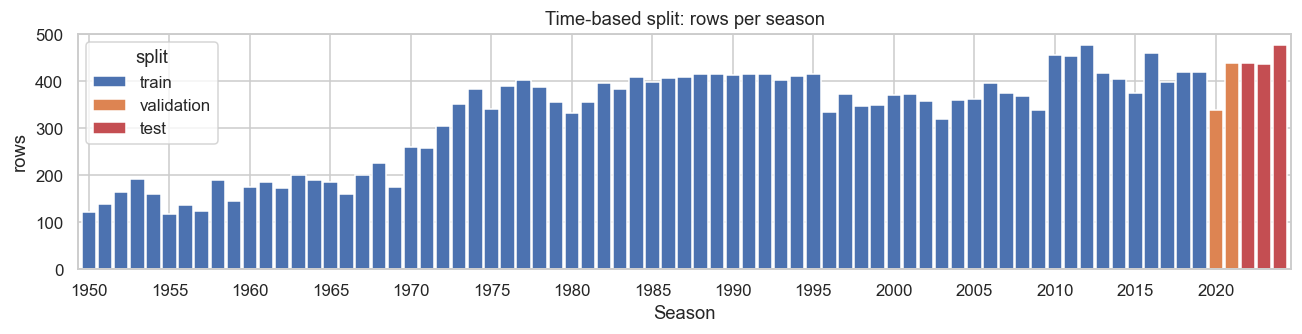

In [47]:
fig, ax = plt.subplots(figsize=(12, 3.2))
per_year = model_df.groupby(["year", "split"]).size().unstack(fill_value=0)[["train", "validation", "test"]]
per_year.plot(kind="bar", stacked=True, ax=ax, width=0.9,
              color={"train": "#4C72B0", "validation": "#DD8452", "test": "#C44E52"})
ax.set_xticks(range(0, len(per_year), 5)); ax.set_xticklabels(per_year.index[::5], rotation=0)
ax.set_ylabel("rows"); ax.set_xlabel("Season"); ax.set_title("Time-based split: rows per season")
save_fig("split_by_season")
plt.show()

### 7.3 Which seasons should the model train on?
Old seasons add data, but F1 was a different sport (qualifying data missing before 1994/2003,
>50% retirement rates, 30+ car fields). We train two quick models with different start seasons
(training always ends in 2019) and compare them on **validation only**. This is one of our
experiments.

In [48]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

val = model_df[model_df["split"] == "validation"]

def quick_models():
    return {
        "logistic regression": make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                             StandardScaler(), LogisticRegression(max_iter=2000)),
        "gradient boosting":   HistGradientBoostingClassifier(random_state=SEED),
    }

rows = []
for start in [1950, 1981, 1994, 2003, 2010]:
    tr = model_df[(model_df["split"] == "train") & (model_df["year"] >= start)]
    for name, m in quick_models().items():
        m.fit(tr[FEATURES], tr[TARGET])
        p = m.predict_proba(val[FEATURES])[:, 1]
        rows.append({"train from": start, "model": name, "train rows": len(tr),
                     "val PR-AUC": average_precision_score(val[TARGET], p),
                     "val ROC-AUC": roc_auc_score(val[TARGET], p)})
window = pd.DataFrame(rows)
window.pivot(index="train from", columns="model", values="val PR-AUC").round(3)

model,gradient boosting,logistic regression
train from,,
1950,0.712,0.722
1981,0.712,0.729
1994,0.716,0.723
2003,0.657,0.731
2010,0.619,0.728


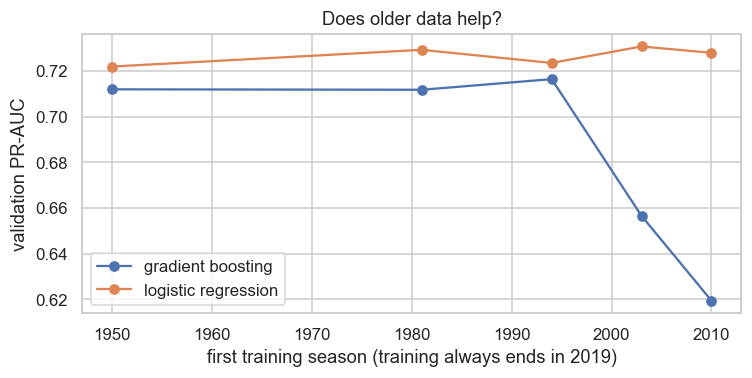

train from
1950    0.7169
1981    0.7205
1994    0.7199
2003    0.6936
2010    0.6736
Name: val PR-AUC, dtype: float64
Best start season (average of both models on validation): 1981


In [49]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for name, d in window.groupby("model"):
    ax.plot(d["train from"], d["val PR-AUC"], marker="o", label=name)
ax.set_xlabel("first training season (training always ends in 2019)")
ax.set_ylabel("validation PR-AUC"); ax.set_title("Does older data help?"); ax.legend()
save_fig("training_window")
plt.show()

best = window.groupby("train from")["val PR-AUC"].mean().idxmax()
print(window.groupby("train from")["val PR-AUC"].mean().round(4))
print("Best start season (average of both models on validation):", best)

**Decision: train on 1981–2019.** On validation, starting in 1981 gives the best average PR-AUC
across both models (0.7205), essentially tied with 1994 (0.7199) and slightly above using all
seasons from 1950 (0.7169). Starting later starves the gradient-boosting model of data: its PR-AUC
falls from ~0.71 to 0.66 (2003+) and 0.62 (2010+), while logistic regression stays flat (0.72–0.73).
Between the tied options we choose 1981 because it keeps more training rows (15,368) for the tree
models, while dropping the least comparable early era. Qualifying features remain missing for
1981–2002 and are handled by median imputation + missing-indicator flags (Section 8).
Validation holds only 117 podiums, so differences below ~0.01 PR-AUC are not meaningful.

In [50]:
TRAIN_START = 1981
train = model_df[(model_df["split"] == "train") & (model_df["year"] >= TRAIN_START)].copy()
val   = model_df[model_df["split"] == "validation"].copy()
test  = model_df[model_df["split"] == "test"].copy()

X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

for name, d in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:<11} {d['year'].min()}-{d['year'].max()}  rows={len(d):>6}  "
          f"podiums={int(d[TARGET].sum()):>5}  rate={d[TARGET].mean():.1%}")

train       1981-2019  rows= 15368  podiums= 2028  rate=13.2%
validation  2020-2021  rows=   778  podiums=  117  rate=15.0%
test        2022-2024  rows=  1353  podiums=  204  rate=15.1%


## 8. Preprocessing & preprocessing-order experiments
The models cannot use the modeling table as it is: it has missing values (§6.8) and features on very
different scales (a rank from 1 to 30 next to a rate from 0 to 1). This section builds the preprocessing,
shows what it does to the data, and tests the choices with controlled experiments.

**Rule:** every number the preprocessing needs (medians, means, standard deviations) is learned from the
**training seasons only**, inside a scikit-learn `Pipeline`. Validation and test rows are transformed
with the training numbers, exactly as a real future race would be.

### 8.1 The preprocessing pipeline
Three steps, in this order:
1. **Median imputation** — a missing value is replaced by the feature's median in the training data
   (the median is not pulled around by extreme values such as a 45% qualifying gap).
2. **Missing-indicator flags** — for every feature that has gaps, a 0/1 column "this value was missing"
   is added, so the model can tell a real median from a filled-in one. This matters here because
   qualifying is missing for a *reason* (old seasons, §2.4), not at random.
3. **Standardisation** — every column is rescaled to mean 0 and standard deviation 1. Needed by logistic
   regression and the neural network; tree models do not need it, so they skip this step.

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, confusion_matrix, brier_score_loss)

def make_preprocessor(scale=True, strategy="median", indicator=True):
    """Imputation (+ missing flags), then optional scaling. Always fitted on training rows only."""
    steps = [("impute", SimpleImputer(strategy=strategy, add_indicator=indicator))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return Pipeline(steps)

prep = make_preprocessor().fit(X_train)                       # learned from 1981-2019 only
PREP_COLS = list(prep.named_steps["impute"].get_feature_names_out(FEATURES))
flag_cols = [c for c in PREP_COLS if c.startswith("missingindicator_")]

print(f"Columns: {len(FEATURES)} features -> {len(PREP_COLS)} after preprocessing "
      f"({len(flag_cols)} missing-indicator flags added)")
learned = pd.DataFrame({
    "missing in train %": (X_train.isna().mean() * 100).round(1),
    "missing in validation %": (X_val.isna().mean() * 100).round(1),
    "fill value (train median)": prep.named_steps["impute"].statistics_.round(3),
}, index=FEATURES)
learned[learned["missing in train %"] > 0]

Columns: 22 features -> 34 after preprocessing (12 missing-indicator flags added)


,missing in train %,missing in validation %,fill value (train median)
quali_pos,45.9,0.1,11.000
q1_gap_pct,46.8,1.2,1.502
grid_penalty,45.9,0.1,0.000
drv_podium_rate_l5,1.4,0.8,0.000
drv_finish_pct_l5,1.4,0.8,0.537
drv_dnf_rate_l10,1.4,0.8,0.400
drv_circuit_podium_rate,26.2,28.1,0.000
con_podium_rate_l5,0.5,0.5,0.000
con_finish_pct_l5,0.5,0.5,0.537
con_dnf_rate_l10,0.5,0.5,0.350


**What we see.** 12 of the 22 features have gaps, so 12 flags are added (22 → 34 columns).
The qualifying features are missing for ~46% of training rows (seasons before 2003) but for almost no
validation rows — this is the "qualifying-coverage drift" from §2.4, and the flags are how the model
can treat those old rows differently. `drv_circuit_podium_rate` is missing on a driver's first visit to a
circuit (26%); the standings ranks are missing at season openers.

### 8.2 What does preprocessing do to the data?
Top row: four features as they are in the training table (gaps shown in the title).
Bottom row: the same features after imputation + scaling. The shape of each distribution is kept —
only the units change — and the filled-in rows appear as one tall bar at the median.

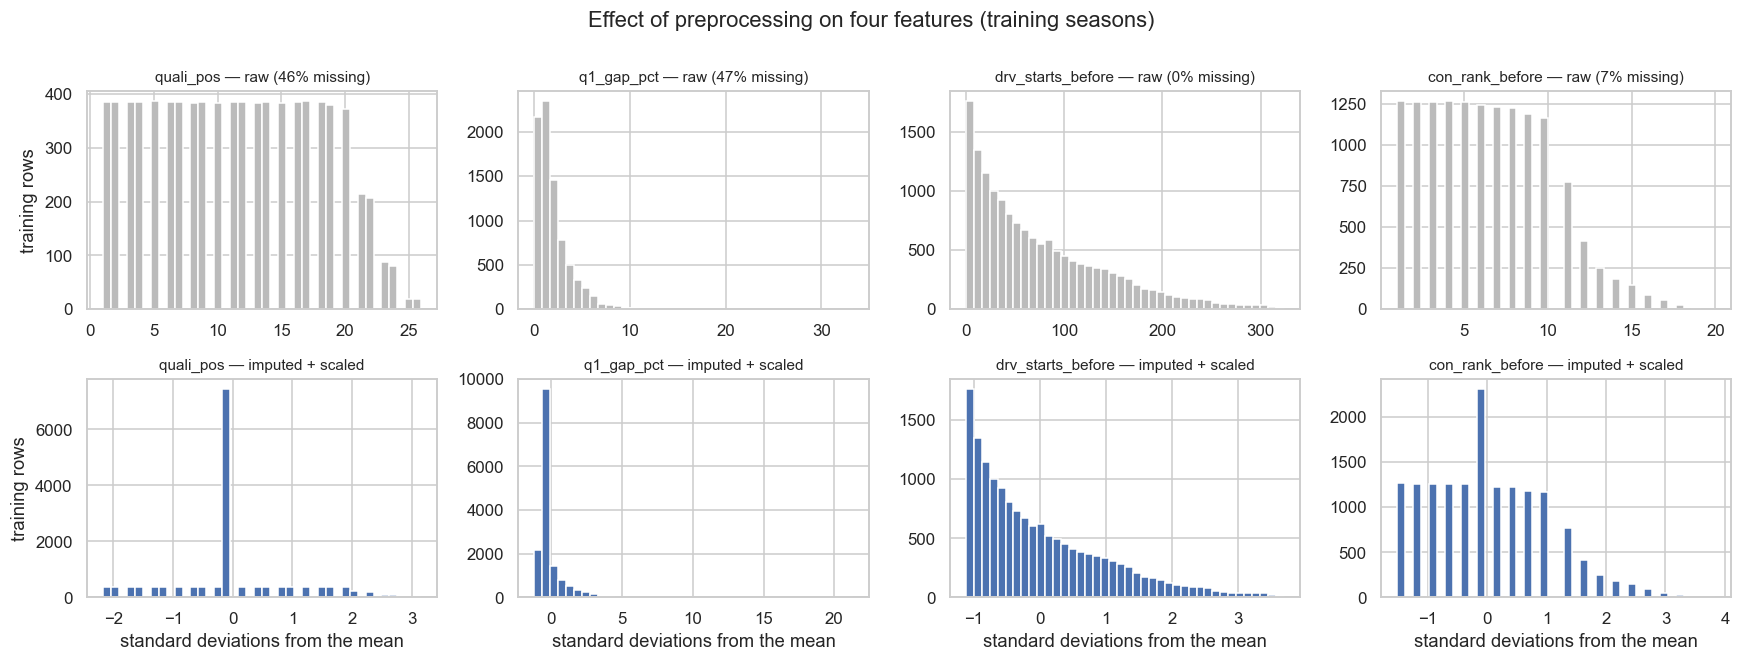

,missing % before,missing % after,mean before,mean after,std before,std after,min before,max before,min after,max after
grid_pos,0.00,0.0,12.03,-0.0,6.80,1.0,1.0,29.00,-1.62,2.50
field_size,0.00,0.0,23.06,0.0,2.43,1.0,14.0,29.00,-3.73,2.44
quali_pos,45.87,0.0,11.37,0.0,6.36,1.0,1.0,26.00,-2.18,3.16
q1_gap_pct,46.75,0.0,2.02,-0.0,2.00,1.0,0.0,33.29,-1.20,21.30
drv_starts_before,0.00,0.0,75.55,-0.0,67.06,1.0,0.0,324.00,-1.13,3.71
drv_podium_rate_l5,1.39,0.0,0.13,0.0,0.24,1.0,0.0,1.00,-0.55,3.65
con_rank_before,6.94,0.0,6.40,-0.0,3.68,1.0,1.0,20.00,-1.51,3.84
drv_points_share_before,0.00,0.0,0.19,-0.0,0.28,1.0,0.0,1.00,-0.68,2.85


In [52]:
Xt_train = pd.DataFrame(prep.transform(X_train), columns=PREP_COLS, index=X_train.index)

show = ["quali_pos", "q1_gap_pct", "drv_starts_before", "con_rank_before"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, f in enumerate(show):
    axes[0, j].hist(X_train[f].dropna(), bins=40, color="#BBBBBB")
    axes[0, j].set_title(f"{f} — raw ({X_train[f].isna().mean():.0%} missing)", fontsize=10)
    axes[1, j].hist(Xt_train[f], bins=40, color="#4C72B0")
    axes[1, j].set_title(f"{f} — imputed + scaled", fontsize=10)
    axes[1, j].set_xlabel("standard deviations from the mean")
axes[0, 0].set_ylabel("training rows"); axes[1, 0].set_ylabel("training rows")
fig.suptitle("Effect of preprocessing on four features (training seasons)", y=1.0)
save_fig("prep_before_after")
plt.show()

effect = pd.DataFrame({
    "missing % before": X_train.isna().mean() * 100, "missing % after": Xt_train[FEATURES].isna().mean() * 100,
    "mean before": X_train.mean(), "mean after": Xt_train[FEATURES].mean(),
    "std before": X_train.std(), "std after": Xt_train[FEATURES].std(),
    "min before": X_train.min(), "max before": X_train.max(),
    "min after": Xt_train[FEATURES].min(), "max after": Xt_train[FEATURES].max(),
})
effect.loc[["grid_pos", "field_size", "quali_pos", "q1_gap_pct", "drv_starts_before",
            "drv_podium_rate_l5", "con_rank_before", "drv_points_share_before"]].round(2)

**Effect of the step.** After preprocessing there are no missing values and every feature has mean 0 and
standard deviation 1, so a rank (1–29) and a rate (0–1) now weigh the same. The shapes are unchanged.
Two things to keep in mind: the tall bar at the median of `quali_pos` is the 46% of rows that were filled
in (they are marked by the flag), and scaling does **not** remove outliers — the largest `q1_gap_pct`
is still 21 standard deviations from the mean.

### 8.3 Experiment A — fit the preprocessing on all rows, or on training rows only?
A very common mistake is to impute and scale the *whole* table first and split afterwards. The medians
and standard deviations then contain information from the validation and test seasons (a leak).
We run both orders with the same logistic regression and compare them on validation.

In [53]:
def lr_validation_score(preprocessor, label):
    """Logistic regression on already-fitted preprocessing; returns validation scores."""
    clf = LogisticRegression(max_iter=5000).fit(preprocessor.transform(X_train), y_train)
    p = clf.predict_proba(preprocessor.transform(X_val))[:, 1]
    return {"variant": label, "val PR-AUC": average_precision_score(y_val, p),
            "val ROC-AUC": roc_auc_score(y_val, p)}

X_all = model_df.loc[model_df["year"] >= TRAIN_START, FEATURES]     # train + validation + test together
prep_train_only = make_preprocessor().fit(X_train)                  # split first, then preprocess (correct)
prep_all_rows   = make_preprocessor().fit(X_all)                    # preprocess first, then split (leaky)

exp_a = pd.DataFrame([lr_validation_score(prep_train_only, "split -> fit on TRAIN only (correct)"),
                      lr_validation_score(prep_all_rows,   "fit on ALL rows -> split (leaky)")]).set_index("variant")

stats = pd.DataFrame({
    "median, train only": prep_train_only.named_steps["impute"].statistics_,
    "median, all rows":   prep_all_rows.named_steps["impute"].statistics_,
    "std, train only":    prep_train_only.named_steps["scale"].scale_[:len(FEATURES)],
    "std, all rows":      prep_all_rows.named_steps["scale"].scale_[:len(FEATURES)],
}, index=FEATURES)
print("What the preprocessing 'learns' in each order (features where it differs most):")
print(stats.loc[["field_size", "quali_pos", "q1_gap_pct", "drv_starts_before", "con_rank_before"]].round(3), "\n")
exp_a.round(4)

What the preprocessing 'learns' in each order (features where it differs most):
                   median, train only  median, all rows  std, train only  \
field_size                     22.000            22.000            2.428   
quali_pos                      11.000            11.000            4.684   
q1_gap_pct                      1.502             1.344            1.479   
drv_starts_before              56.000            62.000           67.055   
con_rank_before                 6.000             6.000            3.547   

                   std, all rows  
field_size                 2.496  
quali_pos                  4.834  
q1_gap_pct                 1.503  
drv_starts_before         74.208  
con_rank_before            3.477   



,val PR-AUC,val ROC-AUC
variant,,
split -> fit on TRAIN only (correct),0.7292,0.9325
fit on ALL rows -> split (leaky),0.7290,0.9325


**Result A — no measurable difference (PR-AUC 0.7292 vs 0.7290).** The leaky order does learn different
numbers (e.g. the median qualifying gap moves from 1.50 to 1.34, the spread of `drv_starts_before` from
67 to 74), but validation + test are only 2,131 of 17,499 rows, and medians and standard deviations
contain no information about *who finished on the podium*. So this leak is real but harmless here.

**Decision: fit on training rows only, inside a `Pipeline`.** Not because it scores higher, but because
(1) it is the only order that matches real use — the 2022 season does not exist when the model is
built, and (2) the same mistake with a stronger step (anything that looks at the target) would inflate
the scores. The experiment shows the correct order costs nothing.

### 8.4 Experiment B — impute then scale, or scale then impute?
Same steps, opposite order. With *impute → scale* the filled-in values take part in the mean and standard
deviation; with *scale → impute* the scaler only sees real values (it ignores NaN) and the gaps are
filled afterwards. We test both orders for median and for mean imputation.

In [54]:
def order_pipeline(order, strategy):
    imputer = ("impute", SimpleImputer(strategy=strategy, add_indicator=True))
    scaler = ("scale", StandardScaler())
    steps = [imputer, scaler] if order == "impute -> scale" else [scaler, imputer]
    return Pipeline(steps + [("clf", LogisticRegression(max_iter=5000))])

rows = []
for strategy in ["median", "mean"]:
    for order in ["impute -> scale", "scale -> impute"]:
        m = order_pipeline(order, strategy).fit(X_train, y_train)
        p = m.predict_proba(X_val)[:, 1]
        scaled = m[:-1].transform(X_train)[:, FEATURES.index("quali_pos")]
        rows.append({"imputation": strategy, "order": order,
                     "val PR-AUC": average_precision_score(y_val, p),
                     "val ROC-AUC": roc_auc_score(y_val, p),
                     "quali_pos: std of real values after": np.std(scaled[X_train["quali_pos"].notna().to_numpy()])})
exp_b = pd.DataFrame(rows).set_index(["imputation", "order"])
exp_b.round(4)

val PR-AUC  val ROC-AUC  \
imputation order                                      
median     impute -> scale      0.7292       0.9325   
           scale -> impute      0.7284       0.9318   
mean       impute -> scale      0.7292       0.9325   
           scale -> impute      0.7284       0.9319   

                            quali_pos: std of real values after  
imputation order                                                 
median     impute -> scale                               1.3582  
           scale -> impute                               1.0000  
mean       impute -> scale                               1.3592  
           scale -> impute                               1.0000

**Result B — the order changes the data, but not the score (0.7292 vs 0.7284).** With *impute → scale*,
the 46% filled-in qualifying values all sit at the median, which shrinks the standard deviation, so the
real qualifying positions end up stretched (std 1.36 instead of 1.00). With *scale → impute* the real
values keep std 1.00 and the flags stay as plain 0/1. For the model this is only a different unit, and a
gap of 0.001 is far below the noise of our validation set (~0.01, §7.3). Median and mean give the
same result.

**Decision: impute → scale.** Every column, including the flags, ends on the same scale, which is what
a regularised logistic regression and a neural network expect.

### 8.5 Experiment C — which imputation, and do the missing flags help?
Median vs mean vs a constant (−1, an "impossible" value), each with and without the missing-indicator
flags. Same logistic regression, compared on validation.

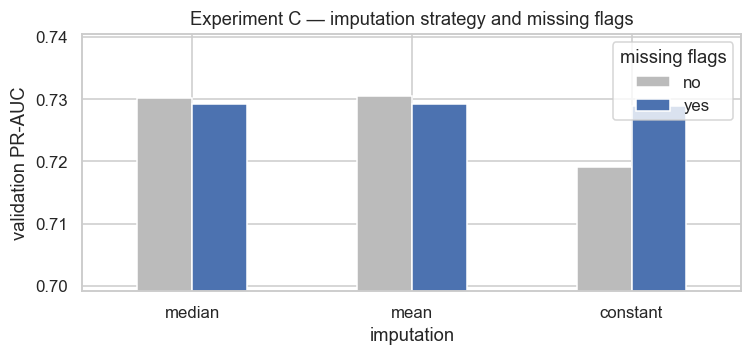

missing flags,no,yes
imputation,,
median,0.7302,0.7292
mean,0.7305,0.7292
constant,0.7191,0.7290


In [55]:
rows = []
for strategy in ["median", "mean", "constant"]:
    for indicator in [True, False]:
        imputer = SimpleImputer(strategy=strategy, add_indicator=indicator,
                                **({"fill_value": -1} if strategy == "constant" else {}))
        m = Pipeline([("impute", imputer), ("scale", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=5000))]).fit(X_train, y_train)
        p = m.predict_proba(X_val)[:, 1]
        rows.append({"imputation": strategy, "missing flags": "yes" if indicator else "no",
                     "val PR-AUC": average_precision_score(y_val, p), "val ROC-AUC": roc_auc_score(y_val, p)})
exp_c = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 3.4))
piv = exp_c.pivot(index="imputation", columns="missing flags", values="val PR-AUC").loc[["median", "mean", "constant"]]
piv.plot(kind="bar", ax=ax, color=["#BBBBBB", "#4C72B0"], rot=0)
ax.set_ylim(piv.min().min() - 0.02, piv.max().max() + 0.01)
ax.set_ylabel("validation PR-AUC"); ax.set_title("Experiment C — imputation strategy and missing flags")
ax.legend(title="missing flags")
save_fig("prep_experiment_imputation")
plt.show()
piv.round(4)

**Result C.** With median or mean imputation the flags make no difference (0.729 vs 0.730). With the
constant −1 they matter: 0.719 without flags, 0.729 with. The reason the flags look unnecessary for
median/mean is that the biggest gap (qualifying) already has a hand-made flag, `has_quali` (§6.3).

**Decision: median + flags.** The median is not pulled by the long tail of `q1_gap_pct` (§8.2); the flags
cost nothing on validation and mean that *every* gap is marked, not only the qualifying one — which the
inference function relies on when a record arrives with missing fields (§12).

### 8.6 Experiment D — class imbalance: class weights or not?
Only ~13% of training rows are podiums. Two ways to deal with that:
- **class weights** (`class_weight="balanced"`): each podium row counts ~6.5× more during training;
- **no weights**, and instead choose the decision threshold on validation (Section 9).

We compare both for a linear and a tree model. Besides PR-AUC we look at F1 at the default 0.5
threshold, F1 at the best validation threshold, and whether the predicted probabilities are honest
(the average predicted probability should be close to the real podium rate).

In [56]:
def best_f1_threshold(y_true, proba):
    """Threshold that gives the highest F1 on the given (validation) rows."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return float(thresholds[np.argmax(f1[:-1])])              # the last curve point has no threshold

rows = []
for weight in [None, "balanced"]:
    candidates = {
        "logistic regression": Pipeline([("prep", make_preprocessor()),
                                         ("clf", LogisticRegression(max_iter=5000, class_weight=weight))]),
        "gradient boosting": HistGradientBoostingClassifier(class_weight=weight, early_stopping=False,
                                                            random_state=SEED),
    }
    for name, m in candidates.items():
        p = m.fit(X_train, y_train).predict_proba(X_val)[:, 1]
        thr = best_f1_threshold(y_val, p)
        rows.append({"model": name, "class weights": str(weight),
                     "val PR-AUC": average_precision_score(y_val, p),
                     "F1 at 0.5": f1_score(y_val, p >= 0.5),
                     "F1 at best threshold": f1_score(y_val, p >= thr), "best threshold": thr,
                     "mean predicted prob.": p.mean(), "Brier score": brier_score_loss(y_val, p)})
exp_d = pd.DataFrame(rows).set_index(["model", "class weights"])
print(f"Real podium rate in validation: {y_val.mean():.3f}")
exp_d.round(3)

Real podium rate in validation: 0.150


,,val PR-AUC,F1 at 0.5,F1 at best threshold,best threshold,mean predicted prob.,Brier score
model,class weights,,,,,,
logistic regression,None,0.729,0.660,0.706,0.247,0.146,0.067
gradient boosting,None,0.681,0.670,0.703,0.257,0.139,0.070
logistic regression,balanced,0.722,0.648,0.708,0.631,0.299,0.107
gradient boosting,balanced,0.681,0.664,0.705,0.762,0.235,0.089


**Result D — class weights do not help here.** They do not improve the ranking (logistic regression
0.729 → 0.722, gradient boosting unchanged) and, once the threshold is tuned, F1 is the same
(0.706 vs 0.708). What they *do* change is the meaning of the output: with weights the average predicted
probability is 0.30 while the real podium rate is 0.15 (Brier score 0.067 → 0.107, lower is better).

**Decision: no class weights.** The imbalance is handled by (1) using PR-AUC as the main metric and
(2) choosing the decision threshold on validation (about 0.25 instead of 0.5). This keeps the output an
honest probability, which is what `predict_podium` returns in Section 12.

In [57]:
CLASS_WEIGHT = None      # decision from Experiment D

### 8.7 Preprocessing decisions

| Choice | Decision | Evidence |
|---|---|---|
| Where the preprocessing is fitted | training seasons only, inside a `Pipeline` | Exp. A: same score, no leak |
| Order | impute → scale | Exp. B: 0.729 vs 0.728 |
| Imputation | median + missing flags | Exp. C: flags essential for a constant, free for the median |
| Class imbalance | no class weights; threshold chosen on validation | Exp. D: same PR-AUC / F1, honest probabilities |
| Scaling | for logistic regression and the network; not for trees | trees split on order, not on units |

All four experiments moved validation PR-AUC by less than 0.01, which is below what 117 validation
podiums can resolve. So these choices are made on principle (no leakage, honest probabilities), and
the experiments confirm that none of them costs performance.

## 9. Models
All models use the **same rows and the same 22 features** (`X_train`, `X_val`, `X_test` from Section 7),
so their scores are directly comparable.

| # | Model | Role |
|---|---|---|
| 0 | Grid rule ("starts in the top 3") | sanity check — no learning at all |
| 1 | Logistic regression | **baseline** statistical model |
| 2 | Random forest | statistical model, non-linear |
| 3 | Gradient boosting | statistical model, non-linear |
| 4 | Shallow neural network (Keras) | 1–2 hidden layers |

**Metrics.** *Primary:* **PR-AUC** — podiums are rare (~15%), and PR-AUC measures how well the model
ranks real podium finishers above the rest without being flattered by the many easy "no podium" rows.
*Secondary:* **F1** at a threshold chosen on validation (the quality of the final yes/no decision), shown
with its two parts, **precision** and **recall**. **ROC-AUC** is reported for completeness.

**Protocol.** Hyperparameters and thresholds are chosen on **validation** only. The test seasons
(2022–2024) are opened **once**, in §9.8, after every choice is frozen.

### 9.1 Evaluation helpers
One function scores any model the same way, so no model gets special treatment. The threshold of
each model is the one with the best F1 on validation and is then reused unchanged on train and test.

In [58]:
SPLITS = {"train": (X_train, y_train), "validation": (X_val, y_val), "test": (X_test, y_test)}
MODELS, THRESHOLDS, BUILDERS = {}, {}, {}     # fitted models, their thresholds, and how to rebuild them

def proba(model, X):
    """Podium probability for each row."""
    return model.predict_proba(X)[:, 1]

def metrics_at(y_true, p, threshold):
    pred = (p >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "F1": f1_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred)}

def report(names, splits=("train", "validation")):
    """Metric table for the given registered models and splits (test is only requested in §9.8)."""
    rows = []
    for name in names:
        for s in splits:
            X, y = SPLITS[s]
            rows.append({"model": name, "split": s, **metrics_at(y, proba(MODELS[name], X), THRESHOLDS[name]),
                         "threshold": THRESHOLDS[name]})
    return pd.DataFrame(rows).set_index(["model", "split"]).round(3)

def register(name, model, builder, threshold=None):
    """Store a fitted model; choose its threshold on validation unless one is given."""
    MODELS[name], BUILDERS[name] = model, builder
    THRESHOLDS[name] = best_f1_threshold(y_val, proba(model, X_val)) if threshold is None else threshold
    return report([name])

def val_pr_auc(model):
    return average_precision_score(y_val, proba(model, X_val))

### 9.2 Sanity check — the grid rule
"Predict a podium for whoever starts P1, P2 or P3." No training, one feature. Any real model must beat
this, otherwise the extra complexity is not earning anything. Its score is `1 / grid position`,
so drivers are ranked by starting order.

In [59]:
class GridRule:
    """No learning: score = 1 / grid position (P1 = 1.00, P2 = 0.50, P3 = 0.33, P4 = 0.25, ...)."""
    def fit(self, X, y=None):
        return self
    def predict_proba(self, X):
        s = 1.0 / X["grid_pos"].to_numpy(dtype=float)
        return np.column_stack([1 - s, s])

register("grid rule (top 3)", GridRule().fit(X_train, y_train), GridRule, threshold=0.30)   # 0.30 -> grid <= 3

ROC-AUC  PR-AUC     F1  Precision  Recall  \
model             split                                                   
grid rule (top 3) train         0.898   0.543  0.586      0.586   0.585   
                  validation    0.909   0.639  0.692      0.692   0.692   

                              threshold  
model             split                  
grid rule (top 3) train             0.3  
                  validation        0.3

**Result.** The rule is already strong: validation PR-AUC 0.639 and F1 0.692. Precision and recall are
equal because it names exactly three drivers per race and there are exactly three podium places.
This is the bar every trained model has to clear.

### 9.3 Baseline — logistic regression
**How it works:** it computes a weighted sum of the (scaled) features and passes it through an S-shaped
curve to get a probability between 0 and 1. Each feature gets one weight, so the model is easy to read.
First the default version (attempt 1), then we tune the regularisation strength `C` on validation
(attempt 2): a small `C` shrinks the weights, which helps when features are strongly correlated (§6.11).

In [60]:
def make_logreg(C=1.0):
    return Pipeline([("prep", make_preprocessor()),
                     ("clf", LogisticRegression(C=C, class_weight=CLASS_WEIGHT, max_iter=5000))])

register("logistic regression", make_logreg().fit(X_train, y_train), make_logreg)      # attempt 1: default C = 1

ROC-AUC  PR-AUC     F1  Precision  Recall  \
model               split                                                   
logistic regression train         0.916   0.612  0.615      0.516   0.762   
                    validation    0.933   0.729  0.706      0.652   0.769   

                                threshold  
model               split                  
logistic regression train           0.247  
                    validation      0.247

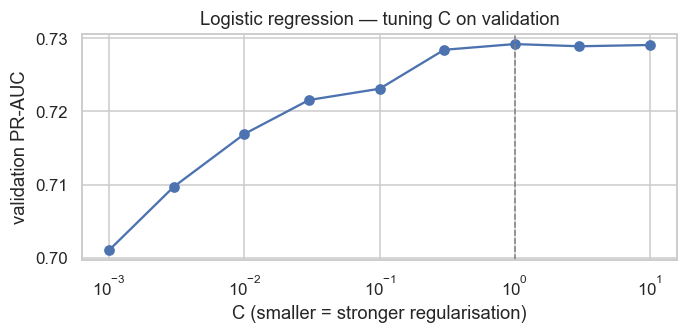

Best C on validation: 1.0
C           0.001   0.003   0.010   0.030   0.100   0.300   1.000   3.000   10.000
val PR-AUC  0.7011  0.7097  0.7169  0.7216  0.7231  0.7284  0.7292  0.7289  0.7291


ROC-AUC  PR-AUC     F1  Precision  Recall  \
model               split                                                   
logistic regression train         0.916   0.612  0.615      0.516   0.762   
                    validation    0.933   0.729  0.706      0.652   0.769   

                                threshold  
model               split                  
logistic regression train           0.247  
                    validation      0.247

In [61]:
c_sweep = pd.DataFrame([{"C": C, "val PR-AUC": val_pr_auc(make_logreg(C).fit(X_train, y_train))}
                        for C in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]])
BEST_C = float(c_sweep.loc[c_sweep["val PR-AUC"].idxmax(), "C"])

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.semilogx(c_sweep["C"], c_sweep["val PR-AUC"], marker="o", color="#4C72B0")
ax.axvline(BEST_C, color="grey", ls="--", lw=1)
ax.set_xlabel("C (smaller = stronger regularisation)"); ax.set_ylabel("validation PR-AUC")
ax.set_title("Logistic regression — tuning C on validation")
save_fig("model_logreg_C")
plt.show()

print("Best C on validation:", BEST_C)
print(c_sweep.set_index("C").T.round(4).to_string())
register("logistic regression", make_logreg(BEST_C).fit(X_train, y_train), lambda: make_logreg(BEST_C))

**Result.** The default `C = 1` is confirmed as the best value. The curve is flat from `C = 0.3` upwards
(0.728–0.729) and falls to 0.701 with very strong regularisation (`C = 0.001`): the model does better
when it is allowed to use its features than when its weights are shrunk.
The baseline reaches validation PR-AUC **0.729**, clearly above the grid rule (0.639).
The plot below shows its weights.

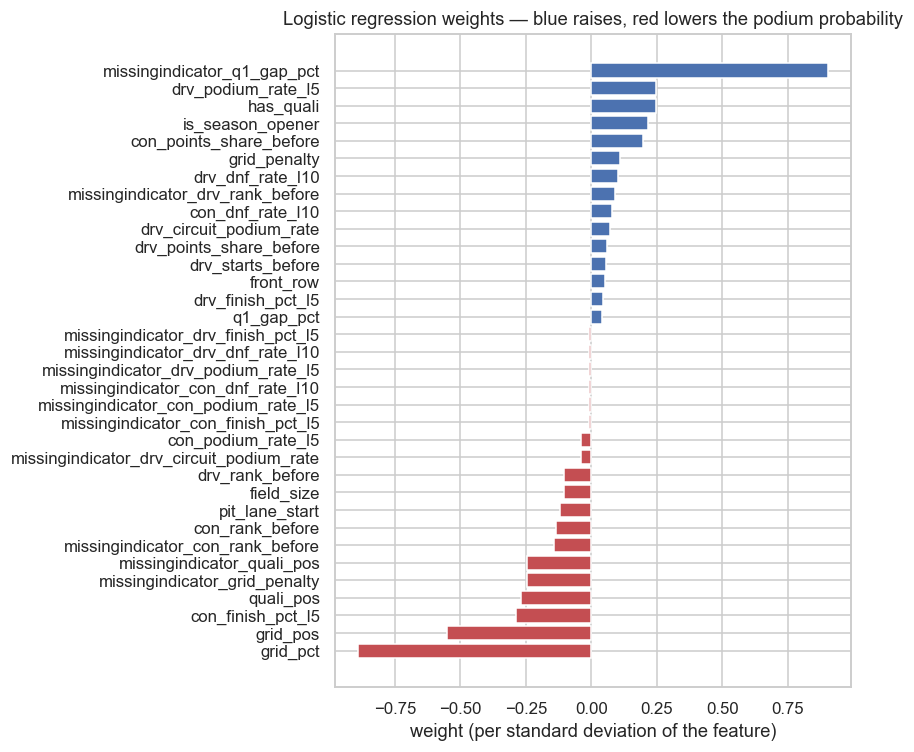

In [62]:
coefs = pd.Series(MODELS["logistic regression"].named_steps["clf"].coef_[0], index=PREP_COLS).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(coefs.index, coefs.values, color=np.where(coefs.values > 0, "#4C72B0", "#C44E52"))
ax.set_xlabel("weight (per standard deviation of the feature)")
ax.set_title("Logistic regression weights — blue raises, red lowers the podium probability")
save_fig("model_logreg_coefficients")
plt.show()

**Reading the weights.** The largest ones belong to the starting position (`grid_pct`, `grid_pos`:
further back → lower probability), then team form (`con_finish_pct_l5`) and driver form
(`drv_podium_rate_l5`). **Caution:** several columns are near-copies of each other
(`has_quali`, `missingindicator_quali_pos`, `missingindicator_q1_gap_pct`, `missingindicator_grid_penalty`),
and their weights are large with opposite signs — they cancel each other. With correlated features
the individual weights of a logistic regression cannot be read one by one, which is why Section 11 uses
permutation importance and SHAP on the original 22 features instead.

### 9.4 Random forest
**How it works:** many decision trees, each trained on a random sample of rows and features; the
forest averages their votes. It can learn curved relationships and interactions (e.g. "a good grid slot
matters more in a fast car") that logistic regression cannot. Trees do not need scaling, so only the
imputation step is used. We tune tree depth and leaf size on validation.

In [63]:
def make_forest(max_depth=8, min_samples_leaf=20):
    return Pipeline([("prep", make_preprocessor(scale=False)),
                     ("clf", RandomForestClassifier(n_estimators=300, max_depth=max_depth,
                                                    min_samples_leaf=min_samples_leaf, class_weight=CLASS_WEIGHT,
                                                    n_jobs=-1, random_state=SEED))])

rows = []
for depth in [4, 6, 8, 12]:
    for leaf in [5, 20, 50]:
        m = make_forest(depth, leaf).fit(X_train, y_train)
        rows.append({"max_depth": depth, "min_samples_leaf": leaf, "val PR-AUC": val_pr_auc(m),
                     "train PR-AUC": average_precision_score(y_train, proba(m, X_train))})
rf_grid = pd.DataFrame(rows).sort_values("val PR-AUC", ascending=False)
RF_BEST = {k: int(rf_grid.iloc[0][k]) for k in ["max_depth", "min_samples_leaf"]}
print("Best on validation:", RF_BEST)
rf_grid.round(4).head(6)

Best on validation: {'max_depth': 12, 'min_samples_leaf': 50}


,max_depth,min_samples_leaf,val PR-AUC,train PR-AUC
11,12,50,0.7250,0.6596
8,8,50,0.7243,0.6569
5,6,50,0.7217,0.6506
4,6,20,0.7215,0.6625
1,4,20,0.7209,0.6376
0,4,5,0.7191,0.6382


In [64]:
register("random forest", make_forest(**RF_BEST).fit(X_train, y_train), lambda: make_forest(**RF_BEST))

ROC-AUC  PR-AUC     F1  Precision  Recall  threshold
model         split                                                           
random forest train         0.931   0.660  0.632      0.526   0.791      0.258
              validation    0.933   0.725  0.715      0.650   0.795      0.258

**Result.** The best forests use large leaves (at least 50 rows) — the data rewards smoothing, not fine
detail. Validation PR-AUC 0.725: no gain over logistic regression (0.729), with a larger train–validation
difference in the recent seasons (§9.7).

### 9.5 Gradient boosting
**How it works:** trees are built one after another, and each new small tree corrects the errors of
the ones before it. `HistGradientBoostingClassifier` handles missing values by itself (each split learns
which side NaN should go to), so no imputation is needed. We tune the learning rate, the number of trees
and their depth on validation.

In [65]:
def make_boosting(learning_rate=0.1, max_iter=100, max_depth=None):
    return HistGradientBoostingClassifier(learning_rate=learning_rate, max_iter=max_iter, max_depth=max_depth,
                                          class_weight=CLASS_WEIGHT, early_stopping=False, random_state=SEED)

rows = []
for lr in [0.02, 0.05, 0.1]:
    for n_trees in [100, 300]:
        for depth in [2, 3, 5]:
            m = make_boosting(lr, n_trees, depth).fit(X_train, y_train)
            rows.append({"learning_rate": lr, "max_iter": n_trees, "max_depth": depth,
                         "val PR-AUC": val_pr_auc(m),
                         "train PR-AUC": average_precision_score(y_train, proba(m, X_train))})
gb_grid = pd.DataFrame(rows).sort_values("val PR-AUC", ascending=False)
GB_BEST = {"learning_rate": float(gb_grid.iloc[0]["learning_rate"]), "max_iter": int(gb_grid.iloc[0]["max_iter"]),
           "max_depth": int(gb_grid.iloc[0]["max_depth"])}
print("Best on validation:", GB_BEST)
print("Untuned defaults (the model used in §7.3):",
      round(val_pr_auc(make_boosting().fit(X_train, y_train)), 4))
gb_grid.round(4).head(6)

Best on validation: {'learning_rate': 0.05, 'max_iter': 100, 'max_depth': 2}


Untuned defaults (the model used in §7.3): 0.6812


,learning_rate,max_iter,max_depth,val PR-AUC,train PR-AUC
6,0.05,100,2,0.7379,0.6329
0,0.02,100,2,0.7365,0.6218
3,0.02,300,2,0.7309,0.6347
4,0.02,300,3,0.7295,0.6511
7,0.05,100,3,0.7266,0.6482
1,0.02,100,3,0.7247,0.6365


In [66]:
register("gradient boosting", make_boosting(**GB_BEST).fit(X_train, y_train), lambda: make_boosting(**GB_BEST))

ROC-AUC  PR-AUC     F1  Precision  Recall  \
model             split                                                   
gradient boosting train         0.923   0.633  0.624      0.520   0.781   
                  validation    0.931   0.738  0.705      0.645   0.778   

                              threshold  
model             split                  
gradient boosting train           0.245  
                  validation      0.245

**Result — tuning matters (before/after).** With default settings gradient boosting scores 0.681 on
validation; tuned, it reaches **0.738**. The winning setting is very simple: 100 trees of depth 2
with a small learning rate. Trees of depth 2 can only combine two features at a time, so the signal in
this table is mostly *additive* — which also explains why a linear model is hard to beat here.

### 9.6 Shallow neural network (Keras)
**How it works:** the scaled features go through one or two *hidden layers* of simple units
(weighted sum + ReLU), then one output unit with a sigmoid gives the podium probability. The weights are
learned by gradient descent (Adam) on the binary cross-entropy loss.

**Against overfitting:** dropout (randomly switching off units during training) and **early stopping** —
training stops when the validation PR-AUC has not improved for 20 epochs, and the best weights are
restored. We compare three sizes on validation.

In [67]:
try:
    import tensorflow as tf
    from tensorflow import keras
    HAVE_TF = True
    print("TensorFlow", tf.__version__)
except Exception as err:                              # fallback so the notebook still runs without TensorFlow
    from sklearn.neural_network import MLPClassifier
    HAVE_TF = False
    print("TensorFlow not available -> using scikit-learn's MLPClassifier instead:", err)

class ShallowNet:
    """Preprocessing + a shallow feed-forward network, with the same fit / predict_proba interface as sklearn."""
    def __init__(self, hidden=(32, 16), dropout=0.3, learning_rate=1e-3, epochs=200, batch_size=128, patience=20):
        self.hidden, self.dropout, self.learning_rate = tuple(hidden), dropout, learning_rate
        self.epochs, self.batch_size, self.patience = epochs, batch_size, patience

    def fit(self, X, y, X_valid, y_valid):
        self.prep_ = make_preprocessor().fit(X)                       # imputation + scaling, training rows only
        Z, Z_valid = self.prep_.transform(X), self.prep_.transform(X_valid)
        if not HAVE_TF:
            self.net_ = MLPClassifier(hidden_layer_sizes=self.hidden, alpha=1e-3, early_stopping=True,
                                      max_iter=300, random_state=SEED).fit(Z, y)
            self.history_ = None
            return self
        keras.utils.set_random_seed(SEED)
        layers = [keras.layers.Input(shape=(Z.shape[1],))]
        for units in self.hidden:
            layers += [keras.layers.Dense(units, activation="relu"), keras.layers.Dropout(self.dropout)]
        layers.append(keras.layers.Dense(1, activation="sigmoid"))
        self.net_ = keras.Sequential(layers)
        self.net_.compile(optimizer=keras.optimizers.Adam(self.learning_rate), loss="binary_crossentropy",
                          metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
        stop = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=self.patience,
                                             restore_best_weights=True)
        weights = None
        if CLASS_WEIGHT == "balanced":
            weights = {0: len(y) / (2 * (y == 0).sum()), 1: len(y) / (2 * (y == 1).sum())}
        self.history_ = self.net_.fit(Z, y.to_numpy(), validation_data=(Z_valid, y_valid.to_numpy()),
                                      epochs=self.epochs, batch_size=self.batch_size, callbacks=[stop],
                                      class_weight=weights, verbose=0).history
        return self

    def predict_proba(self, X):
        Z = self.prep_.transform(X)
        if not HAVE_TF:
            return self.net_.predict_proba(Z)
        p = np.concatenate([self.net_(Z[i:i + 20000].astype("float32"), training=False).numpy().ravel()
                            for i in range(0, len(Z), 20000)])
        return np.column_stack([1 - p, p])

def fit_model(model, X_tr, y_tr, X_va, y_va):
    """Fit any of our models; only the network needs validation rows (for early stopping)."""
    return model.fit(X_tr, y_tr, X_va, y_va) if isinstance(model, ShallowNet) else model.fit(X_tr, y_tr)

2026-10-13 15:48:00.867306: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow 2.16.2


In [68]:
NN_CANDIDATES = {"1 hidden layer (16)": dict(hidden=(16,), dropout=0.2),
                 "2 hidden layers (32, 16)": dict(hidden=(32, 16), dropout=0.3),
                 "2 hidden layers (64, 32)": dict(hidden=(64, 32), dropout=0.3)}
nn_fits, rows = {}, []
for label, params in NN_CANDIDATES.items():
    net = ShallowNet(**params).fit(X_train, y_train, X_val, y_val)
    nn_fits[label] = net
    rows.append({"architecture": label,
                 "epochs run": len(net.history_["loss"]) if net.history_ else np.nan,
                 "train PR-AUC": average_precision_score(y_train, proba(net, X_train)),
                 "val PR-AUC": val_pr_auc(net)})
nn_grid = pd.DataFrame(rows).set_index("architecture")
NN_BEST = nn_grid["val PR-AUC"].idxmax()
print("Best on validation:", NN_BEST)
nn_grid.round(4)

Best on validation: 2 hidden layers (64, 32)


,epochs run,train PR-AUC,val PR-AUC
architecture,,,
1 hidden layer (16),60,0.6310,0.7399
"2 hidden layers (32, 16)",44,0.6315,0.7361
"2 hidden layers (64, 32)",52,0.6409,0.7444


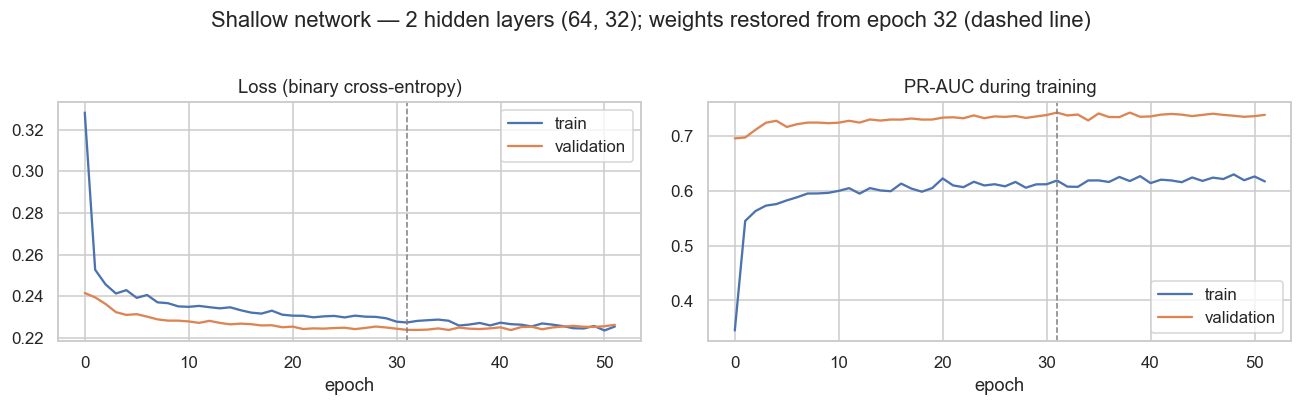

ROC-AUC  PR-AUC     F1  Precision  Recall  \
model                  split                                                   
shallow neural network train         0.926   0.641  0.628      0.529   0.772   
                       validation    0.930   0.744  0.708      0.650   0.778   

                                   threshold  
model                  split                  
shallow neural network train           0.288  
                       validation      0.288

In [69]:
best_net = nn_fits[NN_BEST]
if best_net.history_:
    h = best_net.history_
    best_epoch = int(np.argmax(h["val_pr_auc"])) + 1
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
    ax[0].set_title("Loss (binary cross-entropy)"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["pr_auc"], label="train"); ax[1].plot(h["val_pr_auc"], label="validation")
    ax[1].set_title("PR-AUC during training"); ax[1].set_xlabel("epoch"); ax[1].legend()
    for a in ax:
        a.axvline(best_epoch - 1, color="grey", ls="--", lw=1)
    fig.suptitle(f"Shallow network — {NN_BEST}; weights restored from epoch {best_epoch} (dashed line)", y=1.02)
    save_fig("model_nn_learning_curves")
    plt.show()

register("shallow neural network", best_net, lambda: ShallowNet(**NN_CANDIDATES[NN_BEST]))

**Result.** The three network sizes score within 0.01 of each other on validation (about 0.74), so size
does not matter here. In the curves, validation PR-AUC stops improving after roughly 20–30 epochs while the
training loss keeps creeping down; early stopping restores the best epoch instead of running all 200.
(Validation loss sits below training loss because dropout is only active during training and because
the training seasons include older, harder-to-predict eras — see §9.7.)

### 9.7 Model comparison on train and validation — choosing the final model
All models side by side. The **final model is the one with the highest validation PR-AUC**; its
threshold is the one with the best validation F1. Nothing from the test seasons is used here.

In [70]:
FINAL_NAMES = ["grid rule (top 3)", "logistic regression", "random forest", "gradient boosting",
               "shallow neural network"]
BASELINE = "logistic regression"
learned_models = [n for n in FINAL_NAMES if n != "grid rule (top 3)"]
train_val = report(FINAL_NAMES)

recent = train["year"] >= 2010          # the training seasons that look most like validation
print("Train PR-AUC on the 2010-2019 seasons only:",
      {n: round(average_precision_score(y_train[recent], proba(MODELS[n], X_train[recent])), 3) for n in learned_models})
train_val

Train PR-AUC on the 2010-2019 seasons only: {'logistic regression': 0.701, 'random forest': 0.743, 'gradient boosting': 0.721, 'shallow neural network': 0.716}


ROC-AUC  PR-AUC     F1  Precision  Recall  \
model                  split                                                   
grid rule (top 3)      train         0.898   0.543  0.586      0.586   0.585   
                       validation    0.909   0.639  0.692      0.692   0.692   
logistic regression    train         0.916   0.612  0.615      0.516   0.762   
                       validation    0.933   0.729  0.706      0.652   0.769   
random forest          train         0.931   0.660  0.632      0.526   0.791   
                       validation    0.933   0.725  0.710      0.648   0.786   
gradient boosting      train         0.923   0.633  0.624      0.520   0.781   
                       validation    0.931   0.738  0.705      0.645   0.778   
shallow neural network train         0.926   0.641  0.628      0.529   0.772   
                       validation    0.930   0.744  0.708      0.650   0.778   

                                   threshold  
model                  split                  
grid rule (top 3)      train           0.300  
                       validation      0.300  
logistic regression    train           0.247  
                       validation      0.247  
random forest          train           0.258  
                       validation      0.258  
gradient boosting      train           0.245  
                       validation      0.245  
shallow neural network train           0.288  
                       validation      0.288

**Is any model really better than the baseline?** Validation has only 39 races, so we do not trust a
gap in the third decimal. We resample the validation **races** 1,000 times with replacement (bootstrap —
whole races are drawn, because the 20 rows of one race belong together) and look at the PR-AUC gap
between each model and the baseline.

**Selection rule (fixed before looking at the test set):** take the model with the highest validation
PR-AUC; keep it only if its gap to the baseline is reliably above zero (95% range excludes 0).
Otherwise the simpler baseline stays — extra complexity has to earn its place.

In [71]:
def race_bootstrap(frame, y, model_names, n_boot=1000):
    """PR-AUC of each model on `n_boot` resamples of the races in `frame` (drawn with replacement)."""
    rng = np.random.default_rng(SEED)
    race_rows = {r: np.flatnonzero(frame["raceId"].to_numpy() == r) for r in frame["raceId"].unique()}
    race_ids = np.array(list(race_rows))
    probs = {n: proba(MODELS[n], frame[FEATURES]) for n in model_names}
    y = y.to_numpy()
    out = {n: [] for n in model_names}
    for _ in range(n_boot):
        idx = np.concatenate([race_rows[r] for r in rng.choice(race_ids, size=len(race_ids))])
        for n in model_names:
            out[n].append(average_precision_score(y[idx], probs[n][idx]))
    return pd.DataFrame(out)

boot_val = race_bootstrap(val, y_val, FINAL_NAMES)
gaps = pd.DataFrame({n: boot_val[n] - boot_val[BASELINE] for n in FINAL_NAMES if n != BASELINE})
gap_table = pd.DataFrame({"val PR-AUC": train_val.xs("validation", level="split")["PR-AUC"].drop(BASELINE),
                          "gap to baseline": gaps.mean(), "95% low": gaps.quantile(0.025),
                          "95% high": gaps.quantile(0.975), "better in % of resamples": (gaps > 0).mean() * 100})

TOP_NAME = train_val.xs("validation", level="split").loc[learned_models, "PR-AUC"].idxmax()
earns_it = TOP_NAME != BASELINE and gap_table.loc[TOP_NAME, "95% low"] > 0
BEST_NAME = TOP_NAME if (TOP_NAME == BASELINE or earns_it) else BASELINE

print(f"Baseline ({BASELINE}) validation PR-AUC: {train_val.loc[(BASELINE, 'validation'), 'PR-AUC']:.3f}")
print(f"Highest validation PR-AUC: {TOP_NAME}")
print(f"Reliably better than the baseline? {'yes' if earns_it else 'no'}")
print(f"FINAL MODEL: {BEST_NAME}  |  decision threshold: {THRESHOLDS[BEST_NAME]:.3f}")
gap_table.round(3)

Baseline (logistic regression) validation PR-AUC: 0.729
Highest validation PR-AUC: shallow neural network
Reliably better than the baseline? no
FINAL MODEL: logistic regression  |  decision threshold: 0.247


,val PR-AUC,gap to baseline,95% low,95% high,better in % of resamples
grid rule (top 3),0.639,-0.092,-0.148,-0.032,0.2
random forest,0.725,-0.002,-0.020,0.015,39.6
gradient boosting,0.738,0.007,-0.019,0.033,71.3
shallow neural network,0.744,0.013,-0.019,0.047,75.0


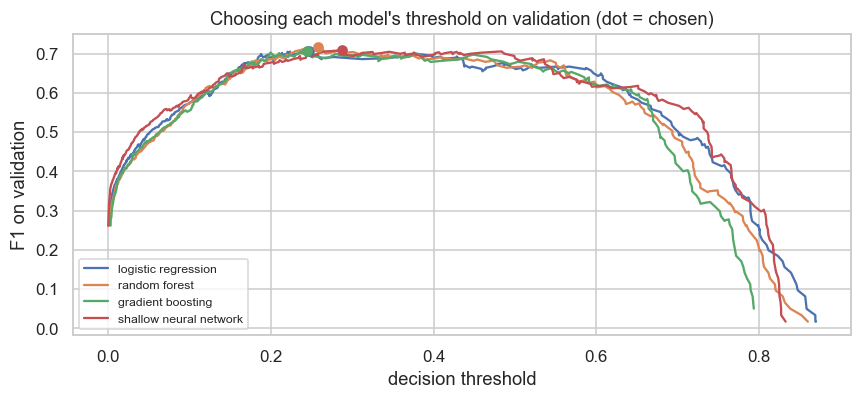

In [72]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for name in learned_models:
    precision, recall, thresholds = precision_recall_curve(y_val, proba(MODELS[name], X_val))
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    line, = ax.plot(thresholds, f1[:-1], label=name)
    ax.scatter([THRESHOLDS[name]], [f1[:-1].max()], color=line.get_color(), zorder=3)
ax.set_xlabel("decision threshold"); ax.set_ylabel("F1 on validation")
ax.set_title("Choosing each model's threshold on validation (dot = chosen)"); ax.legend(fontsize=8)
save_fig("model_thresholds")
plt.show()

**Decision: the final model is the logistic regression (threshold 0.247).**
- All four trained models land between 0.725 and 0.744 validation PR-AUC — far above the grid rule
  (0.639), but very close to each other.
- The network has the highest number (0.744), but its gap to the baseline is +0.013 with a 95% range
  of −0.019 to +0.047, so it is not reliably better. By our rule the baseline stays: it is simpler,
  its weights can be inspected, it trains in a second and gives the same result on every run.
- **Why is train PR-AUC lower than validation for every model?** Not a bug: training covers 1981–2019,
  including seasons with up to 29 starters and much higher retirement rates (§2.7), where podiums are
  harder to predict. On the 2010–2019 training seasons the scores are 0.70–0.74, in line with validation. The
  random forest is the only model clearly better on recent training seasons (0.743) than on validation
  (0.725), a sign of mild overfitting.
- The best thresholds are all near 0.25, not 0.5: with 15% podiums, the best F1 needs a lower bar.

### 9.8 Final evaluation on the unseen test seasons (2022–2024)
Every hyperparameter, threshold and the choice of the final model are now frozen. This is the only
cell group that touches the test set.

In [73]:
comparison = report(FINAL_NAMES, splits=("train", "validation", "test"))
comparison.to_csv(os.path.join(FIG_DIR, "model_comparison.csv"))
comparison

ROC-AUC  PR-AUC     F1  Precision  Recall  \
model                  split                                                   
grid rule (top 3)      train         0.898   0.543  0.586      0.586   0.585   
                       validation    0.909   0.639  0.692      0.692   0.692   
                       test          0.914   0.647  0.649      0.650   0.647   
logistic regression    train         0.916   0.612  0.615      0.516   0.762   
                       validation    0.933   0.729  0.706      0.652   0.769   
                       test          0.938   0.722  0.681      0.569   0.848   
random forest          train         0.931   0.660  0.632      0.526   0.791   
                       validation    0.933   0.725  0.710      0.648   0.786   
                       test          0.941   0.720  0.677      0.564   0.848   
gradient boosting      train         0.923   0.633  0.624      0.520   0.781   
                       validation    0.931   0.738  0.705      0.645   0.778   
                       test          0.939   0.705  0.677      0.568   0.838   
shallow neural network train         0.926   0.641  0.628      0.529   0.772   
                       validation    0.930   0.744  0.708      0.650   0.778   
                       test          0.937   0.725  0.686      0.593   0.814   

                                   threshold  
model                  split                  
grid rule (top 3)      train           0.300  
                       validation      0.300  
                       test            0.300  
logistic regression    train           0.247  
                       validation      0.247  
                       test            0.247  
random forest          train           0.258  
                       validation      0.258  
                       test            0.258  
gradient boosting      train           0.245  
                       validation      0.245  
                       test            0.245  
shallow neural network train           0.288  
                       validation      0.288  
                       test            0.288

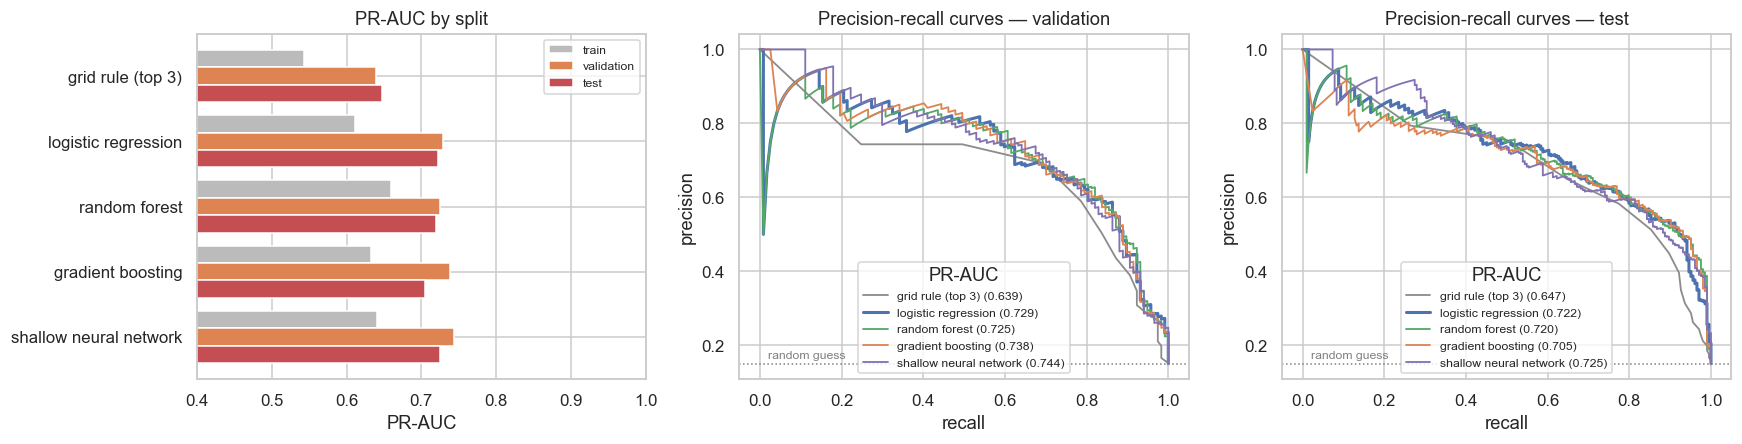

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
colors = dict(zip(FINAL_NAMES, ["#8C8C8C", "#4C72B0", "#55A868", "#DD8452", "#8172B2"]))

pr = comparison["PR-AUC"].unstack("split")[["train", "validation", "test"]].loc[FINAL_NAMES]
pr.plot(kind="barh", ax=axes[0], color=["#BBBBBB", "#DD8452", "#C44E52"], width=0.8)
axes[0].invert_yaxis(); axes[0].set_xlabel("PR-AUC"); axes[0].set_ylabel("")
axes[0].set_title("PR-AUC by split"); axes[0].set_xlim(0.4, 1.0); axes[0].legend(fontsize=8)

for ax, split in zip(axes[1:], ["validation", "test"]):
    X, y = SPLITS[split]
    for name in FINAL_NAMES:
        precision, recall, _ = precision_recall_curve(y, proba(MODELS[name], X))
        ax.plot(recall, precision, color=colors[name], lw=2 if name == BEST_NAME else 1.2,
                label=f"{name} ({comparison.loc[(name, split), 'PR-AUC']:.3f})")
    ax.axhline(y.mean(), color="grey", ls=":", lw=1)
    ax.text(0.02, y.mean() + 0.015, "random guess", color="grey", fontsize=8)
    ax.set_xlabel("recall"); ax.set_ylabel("precision")
    ax.set_title(f"Precision-recall curves — {split}"); ax.legend(fontsize=8, title="PR-AUC")
save_fig("model_comparison")
plt.show()

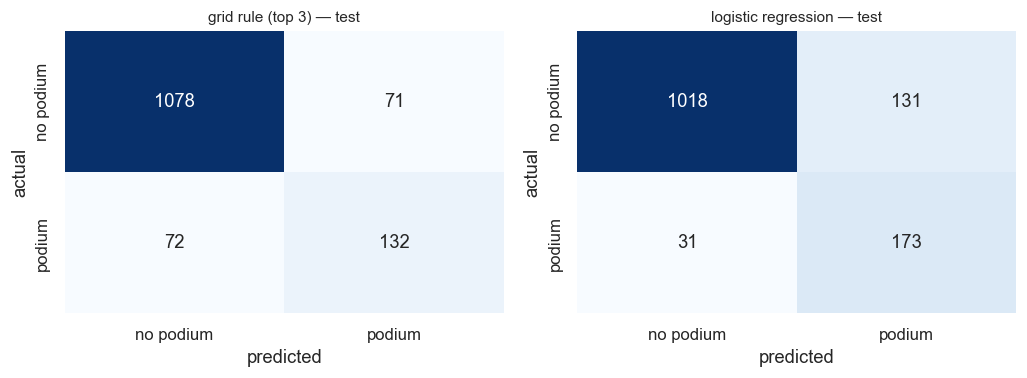

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
for ax, name in zip(axes, ["grid rule (top 3)", BEST_NAME]):
    cm = confusion_matrix(y_test, proba(MODELS[name], X_test) >= THRESHOLDS[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no podium", "podium"], yticklabels=["no podium", "podium"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(f"{name} — test", fontsize=10)
save_fig("model_confusion_matrix")
plt.show()

**Can the output be read as a probability?** Rows are grouped by predicted probability; in each group
we compare the average prediction with the share that really finished on the podium. Points on the
diagonal mean "when the model says 60%, about 60% of those drivers do podium".

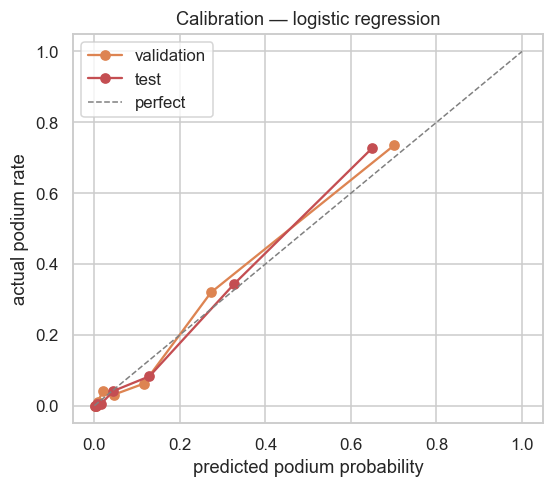

{'validation': 'mean predicted 0.146 vs actual 0.150', 'test': 'mean predicted 0.147 vs actual 0.151'}


In [76]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(5.2, 4.6))
for split, color in [("validation", "#DD8452"), ("test", "#C44E52")]:
    X, y = SPLITS[split]
    actual, predicted = calibration_curve(y, proba(MODELS[BEST_NAME], X), n_bins=8, strategy="quantile")
    ax.plot(predicted, actual, marker="o", color=color, label=split)
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="perfect")
ax.set_xlabel("predicted podium probability"); ax.set_ylabel("actual podium rate")
ax.set_title(f"Calibration — {BEST_NAME}"); ax.legend()
save_fig("model_calibration")
plt.show()
print({s: f"mean predicted {proba(MODELS[BEST_NAME], SPLITS[s][0]).mean():.3f} vs actual {SPLITS[s][1].mean():.3f}"
       for s in ["validation", "test"]})

**Test results.**
- The final model keeps its performance on unseen seasons: PR-AUC **0.722** on test vs 0.729 on
  validation, ROC-AUC 0.938. No sign of overfitting to the validation seasons.
- At the frozen threshold, F1 is 0.681 (precision 0.57, recall 0.85). Compared with validation
  (0.65 / 0.77) the same threshold catches more podiums but raises more false alarms — the best
  threshold drifts a little between seasons, and we deliberately did not re-tune it on test.
- Every trained model beats the grid rule (PR-AUC 0.647, F1 0.649) and all of them are within 0.02 of each other.
- The calibration plot follows the diagonal and the average prediction (0.147) matches the real podium
  rate (0.151), so the output can be read as a probability. It is not perfect: the most confident group
  (predicted ≈ 0.65–0.70) actually podiums a little more often (≈ 0.73).

### 9.9 Are the differences between models real?
The test set has only 68 races, so a small gap between two models can be luck. We resample the test
**races** 1,000 times with replacement (bootstrap; whole races are drawn, because the 20 rows of one race
belong together) and recompute PR-AUC each time. This gives a 95% range for each model and for the gap
between the final model and the two baselines.

Test PR-AUC, 95% bootstrap range (races resampled):
                         2.5%  median  97.5%
grid rule (top 3)       0.592   0.649  0.709
logistic regression     0.660   0.724  0.785
random forest           0.662   0.722  0.783
gradient boosting       0.642   0.706  0.772
shallow neural network  0.671   0.726  0.779 

logistic regression minus grid rule (top 3): +0.074  (95% range +0.027 to +0.115; better in 100% of resamples)
logistic regression minus random forest: +0.001  (95% range -0.017 to +0.018; better in 54% of resamples)
logistic regression minus gradient boosting: +0.016  (95% range -0.003 to +0.035; better in 95% of resamples)
logistic regression minus shallow neural network: -0.002  (95% range -0.031 to +0.026; better in 45% of resamples)


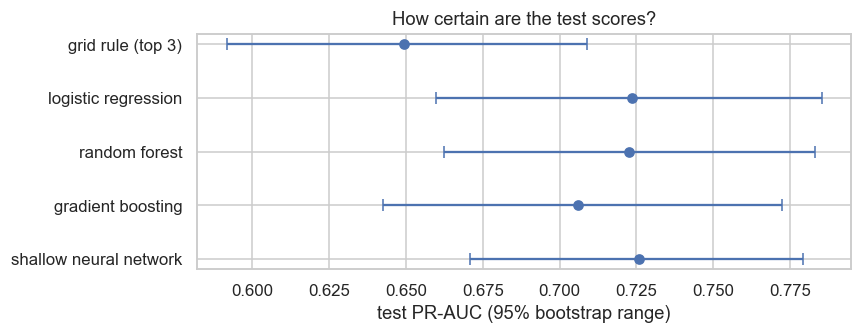

In [77]:
boot = race_bootstrap(test, y_test, FINAL_NAMES)

ci = boot.quantile([0.025, 0.5, 0.975]).T
ci.columns = ["2.5%", "median", "97.5%"]
print("Test PR-AUC, 95% bootstrap range (races resampled):")
print(ci.round(3), "\n")
for other in [n for n in FINAL_NAMES if n != BEST_NAME]:
    d = boot[BEST_NAME] - boot[other]
    print(f"{BEST_NAME} minus {other}: {d.mean():+.3f}  "
          f"(95% range {d.quantile(0.025):+.3f} to {d.quantile(0.975):+.3f}; better in {(d > 0).mean():.0%} of resamples)")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(ci["median"], range(len(ci)), xerr=[ci["median"] - ci["2.5%"], ci["97.5%"] - ci["median"]],
            fmt="o", color="#4C72B0", capsize=4)
ax.set_yticks(range(len(ci))); ax.set_yticklabels(ci.index); ax.invert_yaxis()
ax.set_xlabel("test PR-AUC (95% bootstrap range)"); ax.set_title("How certain are the test scores?")
save_fig("model_bootstrap")
plt.show()

**Result.** The test PR-AUC of the final model is 0.72 with a 95% range of about 0.66–0.79: 68 races
cannot pin it down more precisely. Within that uncertainty:
- **Model vs grid rule: a real gain.** +0.074 PR-AUC (95% range +0.027 to +0.115; better in every resample).
  The engineered features add information beyond the starting order.
- **Model vs model: no real difference.** The gaps between logistic regression, random forest,
  gradient boosting and the network all include zero. Test confirms what validation said.

### 9.10 Limitations of each model

| Model | Main limitations |
|---|---|
| Grid rule | One feature; ignores car and driver strength; cannot give a probability |
| Logistic regression (final) | Each feature has one straight-line effect and there are no interactions unless we build them; weights of correlated features are unstable (§9.3); sensitive to outliers such as large `q1_gap_pct` values |
| Random forest | Needs imputation; fits the training seasons more closely than it generalises; cannot extrapolate beyond what it has seen; slow to explain |
| Gradient boosting | Very sensitive to its settings (0.681 → 0.738); with defaults it overfits old seasons |
| Shallow neural network | Results change slightly from run to run and between library versions; needs scaling, early stopping and a validation set just to train; a black box without XAI tools |
| All of them | Trained on 1981–2019, used on 2022–2024: new rules, new teams and renamed constructors are only seen through recent form. Crashes, mechanical failures, weather and safety cars are not predictable from pre-race data, which caps the achievable score |

## 10. Feature-group ablation
Section 6 justified each feature group *before* training. Ablation measures what each group actually
contributes *after* training: we retrain the final model five times, each time **without one group**,
and see how much PR-AUC falls. As a second view we also train it on **one group alone**.
The baseline logistic regression is ablated too, to check that the conclusions do not depend on the model.

In [78]:
def fit_and_score(name, columns):
    """Retrain model `name` (same hyperparameters) on a subset of columns; PR-AUC on validation and test."""
    m = fit_model(BUILDERS[name](), X_train[columns], y_train, X_val[columns], y_val)
    return (average_precision_score(y_val, proba(m, X_val[columns])),
            average_precision_score(y_test, proba(m, X_test[columns])))

ablation_models = list(dict.fromkeys([BEST_NAME, "logistic regression", "gradient boosting"]))[:2]
START_INFO = FEATURE_GROUPS["grid"] + FEATURE_GROUPS["qualifying"]      # everything about the starting order
rows = []
for name in ablation_models:
    full_val, full_test = fit_and_score(name, FEATURES)
    rows.append({"model": name, "features": "all 22 features", "n": len(FEATURES), "val PR-AUC": full_val,
                 "test PR-AUC": full_test, "val drop": 0.0, "test drop": 0.0})
    for group, cols in FEATURE_GROUPS.items():
        kept = [f for f in FEATURES if f not in cols]
        v, t = fit_and_score(name, kept)
        rows.append({"model": name, "features": f"without {group}", "n": len(kept), "val PR-AUC": v,
                     "test PR-AUC": t, "val drop": full_val - v, "test drop": full_test - t})
    kept = [f for f in FEATURES if f not in START_INFO]
    v, t = fit_and_score(name, kept)
    rows.append({"model": name, "features": "without grid + qualifying", "n": len(kept), "val PR-AUC": v,
                 "test PR-AUC": t, "val drop": full_val - v, "test drop": full_test - t})
    for group, cols in FEATURE_GROUPS.items():
        v, t = fit_and_score(name, cols)
        rows.append({"model": name, "features": f"only {group}", "n": len(cols), "val PR-AUC": v,
                     "test PR-AUC": t, "val drop": full_val - v, "test drop": full_test - t})
ablation = pd.DataFrame(rows).set_index(["model", "features"])
ablation.to_csv(os.path.join(FIG_DIR, "ablation.csv"))
ablation.round(4)

n  val PR-AUC  test PR-AUC  \
model               features                                                 
logistic regression all 22 features            22      0.7292       0.7217   
                    without grid               17      0.7093       0.7047   
                    without qualifying         18      0.7141       0.7186   
                    without driver_form        17      0.7100       0.7181   
                    without constructor_form   19      0.7356       0.7162   
                    without standings          17      0.7193       0.7218   
                    without grid + qualifying  13      0.6300       0.5706   
                    only grid                   5      0.6406       0.6453   
                    only qualifying             4      0.6863       0.6838   
                    only driver_form            5      0.6419       0.5300   
                    only constructor_form       3      0.5329       0.5103   
                    only standings              5      0.6227       0.5604   
gradient boosting   all 22 features            22      0.7379       0.7048   
                    without grid               17      0.7313       0.6992   
                    without qualifying         18      0.7139       0.7031   
                    without driver_form        17      0.7212       0.7151   
                    without constructor_form   19      0.7377       0.7151   
                    without standings          17      0.7190       0.7053   
                    without grid + qualifying  13      0.6475       0.5685   
                    only grid                   5      0.6475       0.6548   
                    only qualifying             4      0.6847       0.6662   
                    only driver_form            5      0.6369       0.5526   
                    only constructor_form       3      0.5445       0.5036   
                    only standings              5      0.6291       0.5430   

                                               val drop  test drop  
model               features                                        
logistic regression all 22 features              0.0000     0.0000  
                    without grid                 0.0199     0.0170  
                    without qualifying           0.0151     0.0031  
                    without driver_form          0.0192     0.0037  
                    without constructor_form    -0.0064     0.0055  
                    without standings            0.0099    -0.0001  
                    without grid + qualifying    0.0992     0.1512  
                    only grid                    0.0886     0.0764  
                    only qualifying              0.0429     0.0380  
                    only driver_form             0.0873     0.1917  
                    only constructor_form        0.1963     0.2115  
                    only standings               0.1065     0.1613  
gradient boosting   all 22 features              0.0000     0.0000  
                    without grid                 0.0066     0.0056  
                    without qualifying           0.0239     0.0017  
                    without driver_form          0.0167    -0.0103  
                    without constructor_form     0.0002    -0.0104  
                    without standings            0.0189    -0.0005  
                    without grid + qualifying    0.0904     0.1362  
                    only grid                    0.0904     0.0500  
                    only qualifying              0.0532     0.0385  
                    only driver_form             0.1010     0.1522  
                    only constructor_form        0.1934     0.2011  
                    only standings               0.1088     0.1618

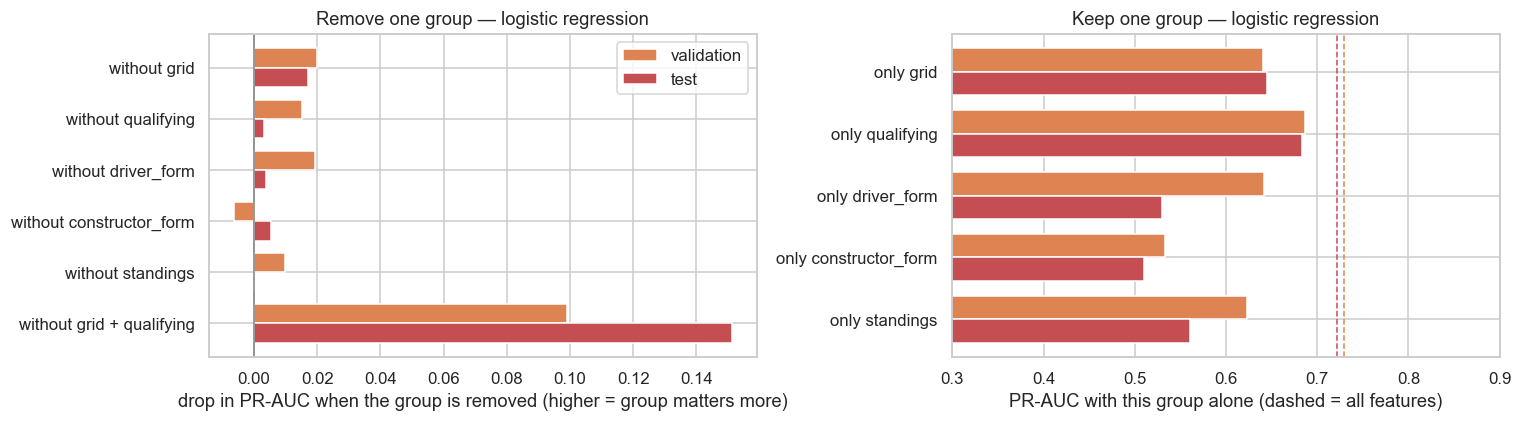

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
a = ablation.loc[BEST_NAME]
without = a[a.index.str.startswith("without")]
y_pos = np.arange(len(without)); w = 0.38
axes[0].barh(y_pos - w/2, without["val drop"], w, label="validation", color="#DD8452")
axes[0].barh(y_pos + w/2, without["test drop"], w, label="test", color="#C44E52")
axes[0].set_yticks(y_pos); axes[0].set_yticklabels(without.index); axes[0].invert_yaxis()
axes[0].axvline(0, color="grey", lw=1)
axes[0].set_xlabel("drop in PR-AUC when the group is removed (higher = group matters more)")
axes[0].set_title(f"Remove one group — {BEST_NAME}"); axes[0].legend()

only = a[a.index.str.startswith("only")]
y_pos = np.arange(len(only))
axes[1].barh(y_pos - w/2, only["val PR-AUC"], w, label="validation", color="#DD8452")
axes[1].barh(y_pos + w/2, only["test PR-AUC"], w, label="test", color="#C44E52")
axes[1].axvline(a.loc["all 22 features", "val PR-AUC"], color="#DD8452", ls="--", lw=1)
axes[1].axvline(a.loc["all 22 features", "test PR-AUC"], color="#C44E52", ls="--", lw=1)
axes[1].set_yticks(y_pos); axes[1].set_yticklabels(only.index); axes[1].invert_yaxis()
axes[1].set_xlabel("PR-AUC with this group alone (dashed = all features)")
axes[1].set_title(f"Keep one group — {BEST_NAME}"); axes[1].set_xlim(0.3, 0.9)
save_fig("ablation")
plt.show()

**Ablation results (final model: logistic regression).**

| Removed group | Validation drop | Test drop |
|---|---|---|
| grid | 0.020 | 0.017 |
| qualifying | 0.015 | 0.003 |
| driver form | 0.019 | 0.004 |
| standings | 0.010 | 0.000 |
| constructor form | −0.006 | 0.006 |
| **grid + qualifying together** | **0.099** | **0.151** |

- **No single group is indispensable.** Removing any one of them costs at most 0.02 PR-AUC, which is about
  the noise level of our validation set. The reason is redundancy (§6.11): grid and qualifying carry
  almost the same information (ρ = 0.98), and form and standings overlap too.
- **The starting order is the core.** Removing grid *and* qualifying together costs 0.10 on validation and
  0.15 on test — by far the largest drop.
- **History adds on top.** Qualifying alone reaches 0.686 and grid alone 0.641; all 22 features reach
  0.729. Form and standings are worth roughly 0.04–0.09 PR-AUC over the starting order alone, the same
  gain we measured against the grid rule in §9.9. On their own they are much weaker, especially on test
  (driver form 0.53, standings 0.56, constructor form 0.51).
- **Constructor form adds nothing measurable** once driver form and constructor standings are present
  (−0.006 on validation, +0.006 on test: noise). We keep it: the feature set was fixed before the test
  set was opened, and dropping a group because of a 0.006 difference would be fitting noise.
- Gradient boosting gives the same picture (0.09 / 0.14 for grid + qualifying, small drops otherwise),
  so the conclusion does not depend on the model.

## 11. Explainability (XAI)
Which features does the final model rely on, overall and for one specific prediction?

> **Important — importance is not causation.** Everything in this section describes *what the model
> uses to make its predictions*. It does **not** show what *causes* a podium. For example, a high
> importance for qualifying position does not prove that qualifying well causes a podium: a fast car
> and a good driver produce both. Also, correlated features (§6.11) share their importance, so a single
> feature's bar can look small even though the information it carries is essential.

### 11.1 Global — permutation importance
Take the validation rows, **shuffle one feature** (so it no longer carries information) and measure how
much PR-AUC falls. A big fall means the model depends on that feature. We repeat each shuffle 30 times.
Because twins such as `grid_pos` / `quali_pos` can cover for each other, we also shuffle each **whole
feature group** at once.

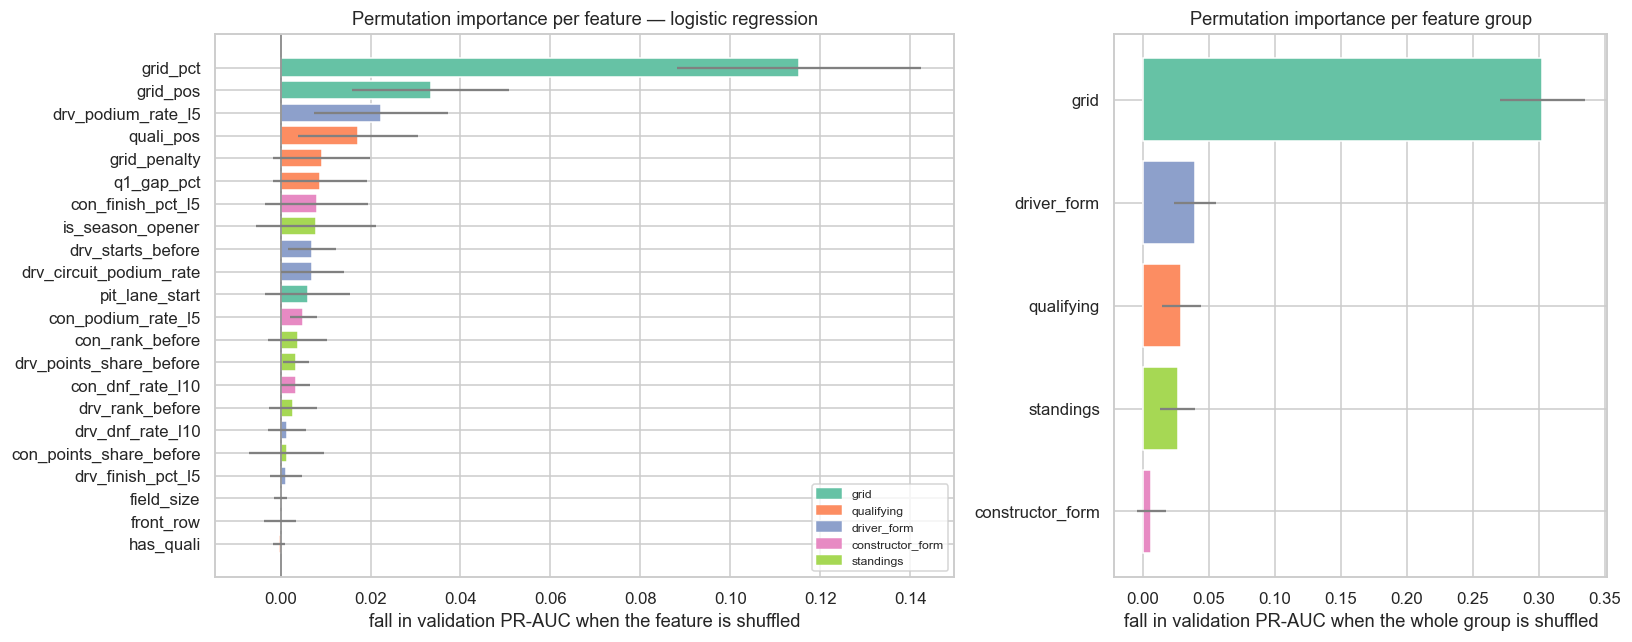

           group   drop    std
            grid 0.3026 0.0322
     driver_form 0.0397 0.0158
      qualifying 0.0291 0.0148
       standings 0.0262 0.0130
constructor_form 0.0063 0.0109 



,feature,group,drop,std
1,grid_pct,grid,0.1152,0.0271
0,grid_pos,grid,0.0334,0.0174
10,drv_podium_rate_l5,driver_form,0.0223,0.0149
5,quali_pos,qualifying,0.0172,0.0134
7,grid_penalty,qualifying,0.0091,0.0108
6,q1_gap_pct,qualifying,0.0088,0.0105
15,con_finish_pct_l5,constructor_form,0.0080,0.0114
21,is_season_opener,standings,0.0080,0.0133
9,drv_starts_before,driver_form,0.0070,0.0053
13,drv_circuit_podium_rate,driver_form,0.0070,0.0070


In [80]:
final_model = MODELS[BEST_NAME]

def permutation_drop(model, X, y, columns, n_repeats=30):
    """Average fall in PR-AUC when `columns` are shuffled together (rows keep their other features)."""
    rng = np.random.default_rng(SEED)
    base = average_precision_score(y, proba(model, X))
    drops = []
    for _ in range(n_repeats):
        Xp = X.copy()
        Xp[columns] = X[columns].to_numpy()[rng.permutation(len(X))]
        drops.append(base - average_precision_score(y, proba(model, Xp)))
    return np.mean(drops), np.std(drops)

feature_group = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}
perm = pd.DataFrame([(f, feature_group[f], *permutation_drop(final_model, X_val, y_val, [f])) for f in FEATURES],
                    columns=["feature", "group", "drop", "std"]).sort_values("drop", ascending=False)
perm_group = pd.DataFrame([(g, *permutation_drop(final_model, X_val, y_val, cols))
                           for g, cols in FEATURE_GROUPS.items()],
                          columns=["group", "drop", "std"]).sort_values("drop", ascending=False)

palette = dict(zip(FEATURE_GROUPS, sns.color_palette("Set2", len(FEATURE_GROUPS))))
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].barh(perm["feature"][::-1], perm["drop"][::-1], xerr=perm["std"][::-1],
             color=perm["group"].map(palette)[::-1], ecolor="grey")
axes[0].axvline(0, color="grey", lw=1)
axes[0].set_xlabel("fall in validation PR-AUC when the feature is shuffled")
axes[0].set_title(f"Permutation importance per feature — {BEST_NAME}")
axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()], palette.keys(),
               loc="lower right", fontsize=8)
axes[1].barh(perm_group["group"][::-1], perm_group["drop"][::-1], xerr=perm_group["std"][::-1],
             color=perm_group["group"].map(palette)[::-1], ecolor="grey")
axes[1].set_xlabel("fall in validation PR-AUC when the whole group is shuffled")
axes[1].set_title("Permutation importance per feature group")
save_fig("xai_permutation_importance")
plt.show()
print(perm_group.round(4).to_string(index=False), "\n")
perm.head(10).round(4)

**Result.** The model leans most on the **grid group**: shuffling it cuts validation PR-AUC by 0.30
(from 0.73 to about 0.43). The other groups cost 0.01–0.04 each. The top single features are `grid_pct`
(0.115), `grid_pos` (0.033), `drv_podium_rate_l5` (0.022) and `quali_pos` (0.017).

**Permutation vs ablation — why the numbers differ.** Shuffling grid costs 0.30, but *removing* grid and
retraining cost only 0.02 (§10). Both are correct; they answer different questions. Permutation asks
"what does **this trained model** rely on?" — it relies on grid. Ablation asks "what information is
**irreplaceable**?" — grid is replaceable, because a retrained model gets the same information from
qualifying. This is also why single-feature bars understate twins like `grid_pos` / `quali_pos`.

### 11.2 Global — SHAP
SHAP splits each individual prediction into one contribution per feature: how far that feature's
value pushed this prediction above or below the average prediction. Looking at many rows at once gives a
global picture. We explain 300 test rows; contributions are in probability units.
(The explainer is model-agnostic: it only calls the model's prediction function, so it works for
whichever model won in §9.7.)

Average prediction on the background rows (SHAP base value): 0.175


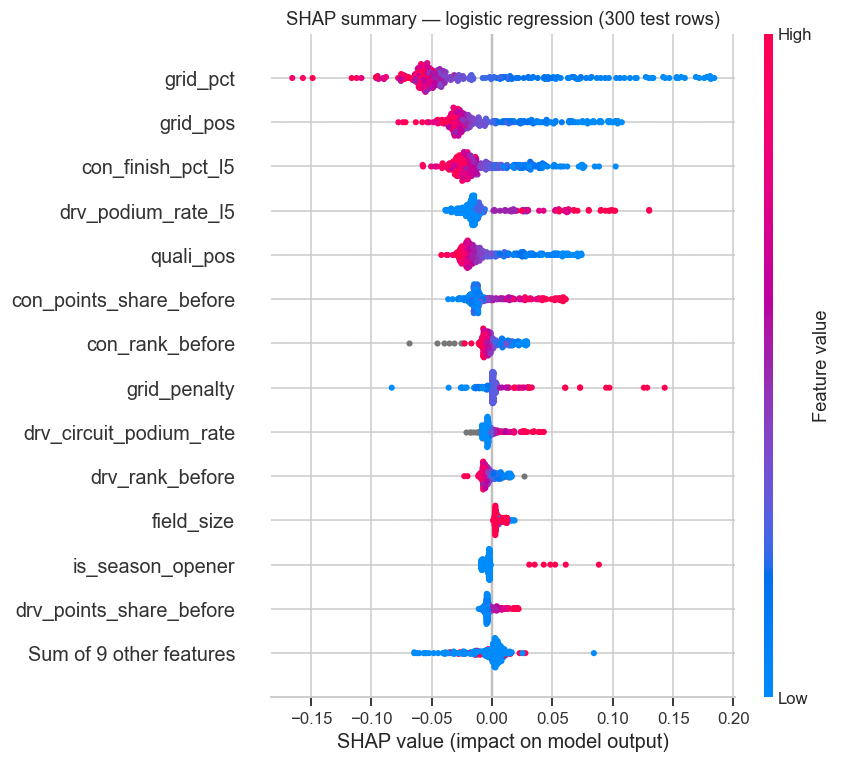

In [81]:
import shap

def predict_fn(data):
    """Prediction function for SHAP / LIME: a plain array in, podium probabilities out."""
    return proba(final_model, pd.DataFrame(np.asarray(data, dtype=float), columns=FEATURES))

background = X_train[X_train.index.isin(train[train["year"] >= 2010].index)].sample(100, random_state=SEED)
explainer = shap.Explainer(predict_fn, shap.maskers.Independent(background, max_samples=100),
                           feature_names=FEATURES, seed=SEED)
X_explain = X_test.sample(300, random_state=SEED)
shap_values = explainer(X_explain, silent=True)
print("Average prediction on the background rows (SHAP base value):", round(float(np.mean(shap_values.base_values)), 3))

shap.plots.beeswarm(shap_values, max_display=14, show=False)
plt.title(f"SHAP summary — {BEST_NAME} (300 test rows)")
save_fig("xai_shap_summary")
plt.show()

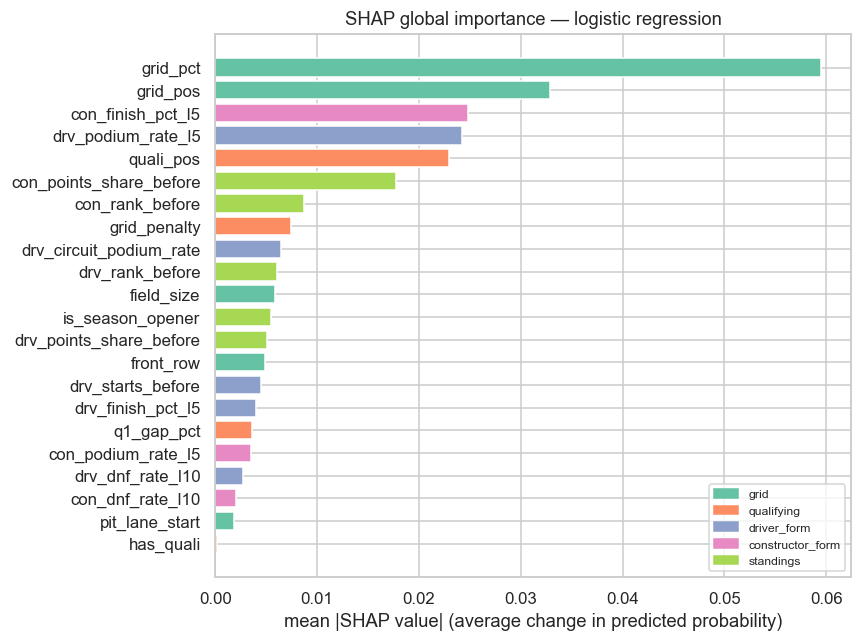

group
grid                0.1050
standings           0.0432
driver_form         0.0420
qualifying          0.0341
constructor_form    0.0303
Name: mean |SHAP|, dtype: float64


In [82]:
shap_importance = pd.DataFrame({"feature": FEATURES, "group": [feature_group[f] for f in FEATURES],
                                "mean |SHAP|": np.abs(shap_values.values).mean(axis=0)}
                               ).sort_values("mean |SHAP|", ascending=False)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(shap_importance["feature"][::-1], shap_importance["mean |SHAP|"][::-1],
        color=shap_importance["group"].map(palette)[::-1])
ax.set_xlabel("mean |SHAP value| (average change in predicted probability)")
ax.set_title(f"SHAP global importance — {BEST_NAME}")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()], palette.keys(),
          loc="lower right", fontsize=8)
save_fig("xai_shap_bar")
plt.show()
print(shap_importance.groupby("group")["mean |SHAP|"].sum().sort_values(ascending=False).round(4))

**Reading the SHAP plots.** Each dot is one driver-race; red = high feature value, blue = low; right of
zero = pushes the prediction up.
- `grid_pct` and `grid_pos`: low values (front of the grid, blue) push the probability up by as much as
  +0.18; starting at the back pulls it down. `quali_pos` behaves the same way.
- `con_finish_pct_l5` (low = the team has been finishing near the front) and `drv_podium_rate_l5`
  (high = recent podiums) come next, then the constructor's points share.
- Grey dots are missing values (e.g. no championship rank at a season opener).
- By group: grid 0.105, standings 0.043, driver form 0.042, qualifying 0.034, constructor form 0.030.

SHAP and permutation importance agree that the starting position dominates. SHAP gives team form more
weight than permutation does, because it measures how much the *predicted probabilities move*, while
permutation measures how much the *ranking quality* suffers. Neither is a causal statement: the model
uses grid position because it summarises car speed and driver skill, not because the grid slot itself
produces podiums.

### 11.3 Local — one prediction explained (SHAP waterfall + LIME)
We pick a case where the model was confident and **wrong**: among test rows that started from pole
and did **not** finish on the podium, the one with the highest predicted probability. Explaining a
mistake is more instructive than explaining an easy hit.

In [83]:
names = clean["drivers"].set_index("driverId")
test_view = test.assign(proba=proba(final_model, X_test))
candidates = test_view[(test_view["grid_pos"] == 1) & (test_view[TARGET] == 0) & X_test.notna().all(axis=1)]
case = candidates.sort_values("proba", ascending=False).iloc[[0]]
case_id = case.index[0]
driver = names.loc[case["driverId"].iloc[0]]
finish = int(df.loc[(df["raceId"] == case["raceId"].iloc[0]) & (df["driverId"] == case["driverId"].iloc[0]),
                    "positionOrder"].iloc[0])
status = df.loc[(df["raceId"] == case["raceId"].iloc[0]) & (df["driverId"] == case["driverId"].iloc[0]), "status"].iloc[0]
CASE_LABEL = f"{driver['forename']} {driver['surname']}, {int(case['year'].iloc[0])} {case['name'].iloc[0]}"
print(f"Pole-sitters without a podium in the test seasons: {len(candidates)}")
print(f"Explained case: {CASE_LABEL}")
print(f"Predicted podium probability: {case['proba'].iloc[0]:.3f}  (threshold {THRESHOLDS[BEST_NAME]:.3f})"
      f"  |  actual result: P{finish}, status = {status}")
X_test.loc[[case_id]].T.rename(columns={case_id: "value"}).round(3)

Pole-sitters without a podium in the test seasons: 14
Explained case: Max Verstappen, 2024 Australian Grand Prix
Predicted podium probability: 0.866  (threshold 0.247)  |  actual result: P19, status = Brakes


,value
grid_pos,1.000
grid_pct,0.053
front_row,1.000
pit_lane_start,0.000
field_size,19.000
quali_pos,1.000
q1_gap_pct,0.115
grid_penalty,0.000
has_quali,1.000
drv_starts_before,187.000


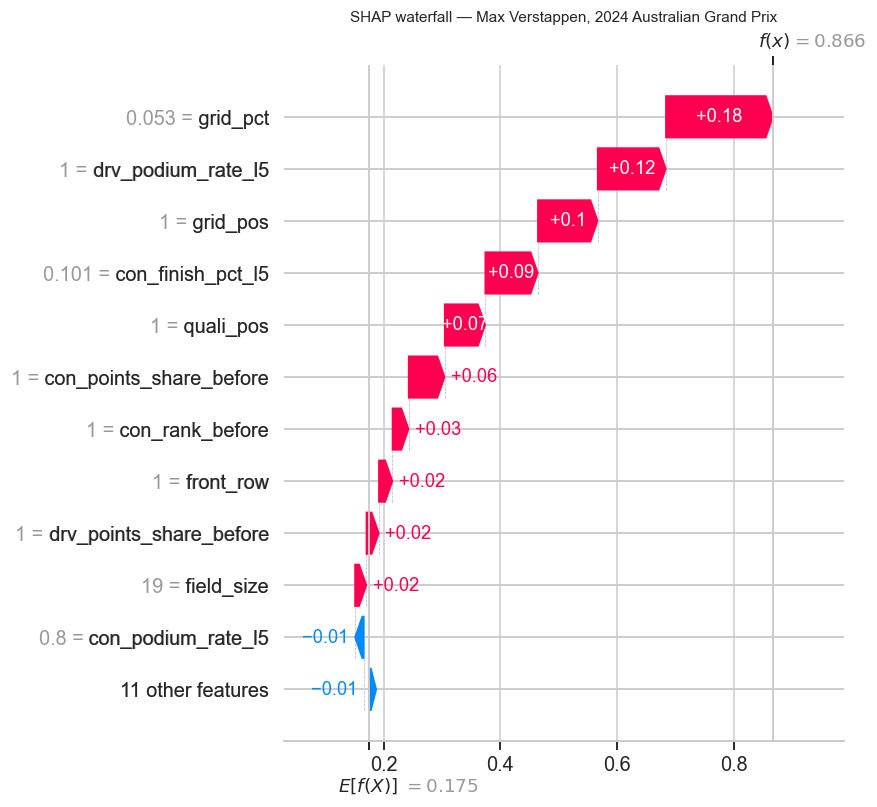

In [84]:
case_shap = explainer(X_test.loc[[case_id]], silent=True)
shap.plots.waterfall(case_shap[0], max_display=12, show=False)
plt.title(f"SHAP waterfall — {CASE_LABEL}", fontsize=10)
save_fig("xai_shap_waterfall")
plt.show()

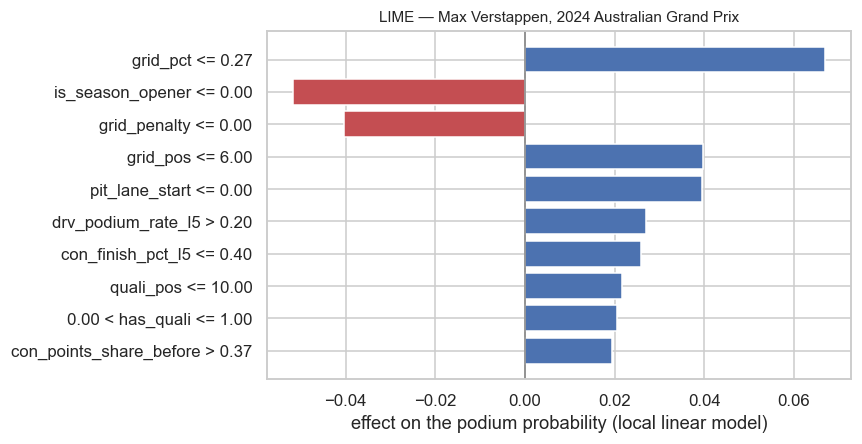

  rule that holds for this row  weight
              grid_pct <= 0.27   0.067
      is_season_opener <= 0.00  -0.052
          grid_penalty <= 0.00  -0.040
              grid_pos <= 6.00   0.040
        pit_lane_start <= 0.00   0.039
     drv_podium_rate_l5 > 0.20   0.027
     con_finish_pct_l5 <= 0.40   0.026
            quali_pos <= 10.00   0.022
      0.00 < has_quali <= 1.00   0.021
con_points_share_before > 0.37   0.019


In [85]:
try:
    from lime.lime_tabular import LimeTabularExplainer
    lime_train = SimpleImputer(strategy="median").fit_transform(X_train)     # LIME cannot handle NaN
    lime_explainer = LimeTabularExplainer(lime_train, feature_names=FEATURES, class_names=["no podium", "podium"],
                                          mode="classification", discretize_continuous=True, random_state=SEED)
    lime_exp = lime_explainer.explain_instance(
        X_test.loc[case_id].to_numpy(dtype=float),
        lambda data: np.column_stack([1 - predict_fn(data), predict_fn(data)]), num_features=10)
    lime_table = pd.DataFrame(lime_exp.as_list(), columns=["rule that holds for this row", "weight"])
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.barh(lime_table["rule that holds for this row"][::-1], lime_table["weight"][::-1],
            color=np.where(lime_table["weight"][::-1] > 0, "#4C72B0", "#C44E52"))
    ax.axvline(0, color="grey", lw=1); ax.set_xlabel("effect on the podium probability (local linear model)")
    ax.set_title(f"LIME — {CASE_LABEL}", fontsize=10)
    save_fig("xai_lime")
    plt.show()
    print(lime_table.round(3).to_string(index=False))
except ImportError:
    print("The 'lime' package is not installed here — the SHAP waterfall above is the local explanation.")

**Local explanation — Max Verstappen, 2024 Australian Grand Prix.** The model gave him a podium probability
of 0.87; he retired with a brake failure and was classified 19th.
- **SHAP waterfall:** starting from the average prediction (0.175), the biggest pushes are pole position
  (`grid_pct` +0.18, `grid_pos` +0.10, `quali_pos` +0.07), a podium in each of his last five races
  (`drv_podium_rate_l5` +0.12) and a team that had been finishing at the front (`con_finish_pct_l5` +0.09,
  constructor leading the championship +0.06). Nothing pulls the prediction down.
- **LIME** fits a small linear model around this one row and tells the same story: the front-of-grid
  rules (`grid_pct`, `grid_pos`, `quali_pos`), recent podium form and team form are the positive bars.
  Its two negative bars ("not a season opener", "no grid penalty") mean that the model gives a small bonus
  in those situations and this row does not get it. LIME is rougher than SHAP — it cuts each feature into
  bins and its bars do not add up exactly to the prediction, while SHAP values do.
- **Was the model wrong?** The prediction was reasonable given everything known before the start; the
  team's recent retirement rate was only 10%. A brake failure cannot be seen in pre-race data. This is
  the main limit of the task, not a defect of this model: even a perfect pre-race model will miss
  podiums lost to failures and accidents (14 pole-sitters missed the podium in the test seasons).

## 12. Inference function
`predict_podium(record)` takes the **pre-race** information of one driver in one race and returns the
podium probability from the final model. Fields that are unknown can simply be left out: the same
preprocessing pipeline that was fitted on the training seasons fills them in (median + "was missing" flag).
The function refuses post-race fields, so it cannot be used with leaked information by accident.

In [86]:
def predict_podium(record, model=None):
    """Podium probability for one driver in one race.

    record : dict of pre-race features (see FEATURES). Missing / unknown fields may be left out or None.
    Returns a probability between 0 and 1. Compare it with FINAL_THRESHOLD for a yes/no decision.
    """
    model = MODELS[BEST_NAME] if model is None else model
    record = {k: (np.nan if v is None else v) for k, v in record.items()}

    leaked = sorted(set(record) & set(POST_RACE))
    if leaked:
        raise ValueError(f"Post-race fields are not allowed at prediction time: {leaked}")
    unknown = sorted(set(record) - set(FEATURES))
    if unknown:
        raise ValueError(f"Unknown fields: {unknown}. Allowed fields: {FEATURES}")

    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}], dtype=float)
    # Fields that follow directly from others are filled in for the caller (all pre-race).
    grid_pos, field_size, quali_pos = row.at[0, "grid_pos"], row.at[0, "field_size"], row.at[0, "quali_pos"]
    if pd.isna(row.at[0, "grid_pct"]) and pd.notna(grid_pos) and pd.notna(field_size):
        row.at[0, "grid_pct"] = grid_pos / field_size
    if pd.isna(row.at[0, "front_row"]) and pd.notna(grid_pos):
        row.at[0, "front_row"] = float(grid_pos <= 2)
    if pd.isna(row.at[0, "grid_penalty"]) and pd.notna(grid_pos) and pd.notna(quali_pos):
        row.at[0, "grid_penalty"] = grid_pos - quali_pos
    row.at[0, "has_quali"] = float(pd.notna(quali_pos))
    return float(proba(model, row)[0])

FINAL_THRESHOLD = THRESHOLDS[BEST_NAME]
print("Final model:", BEST_NAME, "| decision threshold:", round(FINAL_THRESHOLD, 3))

Final model: logistic regression | decision threshold: 0.247


### 12.1 Demo on a complete record
A real row from the test seasons: the pole-sitter of the last race of 2024. The function must return
exactly the same probability as the model gives for that row in the test table.

In [87]:
last_race = test[test["date"] == test["date"].max()]
demo_row = last_race[last_race["grid_pos"] == 1].iloc[0]
demo_driver = names.loc[demo_row["driverId"]]
complete_record = demo_row[FEATURES].to_dict()

p_complete = predict_podium(complete_record)
assert np.isclose(p_complete, proba(final_model, X_test.loc[[demo_row.name]])[0])     # same as the test table

print(f"{demo_driver['forename']} {demo_driver['surname']} — {int(demo_row['year'])} {demo_row['name']}")
print(pd.Series(complete_record).round(3).to_string())
print(f"\nPodium probability: {p_complete:.3f}  ->  prediction: "
      f"{'PODIUM' if p_complete >= FINAL_THRESHOLD else 'no podium'}   |   actual: "
      f"{'PODIUM' if demo_row[TARGET] == 1 else 'no podium'}")

Lando Norris — 2024 Abu Dhabi Grand Prix
grid_pos                     1.000
grid_pct                     0.050
front_row                    1.000
pit_lane_start               0.000
field_size                  20.000
quali_pos                    1.000
q1_gap_pct                   0.456
grid_penalty                 0.000
has_quali                    1.000
drv_starts_before          126.000
drv_podium_rate_l5           0.200
drv_finish_pct_l5            0.287
drv_dnf_rate_l10             0.000
drv_circuit_podium_rate      0.000
con_podium_rate_l5           0.200
con_finish_pct_l5            0.303
con_dnf_rate_l10             0.000
drv_points_share_before      0.814
drv_rank_before              2.000
con_points_share_before      1.000
con_rank_before              1.000
is_season_opener             0.000

Podium probability: 0.646  ->  prediction: PODIUM   |   actual: PODIUM


**Result.** The function returns 0.646 for the pole-sitter, the same value the model gives for that row
in the test table (checked by the `assert`), which is above the 0.247 threshold → "podium". Correct.

### 12.2 Demo on partially-missing records
The same driver and race, with less and less information: (a) no qualifying data, (b) also no driver
history (as for a debutant), (c) only the grid position and field size. For contrast, (d) is a P18
starter with the same two fields. The function still answers in every case.

In [88]:
no_quali = {k: v for k, v in complete_record.items() if k not in FEATURE_GROUPS["qualifying"]}
rookie = {k: v for k, v in no_quali.items() if k not in FEATURE_GROUPS["driver_form"]
          and k not in ["drv_points_share_before", "drv_rank_before"]}
grid_only = {"grid_pos": complete_record["grid_pos"], "field_size": complete_record["field_size"]}

demo = pd.DataFrame([
    {"record": "complete", "fields given": len(complete_record), "probability": p_complete},
    {"record": "(a) no qualifying data", "fields given": len(no_quali), "probability": predict_podium(no_quali)},
    {"record": "(b) no qualifying + no driver history", "fields given": len(rookie), "probability": predict_podium(rookie)},
    {"record": "(c) only grid position and field size", "fields given": 2, "probability": predict_podium(grid_only)},
    {"record": "(d) only grid position and field size, P18 of 20", "fields given": 2,
     "probability": predict_podium({"grid_pos": 18, "field_size": 20})},
])
demo["prediction"] = np.where(demo["probability"] >= FINAL_THRESHOLD, "PODIUM", "no podium")

try:
    predict_podium({**complete_record, "points": 25})          # a post-race field must be refused
except ValueError as err:
    print("Leakage guard works ->", err, "\n")
demo.round(3)

Leakage guard works -> Post-race fields are not allowed at prediction time: ['points'] 



,record,fields given,probability,prediction
0,complete,22,0.646,PODIUM
1,(a) no qualifying data,18,0.597,PODIUM
2,(b) no qualifying + no driver history,11,0.515,PODIUM
3,(c) only grid position and field size,2,0.135,no podium
4,"(d) only grid position and field size, P18 of 20",2,0.002,no podium


**Result.**
- **(a) No qualifying data: 0.646 → 0.597.** The prediction barely moves: the grid position carries almost
  the same information, and "qualifying missing" is a situation the model saw in 46% of its training rows.
- **(b) Also no driver history: 0.515.** Still a podium prediction, now resting on the grid slot and the
  team's form and standing.
- **(c) Only grid position and field size: 0.135.** The function answers, but the answer is too low —
  real pole-sitters reach the podium 64% of the time (§4.3). Every unknown field was filled with the
  training median, which describes a *typical midfield entry* (no recent podiums, 12th in the standings).
  The model therefore sees "a midfield driver who happens to be on pole", a combination that hardly exists
  in the training data. (d) shows the grid position is still used: the same two fields for P18 give 0.002.
- **Take-away:** the function handles missing fields without errors, and it is reliable when the missing
  pattern is one that occurred in training (old seasons without qualifying, debutants). The fewer fields
  are given, the more the prediction is "an average driver in that grid slot" rather than this driver.
- The guard rejects post-race fields (`points`), so leaked information cannot enter by accident.

## 13. Summary and limitations

**What we built.** A leakage-safe table with one row per driver per race (24,628 rows, 22 pre-race
features in 5 groups), a time-based split (train 1981–2019, validation 2020–2021, test 2022–2024), four
trained models plus a no-learning rule, and an inference function.

| Question | Answer | Where |
|---|---|---|
| How good is the final model? | Logistic regression: test PR-AUC 0.72, ROC-AUC 0.94, F1 0.68 | §9.8 |
| Does it beat the simplest rule? | Yes: +0.07 PR-AUC over "starts in the top 3" (95% range +0.03 to +0.12) | §9.9 |
| Do complex models help? | No: random forest, gradient boosting and the network are within noise of the baseline | §9.7, §9.9 |
| Which features matter? | The starting order (grid + qualifying) is the core; form and standings add 0.04–0.09 | §10 |
| What does the model rely on? | Grid position first, then recent driver and team form | §11 |

**Primary / secondary metric.** PR-AUC is primary because podiums are only ~15% of rows; F1 at a
validation-chosen threshold is secondary because it scores the actual yes/no decision.

**Known limitations**
- **Qualifying-coverage drift.** Qualifying data is absent before 1994 and complete only from 2003, so
  46% of training rows have imputed qualifying features, while validation and test have almost none.
- **Era sensitivity.** The model is trained on 1981–2019 and used on 2022–2024. Field sizes, reliability
  and rules changed (train PR-AUC is 0.61 over all seasons but 0.70 on 2010–2019). Older data helped the
  tree models but describes a different sport.
- **Small validation and test sets.** 39 and 68 races. Differences below ~0.02 PR-AUC are not
  meaningful, which is why no complex model could be shown to beat the baseline.
- **Unpredictable events.** Failures, crashes, weather and safety cars are not in pre-race data (§11.3).
- **Team identity.** Form follows `constructorId`, so a renamed team (e.g. AlphaTauri → RB) starts with
  no history.
- **Partially-missing records.** Missing fields are filled with typical values, so sparse records are
  pulled towards a midfield profile (§12.2).
- **Shared drives.** 5 of 1,114 races have a number of podium rows different from 3 after the
  one-row-per-driver rule (§3.8); all of them are before the training window.
- **Threshold drift.** The F1-optimal threshold chosen on 2020–2021 gives higher recall and lower
  precision on 2022–2024.
- **Explanations are not causal.** Importance and SHAP values describe what the model uses, not what
  makes a driver finish on the podium.